In [1]:
import os
import sys
import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append("../../../1_allele_collection/2_analysis")
from plot_utils import *

sys.path.append("../..")
from analyses_plot_utils import *

In [2]:
inputs_dir = "../1_inputs/sqY2H"
outputs_dir = "../3_outputs/sqY2H"
meta_output_dir = "../../../1_allele_collection/3_outputs"

In [3]:
allele_coll = pd.read_csv(f"{meta_output_dir}/varchamp_clean_allele_collection_clinvar_gnomad_dbnsfp_struc_scores_OMIM_MOI_disease_modules.tsv", sep="\t")
omim_dict = allele_coll.set_index('gene_variant')['OMIM_IDs'].to_dict()
omim_dict

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_27104/328160500.py:1: DtypeWarning: Columns (104,106,139,142,158,159,161,162,164,166,188,190,191,193,194,196,197,200,211,218,219,231,232,242,243,244,255,256,259,260) have mixed types. Specify dtype option on import or set low_memory=False.
  allele_coll = pd.read_csv(f"{meta_output_dir}/varchamp_clean_allele_collection_clinvar_gnomad_dbnsfp_struc_scores_OMIM_MOI_disease_modules.tsv", sep="\t")


{'GBA1_Val54Leu': nan,
 'GBA1_Leu224Phe': nan,
 'GBA1_Arg296Gln': "['608013', '230800', '230900', '231000', '231005', '168600', '230800']",
 'GBA1_Leu483Pro': "['230900', '230800', '231000', '168600', '608013', '230800', '230900', '231000', '231005', '127750']",
 'GBA1_Arg87Trp': "['230800', '127750', '168600']",
 'GBA1_Arg159Gln': "['230800', '608013', '231005', '230800', '230900', '231000']",
 'GBA1_Lys196Gln': "['230800']",
 'GBA1_Arg209Cys': "['230800', '230900', '231005', '231000', '230800']",
 'GBA1_Trp223Arg': "['230800', '230900', '231000']",
 'GBA1_Arg202Gln': nan,
 'GBA1_Phe252Ile': "['231000', '230900', '230800', '127750']",
 'GBA1_Asn227Ser': "['230800', '231000', '230900', '230800', '230900', '231000', '231005']",
 'GBA1_His294Gln': "['231005', '230800', '230900', '231000', '230800', '608013']",
 'GBA1_Phe290Leu': "['608013']",
 'GBA1_Pro328Leu': "['230800']",
 'GBA1_Phe255Val': "['230800']",
 'GBA1_Thr362Ile': "['230800', '230900']",
 'GBA1_Asp354His': nan,
 'GBA1_His350A

In [4]:
scores = pl.read_csv(f"{outputs_dir}/4_automated_normalized_consensus_scores.csv")
scores = scores.drop_nulls(subset=["summed_consensus_score"])

# keep only scores where there is at least one matched reference-variant set
orfs_with_alleles = scores.filter(pl.col("db_mut_id") != 0).select("db_orf_id").unique().to_series().to_list()
orfs = scores.filter(pl.col("db_mut_id") == 0).select("db_orf_id").unique().to_series().to_list()

complete_orf_pairs = [i for i in orfs if i in orfs_with_alleles]
scores = scores.filter(pl.col("db_orf_id").is_in(complete_orf_pairs))
genes = scores.select("db_orf_id").to_series().unique().to_list()

# map variant classes

classes_df = pl.read_csv(f"{outputs_dir}/*_variants_perturbation_scores_automated_annotated_lwh1.csv")

# Join scores with variant classes on allele_0
scores = scores.join(
    classes_df.select(["allele_0", "variant_class_log2fc"]), 
    on="allele_0", 
    how="left"
)

# Remove WT and calculate log2fc and perturbed status
scores = scores.filter(pl.col("db_mut_id") != 0).with_columns([
    ((pl.col("summed_consensus_score_normalized") + 0.0001) / 
     (pl.col("wt_summed_score_normalized") + 0.0001)).log(2).alias("log2fc")
]).with_columns([
    (pl.col("log2fc") <= -1).alias("perturbed")
])

# Map OMIM IDs to scores using allele_0 column
scores = scores.with_columns([
    pl.col("allele_0").map_elements(
        lambda x: omim_dict.get(x, None) if pd.notna(omim_dict.get(x, None)) else None,
        return_dtype=pl.Utf8
    ).alias("OMIM_IDs")
])

scores

ad_orf_id,db_orf_id,db_mut_id,retest_batch,n_conditions,summed_consensus_score,lwh1_consensus_score,summed_consensus_score_normalized,lwh1_consensus_score_normalized,wt_summed_score,wt_summed_score_normalized,wt_lwh1_score,wt_lwh1_score_normalized,condition_name,assay_id,ppi_group,seq_ad,seq_db,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,variant_class_log2fc,log2fc,perturbed,OMIM_IDs
i64,i64,i64,str,i64,f64,f64,f64,f64,f64,f64,f64,f64,str,i64,str,i64,i64,str,str,str,str,str,str,str,f64,f64,str,str,f64,bool,str
70054,52920,2673,"""VUSAPWT6B1""",4,1978.762489,513.191523,0.659587,0.684255,1569.756592,0.523252,522.783026,0.697044,"""LWA""",6,"""70054_52920_2673_VUSAPWT6B1""",1,1,"""RASSF3""","""LITAF""","""Leu122Val""","""364C>G""","""ENSG00000189067""","""Edgotyping3""","""1_Pathogenic""",null,null,"""LITAF_Leu122Val""","""E""",0.334001,false,"""['601098']"""
71963,2713,200856,"""VUSAPWT6B1""",4,1790.360197,428.82322,0.596787,0.571764,721.665387,0.240555,null,null,"""LWA""",6,"""71963_2713_200856_VUSAPWT6B1""",1,1,"""MBD3L1""","""MLH1""","""Asp304Gly""","""911A>G""","""ENSG00000076242""","""CEGS2""","""3_Conflicting""",6.8405e-7,1.0,"""MLH1_Asp304Gly""","""E""",1.31049,false,null
14387,7652,1817,"""VUSAPWT6B1""",4,785.530414,363.665371,0.261843,0.484887,2167.000414,0.722333,554.717016,0.739623,"""LWH25""",6,"""14387_7652_1817_VUSAPWT6B1""",1,1,"""CENPP""","""STXBP1""","""Arg305Gln""","""914G>A""","""ENSG00000136854""","""Edgotyping3""","""4_VUS""",0.000005,2.0,"""STXBP1_Arg305Gln""","""E""",-1.463609,true,null
3522,3020,214471,"""VUSAPWT1B2""",4,1132.796122,576.731398,0.377599,0.768975,1461.629462,0.48721,599.514081,0.799352,"""LWA""",1,"""3522_3020_214471_VUSAPWT1B2""",1,1,"""NCK2""","""CHN1""","""Glu313Lys""","""937G>A""","""ENSG00000128656""","""CEGS2""","""1_Pathogenic""",null,null,"""CHN1_Glu313Lys""","""QW""",-0.367603,false,"""['604356']"""
2831,6408,215946,"""VUSAPWT6B1""",4,250.536605,125.834316,0.083512,0.167779,1225.018665,0.40834,502.350671,0.669801,"""LWH1""",6,"""2831_6408_215946_VUSAPWT6B1""",1,1,"""TMEM80""","""IER3IP1""","""Leu78Pro""","""233T>C""","""ENSG00000134049""","""CEGS2""","""1_Pathogenic""",null,2.0,"""IER3IP1_Leu78Pro""","""E""",-2.288337,true,"""['614231']"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
6446,4062,201422,"""VUSAPWT6B1""",4,299.523208,null,0.099841,null,1256.404284,0.418801,414.013413,0.552018,"""LWH1""",6,"""6446_4062_201422_VUSAPWT6B1""",1,1,"""ERGIC3""","""PLP1""","""Thr43Ile""","""128C>T""","""ENSG00000123560""","""CEGS2""","""1_Pathogenic""",null,1.0,"""PLP1_Thr43Ile""","""E""",-2.067461,true,"""['312080']"""
100016069,100016069,2641,"""VUSAPWT1B1""",4,765.782366,228.563076,0.255261,0.304751,1651.519672,0.550507,541.218652,0.721625,"""LWA""",1,"""100016069_100016069_2641_VUSAP…",1,1,"""KCNJ2""","""KCNJ2""","""Gly300Asp""","""899G>A""","""ENSG00000123700""","""Edgotyping3""","""1_Pathogenic""",null,2.0,"""KCNJ2_Gly300Asp""","""E""",-1.108485,true,"""['170390', '609622', '170390']"""
7675,7675,202585,"""VUSAPWT1B2""",4,1574.94548,576.61408,0.524982,0.768819,2287.91054,0.762637,616.422251,0.821896,"""LWH1""",1,"""7675_7675_202585_VUSAPWT1B2""",1,1,"""NMNAT1""","""NMNAT1""","""Glu257Lys""","""769G>A""","""ENSG00000173614""","""CEGS2""","""1_Pathogenic""",0.0010295,2.0,"""NMNAT1_Glu257Lys""","""QW""",-0.538643,false,"""['608553']"""


In [5]:
# remove WT

scores = scores.filter(pl.col("db_mut_id") != 0)

# First, get edgetic variants
edgetic_variants = scores.filter(pl.col("variant_class_log2fc") == "E")

# Group by gene (symbol) and get variants with multiple edgetic alleles
genes_with_multiple_edgetic = (edgetic_variants
                              .group_by("symbol")
                              .agg(pl.col("aa_change").n_unique().alias("n_edgetic_variants"))
                              .filter(pl.col("n_edgetic_variants") > 1)
                              .select("symbol")
                              .to_series().to_list())

print(f"Found {len(genes_with_multiple_edgetic)} genes with multiple edgetic variants")

# Now analyze perturbation profiles for each gene
perturbation_profiles = {}

for gene in genes_with_multiple_edgetic:
    gene_edgetic_variants = edgetic_variants.filter(pl.col("symbol") == gene)
    
    # Get the edge-level data for this gene
    gene_scores = scores.filter(pl.col("symbol") == gene)
    
    # # Calculate perturbation status for each edge
    # gene_scores = gene_scores.with_columns([
    #     (pl.col("summed_consensus_score_normalized").log() - 
    #      pl.col("wt_summed_score_normalized").log()).alias("log2fc_edge"),
    #     (pl.col("summed_consensus_score_normalized") < 
    #      pl.col("wt_summed_score_normalized") * 0.5).alias("perturbed")  # 50% threshold
    # ])
    
    # Get perturbation patterns for each variant
    variant_profiles = {}
    for row in gene_edgetic_variants.iter_rows(named=True):
        variant_id = row["aa_change"]
        allele_id = row["allele_0"]
        
        # Get edges for this variant
        variant_edges = gene_scores.filter(pl.col("allele_0") == allele_id)
        
        # Get list of perturbed interactions (ad_orf_id)
        perturbed_edges = (variant_edges
                          .filter(pl.col("perturbed") == True)
                          .select("ad_orf_id")
                          .to_series().to_list())
        
        variant_profiles[variant_id] = set(perturbed_edges)
    
    perturbation_profiles[gene] = variant_profiles

# Compare profiles between variants within each gene
differential_edgetic_variants = {}

for gene, profiles in perturbation_profiles.items():
    variants = list(profiles.keys())
    gene_results = []
    
    for i in range(len(variants)):
        for j in range(i+1, len(variants)):
            var1, var2 = variants[i], variants[j]
            profile1, profile2 = profiles[var1], profiles[var2]
            
            # Calculate overlap and differences
            intersection = profile1.intersection(profile2)
            var1_only = profile1 - profile2
            var2_only = profile2 - profile1
            
            # Calculate similarity metrics
            union = profile1.union(profile2)
            jaccard = len(intersection) / len(union) if len(union) > 0 else 0
            
            gene_results.append({
                'gene': gene,
                'variant1': var1,
                'variant2': var2,
                'shared_perturbed': list(intersection),
                'variant1_only_perturbed': list(var1_only),
                'variant2_only_perturbed': list(var2_only),
                'n_shared': len(intersection),
                'n_var1_only': len(var1_only),
                'n_var2_only': len(var2_only),
                'jaccard_similarity': jaccard,
                'total_var1_perturbed': len(profile1),
                'total_var2_perturbed': len(profile2)
            })
    
    differential_edgetic_variants[gene] = gene_results

# Convert to DataFrame for easier analysis
all_comparisons = []
for gene, comparisons in differential_edgetic_variants.items():
    all_comparisons.extend(comparisons)

comparison_df = pl.DataFrame(all_comparisons)

# Filter for variants with different profiles (low Jaccard similarity and some unique perturbations)
differential_variants = comparison_df.filter(
    (pl.col("jaccard_similarity") < 0.7) &  # Less than 70% similarity
    (pl.col("n_var1_only") > 0) &           # Variant 1 has unique perturbations
    (pl.col("n_var2_only") > 0) #&           # Variant 2 has unique perturbations
    # (pl.col("n_shared") > 0)                 # But they share some perturbations
)

print(f"\nFound {differential_variants.shape[0]} variant pairs with differential edgetic profiles")
print(f"Involving {differential_variants.select('gene').n_unique()} genes")

# Display results
print("\nDifferential edgetic variant pairs:")
for row in differential_variants.iter_rows(named=True):
    print(f"\nGene: {row['gene']}")
    print(f"  {row['variant1']} vs {row['variant2']}")
    print(f"  Shared perturbed edges: {row['n_shared']}")
    print(f"  {row['variant1']} unique: {row['n_var1_only']}")
    print(f"  {row['variant2']} unique: {row['n_var2_only']}")
    print(f"  Jaccard similarity: {row['jaccard_similarity']:.3f}")

differential_variants

Found 20 genes with multiple edgetic variants

Found 169 variant pairs with differential edgetic profiles
Involving 12 genes

Differential edgetic variant pairs:

Gene: TPM1
  Asp230Asn vs Ala63Val
  Shared perturbed edges: 0
  Asp230Asn unique: 1
  Ala63Val unique: 1
  Jaccard similarity: 0.000

Gene: TPM1
  Asp230Asn vs Glu54Lys
  Shared perturbed edges: 0
  Asp230Asn unique: 1
  Glu54Lys unique: 1
  Jaccard similarity: 0.000

Gene: TPM1
  Ala63Val vs Ala239Thr
  Shared perturbed edges: 0
  Ala63Val unique: 1
  Ala239Thr unique: 1
  Jaccard similarity: 0.000

Gene: TPM1
  Ala63Val vs Ile172Thr
  Shared perturbed edges: 0
  Ala63Val unique: 1
  Ile172Thr unique: 1
  Jaccard similarity: 0.000

Gene: TPM1
  Glu54Lys vs Ala239Thr
  Shared perturbed edges: 0
  Glu54Lys unique: 1
  Ala239Thr unique: 1
  Jaccard similarity: 0.000

Gene: TPM1
  Glu54Lys vs Ile172Thr
  Shared perturbed edges: 0
  Glu54Lys unique: 1
  Ile172Thr unique: 1
  Jaccard similarity: 0.000

Gene: TMEM43
  Glu142Lys vs

gene,variant1,variant2,shared_perturbed,variant1_only_perturbed,variant2_only_perturbed,n_shared,n_var1_only,n_var2_only,jaccard_similarity,total_var1_perturbed,total_var2_perturbed
str,str,str,list[i64],list[i64],list[i64],i64,i64,i64,f64,i64,i64
"""TPM1""","""Asp230Asn""","""Ala63Val""",[],[4621],[6811],0,1,1,0.0,1,1
"""TPM1""","""Asp230Asn""","""Glu54Lys""",[],[4621],[6811],0,1,1,0.0,1,1
"""TPM1""","""Ala63Val""","""Ala239Thr""",[],[6811],[4621],0,1,1,0.0,1,1
"""TPM1""","""Ala63Val""","""Ile172Thr""",[],[6811],[4621],0,1,1,0.0,1,1
"""TPM1""","""Glu54Lys""","""Ala239Thr""",[],[6811],[4621],0,1,1,0.0,1,1
…,…,…,…,…,…,…,…,…,…,…,…
"""LITAF""","""Asn30Tyr""","""Ala111Gly""",[],[1863],[11132],0,1,1,0.0,1,1
"""LITAF""","""Asn30Tyr""","""Pro84Leu""",[],[1863],"[10064, 1235, … 2845]",0,1,5,0.0,1,5
"""LITAF""","""Ala111Gly""","""Pro84Leu""",[],[11132],"[10064, 1235, … 2845]",0,1,5,0.0,1,5


In [6]:
allele_coll_raw = pd.read_csv(f"{meta_output_dir}/varchamp_seq_confirm_alleles_clinvar_gnomad.tsv", sep="\t")
allele_coll_raw[allele_coll_raw.symbol == 'PLP1'].aa_change.unique()

array(['Pro15Leu', 'Leu87Pro', 'Trp128Leu', 'Ala213Glu', 'Thr43Ile',
       'Gly74Arg', 'Trp128Arg', 'Thr121Ile', 'Thr147Pro', 'Asp168His',
       'Ile152Thr', 'Ser135Phe', 'Cys193Tyr', 'Pro181Ser', 'Val184Phe',
       'Leu189Pro', 'Gly186Cys'], dtype=object)

In [8]:
# remove WT
scores = scores.filter(pl.col("db_mut_id") != 0)

# First, get edgetic variants
edgetic_variants = scores.filter(pl.col("variant_class_log2fc") == "E")

# Group by gene (symbol) and get variants with multiple edgetic alleles
genes_with_multiple_edgetic = (edgetic_variants
                              .group_by("symbol")
                              .agg(pl.col("aa_change").n_unique().alias("n_edgetic_variants"))
                              .filter(pl.col("n_edgetic_variants") > 1)
                              .select("symbol")
                              .to_series().to_list())

print(f"Found {len(genes_with_multiple_edgetic)} genes with multiple edgetic variants")

# Now analyze perturbation profiles for each gene
perturbation_profiles = {}
variant_omim_mapping = {}

for gene in genes_with_multiple_edgetic:
    gene_edgetic_variants = edgetic_variants.filter(pl.col("symbol") == gene)
    
    # Get the edge-level data for this gene
    gene_scores = scores.filter(pl.col("symbol") == gene)
    
    # Get perturbation patterns for each variant
    variant_profiles = {}
    variant_omim = {}
    
    for row in gene_edgetic_variants.iter_rows(named=True):
        variant_id = row["aa_change"]
        allele_id = row["allele_0"]
        omim_id = row["OMIM_IDs"]
        
        # Get edges for this variant
        variant_edges = gene_scores.filter(pl.col("allele_0") == allele_id)
        
        # Get list of perturbed interactions (ad_orf_id)
        perturbed_edges = (variant_edges
                          .filter(pl.col("perturbed") == True)
                          .select("ad_orf_id")
                          .to_series().to_list())
        
        variant_profiles[variant_id] = set(perturbed_edges)
        variant_omim[variant_id] = omim_id
    
    perturbation_profiles[gene] = variant_profiles
    variant_omim_mapping[gene] = variant_omim

# Compare profiles between variants within each gene
differential_edgetic_variants = {}

for gene, profiles in perturbation_profiles.items():
    variants = list(profiles.keys())
    gene_results = []
    
    for i in range(len(variants)):
        for j in range(i+1, len(variants)):
            var1, var2 = variants[i], variants[j]
            profile1, profile2 = profiles[var1], profiles[var2]
            
            # Get OMIM IDs for comparison
            omim1 = variant_omim_mapping[gene][var1]
            omim2 = variant_omim_mapping[gene][var2]

            # Helper function to check if OMIM is valid (not None, not ['None'], not empty)
            def is_valid_omim(omim_val):
                if omim_val is None:
                    return False
                if isinstance(omim_val, str):
                    # Handle string representation of lists like "['312920', '312080']"
                    if omim_val.startswith('[') and omim_val.endswith(']'):
                        try:
                            import ast
                            omim_list = ast.literal_eval(omim_val)
                            return len(omim_list) > 0 and not (len(omim_list) == 1 and str(omim_list[0]).lower() == 'none')
                        except:
                            return omim_val.lower() != 'none' and omim_val.strip() != ''
                    else:
                        return omim_val.lower() != 'none' and omim_val.strip() != ''
                if isinstance(omim_val, list):
                    return len(omim_val) > 0 and not (len(omim_val) == 1 and str(omim_val[0]).lower() == 'none')
                return False

            # Helper function to convert OMIM to set for comparison
            def omim_to_set(omim_val):
                if omim_val is None:
                    return set()
                if isinstance(omim_val, str):
                    # Handle string representation of lists like "['312920', '312080']"
                    if omim_val.startswith('[') and omim_val.endswith(']'):
                        try:
                            import ast
                            omim_list = ast.literal_eval(omim_val)
                            return set(str(x) for x in omim_list if str(x).lower() != 'none')
                        except:
                            return {omim_val} if omim_val.lower() != 'none' else set()
                    else:
                        return {omim_val} if omim_val.lower() != 'none' else set()
                if isinstance(omim_val, list):
                    return set(str(x) for x in omim_val if str(x).lower() != 'none')
                return set()

            # Check if OMIM IDs are completely different (no overlap)
            valid_omim1 = is_valid_omim(omim1)
            valid_omim2 = is_valid_omim(omim2)

            if valid_omim1 and valid_omim2:
                omim_set1 = omim_to_set(omim1)
                omim_set2 = omim_to_set(omim2)
                # Check if they have NO overlap (intersection is empty)
                different_omim = len(omim_set1.intersection(omim_set2)) == 0
            else:
                different_omim = False

            # Calculate overlap and differences
            intersection = profile1.intersection(profile2)
            var1_only = profile1 - profile2
            var2_only = profile2 - profile1
            
            # Calculate similarity metrics
            union = profile1.union(profile2)
            jaccard = len(intersection) / len(union) if len(union) > 0 else 0
            
            gene_results.append({
                'gene': gene,
                'variant1': var1,
                'variant2': var2,
                'omim1': omim1,
                'omim2': omim2,
                'different_omim': different_omim,
                'shared_perturbed': list(intersection),
                'variant1_only_perturbed': list(var1_only),
                'variant2_only_perturbed': list(var2_only),
                'n_shared': len(intersection),
                'n_var1_only': len(var1_only),
                'n_var2_only': len(var2_only),
                'jaccard_similarity': jaccard,
                'total_var1_perturbed': len(profile1),
                'total_var2_perturbed': len(profile2)
            })
    
    differential_edgetic_variants[gene] = gene_results

# Convert to DataFrame for easier analysis
all_comparisons = []
for gene, comparisons in differential_edgetic_variants.items():
    all_comparisons.extend(comparisons)

comparison_df = pl.DataFrame(all_comparisons)

# Filter for variants with different profiles (low Jaccard similarity and some unique perturbations) AND different OMIM IDs
differential_variants = comparison_df.filter(
    # (pl.col("jaccard_similarity") < 0.7) &  # Less than 70% similarity
    (pl.col("n_var1_only") > 0) &           # Variant 1 has unique perturbations
    (pl.col("n_var2_only") > 0) &           # Variant 2 has unique perturbations
    (pl.col("different_omim") == True) #&
    # (pl.col("n_shared") > 0) 
)

print(f"\nFound {differential_variants.shape[0]} variant pairs with differential edgetic profiles AND different OMIM IDs")
print(f"Involving {differential_variants.select('gene').n_unique()} genes")

# Display results with interactor names
print("\nDifferential edgetic variant pairs with different OMIM IDs:")
for row in differential_variants.iter_rows(named=True):
    print(f"\nGene: {row['gene']}")
    print(f"  {row['variant1']} (OMIM: {row['omim1']}) vs {row['variant2']} (OMIM: {row['omim2']})")
    print(f"  Shared perturbed edges: {row['n_shared']}")
    print(f"  {row['variant1']} unique: {row['n_var1_only']}")
    print(f"  {row['variant2']} unique: {row['n_var2_only']}")
    print(f"  Jaccard similarity: {row['jaccard_similarity']:.3f}")
    
    # Get interactor names for shared and unique perturbations
    gene_data = scores.filter(pl.col("symbol") == row['gene'])
    
    # Shared perturbed interactors
    if row['shared_perturbed']:
        shared_interactors = (gene_data
                             .filter(pl.col("ad_orf_id").is_in(row['shared_perturbed']))
                             .select("ad_symbol")
                             .unique()
                             .to_series().to_list())
        print(f"  Shared perturbed interactors: {', '.join(shared_interactors)}")
    
    # Variant 1 unique perturbed interactors
    if row['variant1_only_perturbed']:
        var1_unique_interactors = (gene_data
                                  .filter(pl.col("ad_orf_id").is_in(row['variant1_only_perturbed']))
                                  .select("ad_symbol")
                                  .unique()
                                  .to_series().to_list())
        print(f"  {row['variant1']} unique perturbed interactors: {', '.join(var1_unique_interactors)}")
    
    # Variant 2 unique perturbed interactors
    if row['variant2_only_perturbed']:
        var2_unique_interactors = (gene_data
                                  .filter(pl.col("ad_orf_id").is_in(row['variant2_only_perturbed']))
                                  .select("ad_symbol")
                                  .unique()
                                  .to_series().to_list())
        print(f"  {row['variant2']} unique perturbed interactors: {', '.join(var2_unique_interactors)}")

differential_variants

Found 20 genes with multiple edgetic variants

Found 3 variant pairs with differential edgetic profiles AND different OMIM IDs
Involving 1 genes

Differential edgetic variant pairs with different OMIM IDs:

Gene: PLP1
  Val184Phe (OMIM: ['312080']) vs Ser135Phe (OMIM: ['312920'])
  Shared perturbed edges: 1
  Val184Phe unique: 2
  Ser135Phe unique: 1
  Jaccard similarity: 0.250
  Shared perturbed interactors: PTPRN
  Val184Phe unique perturbed interactors: TMEM52B, NRG1
  Ser135Phe unique perturbed interactors: FNDC9

Gene: PLP1
  Ser135Phe (OMIM: ['312920']) vs Asp168His (OMIM: ['312080'])
  Shared perturbed edges: 1
  Ser135Phe unique: 1
  Asp168His unique: 2
  Jaccard similarity: 0.250
  Shared perturbed interactors: PTPRN
  Ser135Phe unique perturbed interactors: FNDC9
  Asp168His unique perturbed interactors: TMEM52B, CLDN20

Gene: PLP1
  Ser135Phe (OMIM: ['312920']) vs Thr43Ile (OMIM: ['312080'])
  Shared perturbed edges: 1
  Ser135Phe unique: 1
  Thr43Ile unique: 5
  Jaccard sim

gene,variant1,variant2,omim1,omim2,different_omim,shared_perturbed,variant1_only_perturbed,variant2_only_perturbed,n_shared,n_var1_only,n_var2_only,jaccard_similarity,total_var1_perturbed,total_var2_perturbed
str,str,str,str,str,bool,list[i64],list[i64],list[i64],i64,i64,i64,f64,i64,i64
"""PLP1""","""Val184Phe""","""Ser135Phe""","""['312080']""","""['312920']""",true,[4946],"[14232, 56139]",[1172],1,2,1,0.25,3,2
"""PLP1""","""Ser135Phe""","""Asp168His""","""['312920']""","""['312080']""",true,[4946],[1172],"[12825, 56139]",1,1,2,0.25,2,3
"""PLP1""","""Ser135Phe""","""Thr43Ile""","""['312920']""","""['312080']""",true,[4946],[1172],"[56139, 70989, … 11130]",1,1,5,0.142857,2,6


# First, separate chains into objects
split_chains

# Color chain A red
color red, chain B

# Show residue 41 on chain A as blue spheres
show spheres, (chain A and resi 134)
color magenta, (chain A and resi 134)

# Show residues 134, 203, 219 on chain A as magenta spheres
show spheres, (chain A and resi 41+203+219)
color cyan, (chain A and resi 41+203+219)


In [7]:
scores_pd = scores.to_pandas()

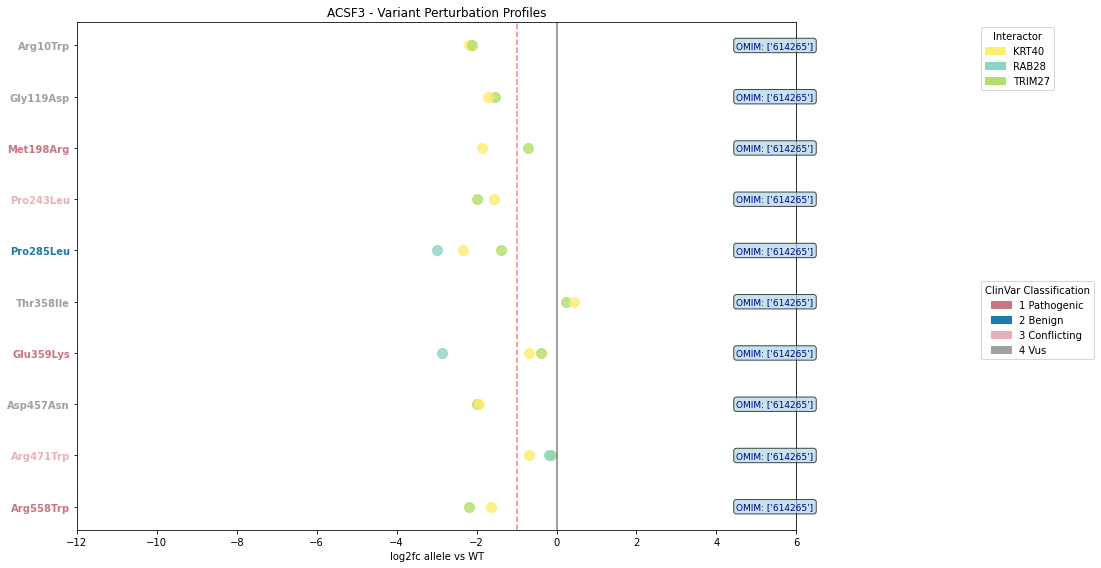


ACSF3 summary:
  Number of variants: 10
  Number of interactors: 3
  Total interactions: 23


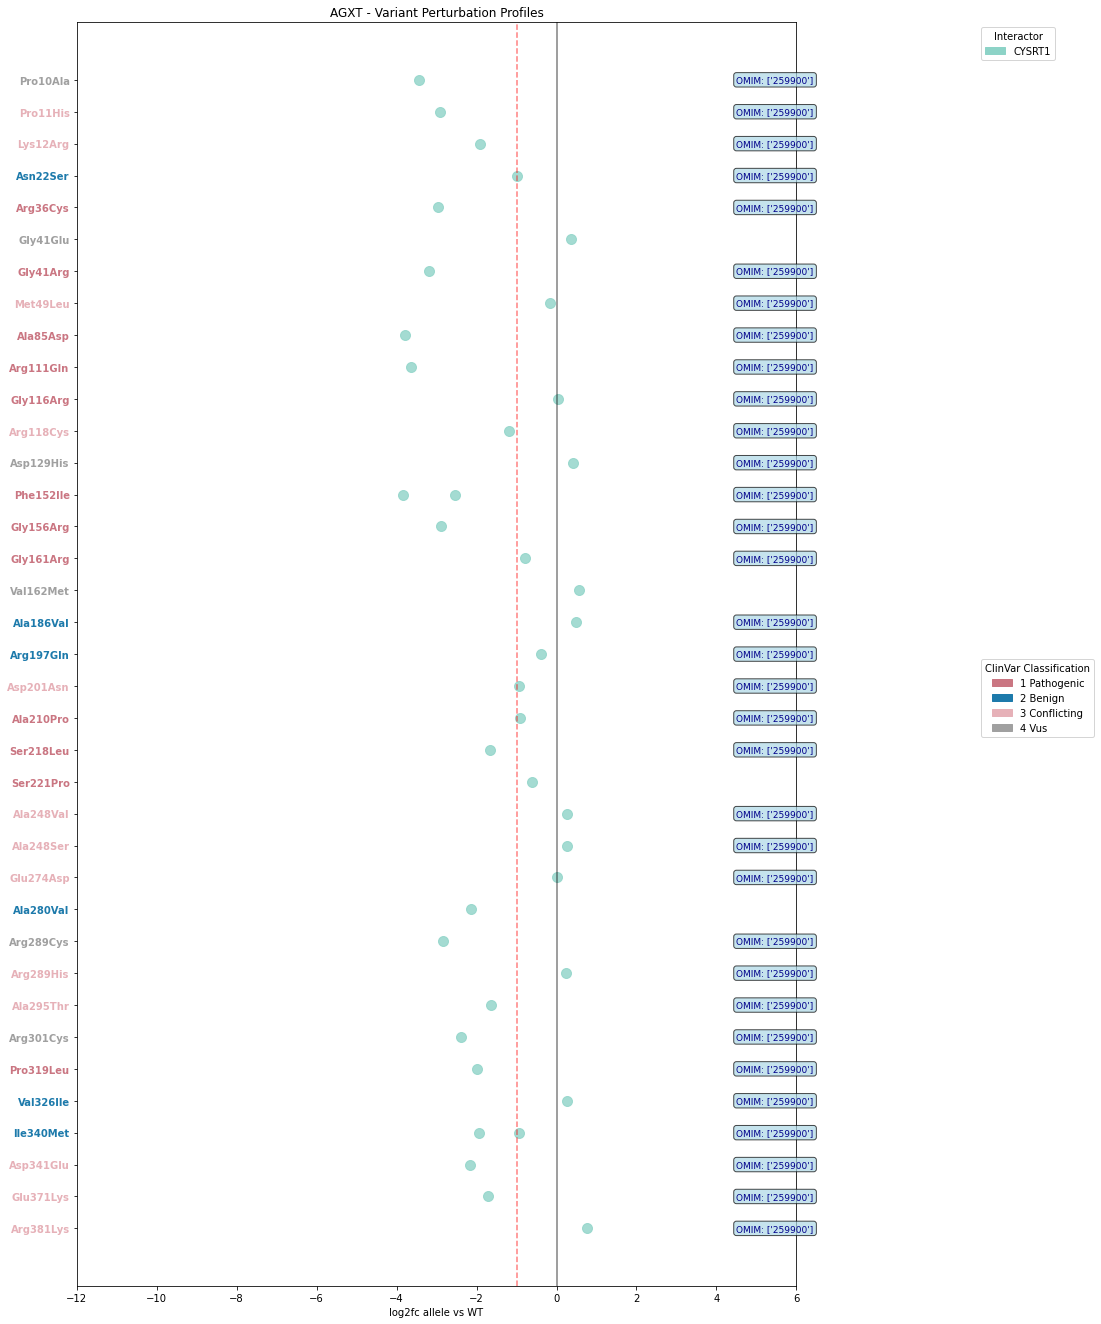


AGXT summary:
  Number of variants: 37
  Number of interactors: 1
  Total interactions: 39


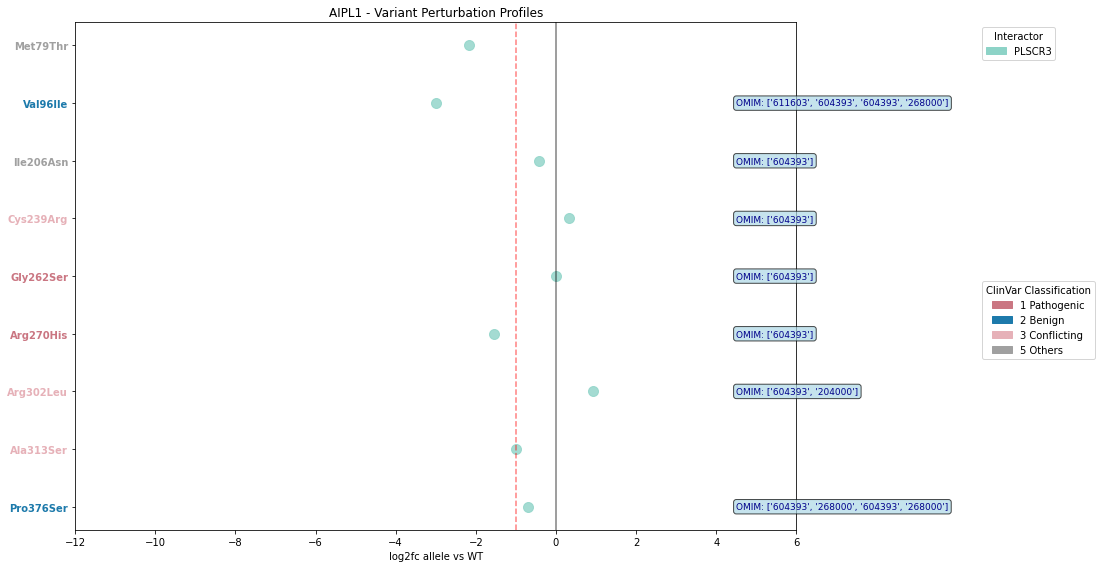


AIPL1 summary:
  Number of variants: 9
  Number of interactors: 1
  Total interactions: 9


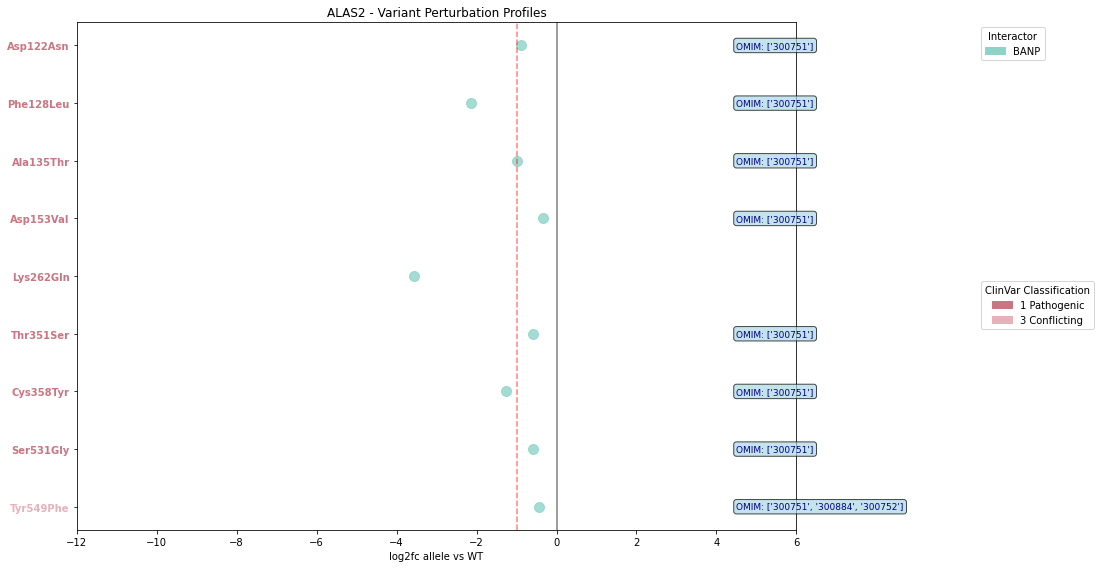


ALAS2 summary:
  Number of variants: 9
  Number of interactors: 1
  Total interactions: 9


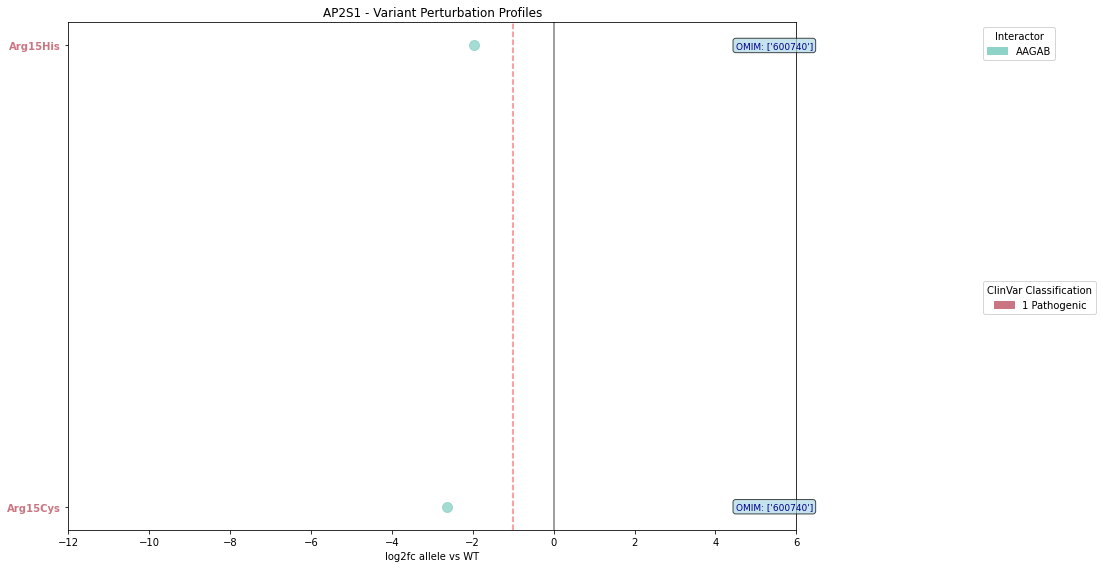


AP2S1 summary:
  Number of variants: 2
  Number of interactors: 1
  Total interactions: 2


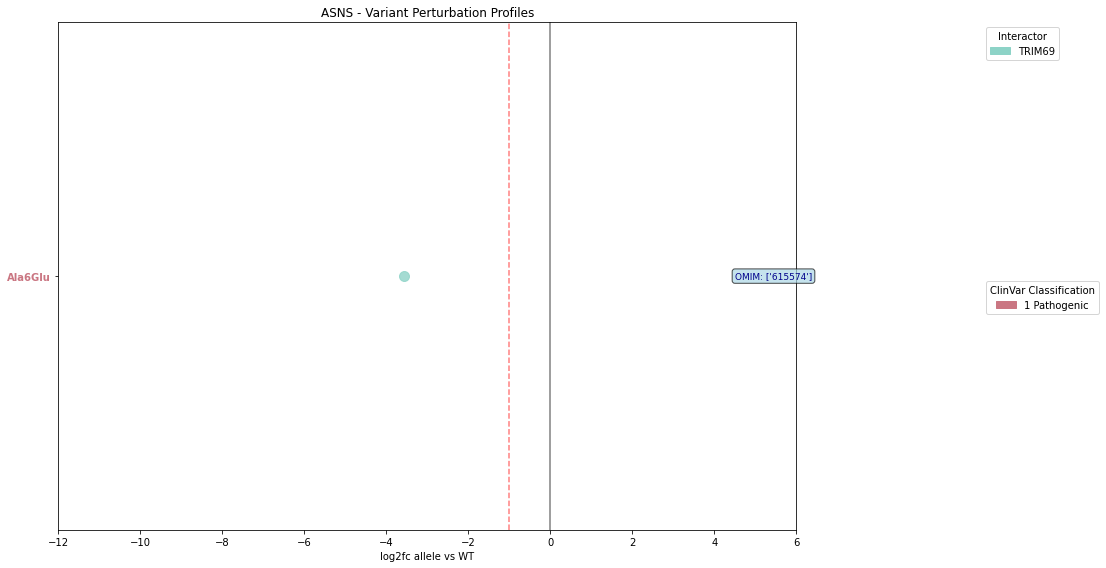


ASNS summary:
  Number of variants: 1
  Number of interactors: 1
  Total interactions: 1


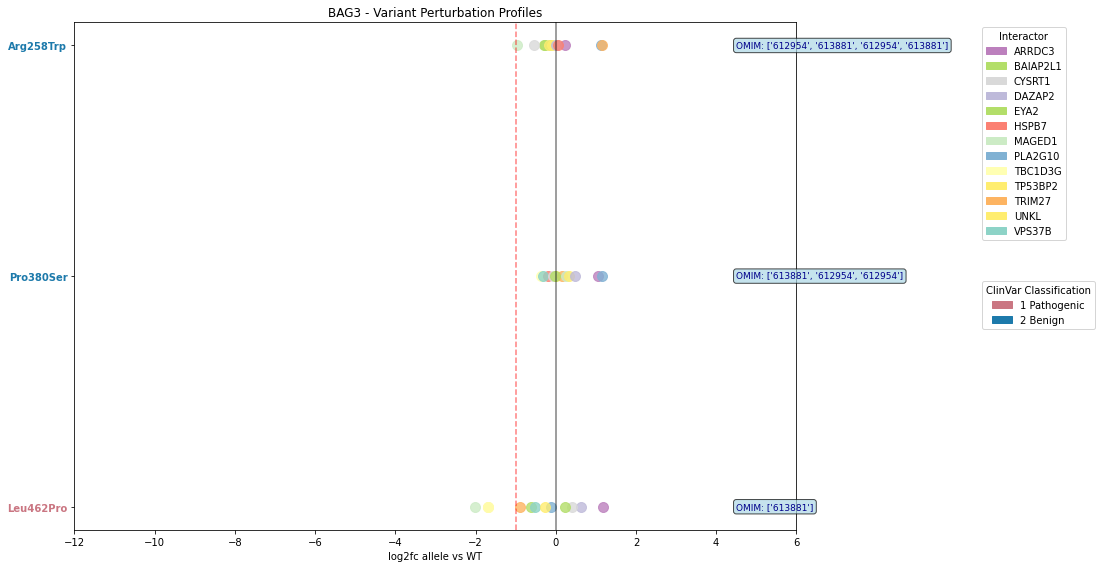


BAG3 summary:
  Number of variants: 3
  Number of interactors: 13
  Total interactions: 37


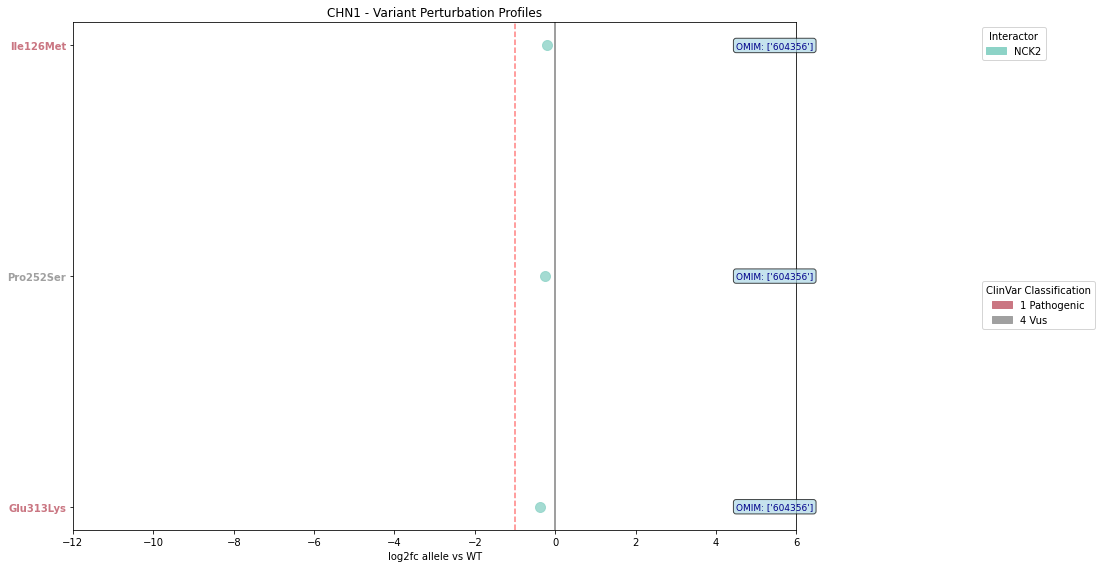


CHN1 summary:
  Number of variants: 3
  Number of interactors: 1
  Total interactions: 3


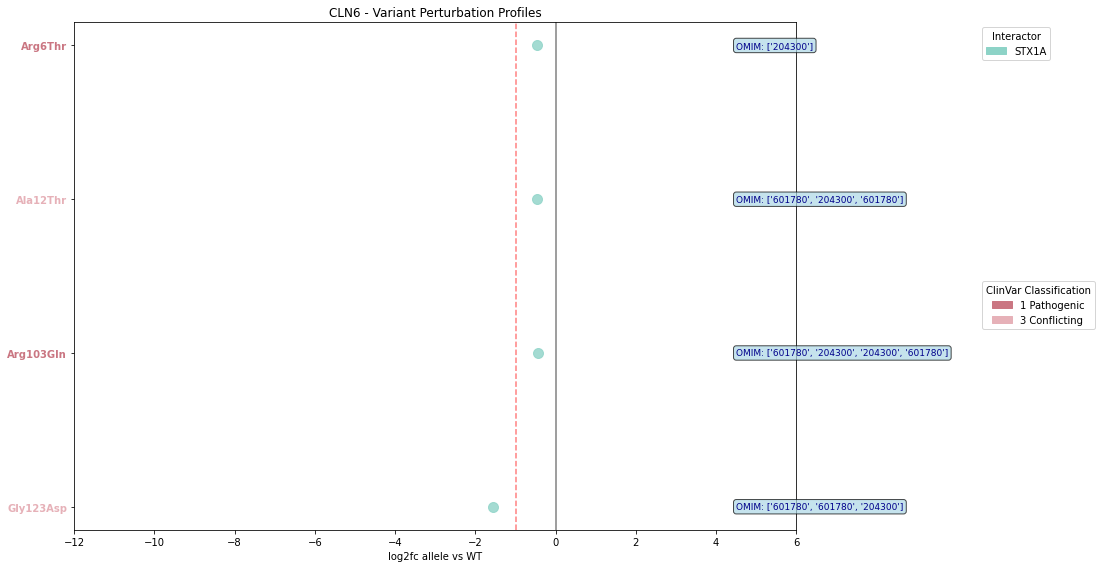


CLN6 summary:
  Number of variants: 4
  Number of interactors: 1
  Total interactions: 4


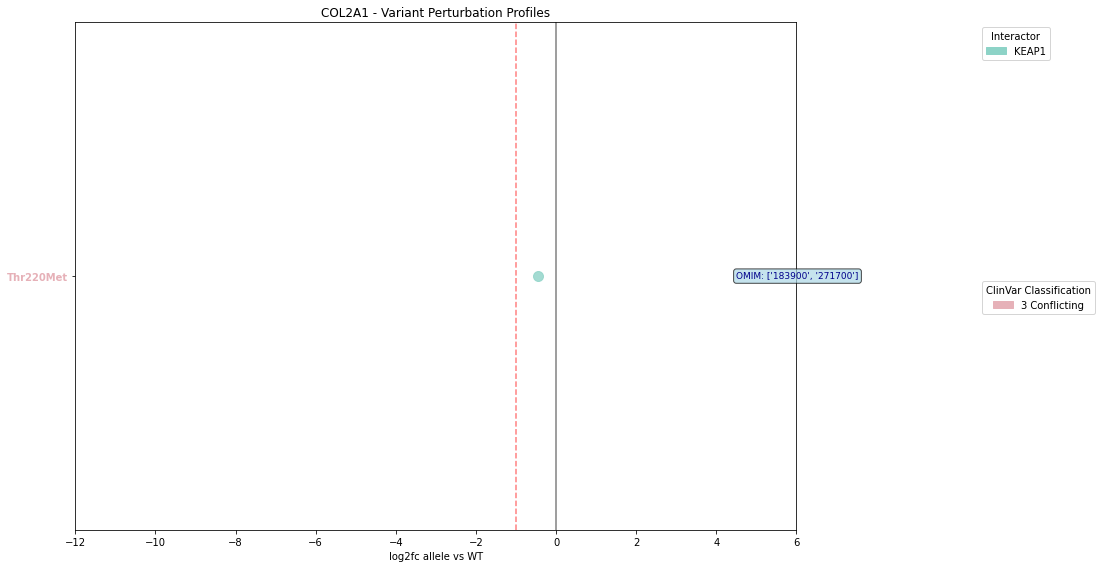


COL2A1 summary:
  Number of variants: 1
  Number of interactors: 1
  Total interactions: 1


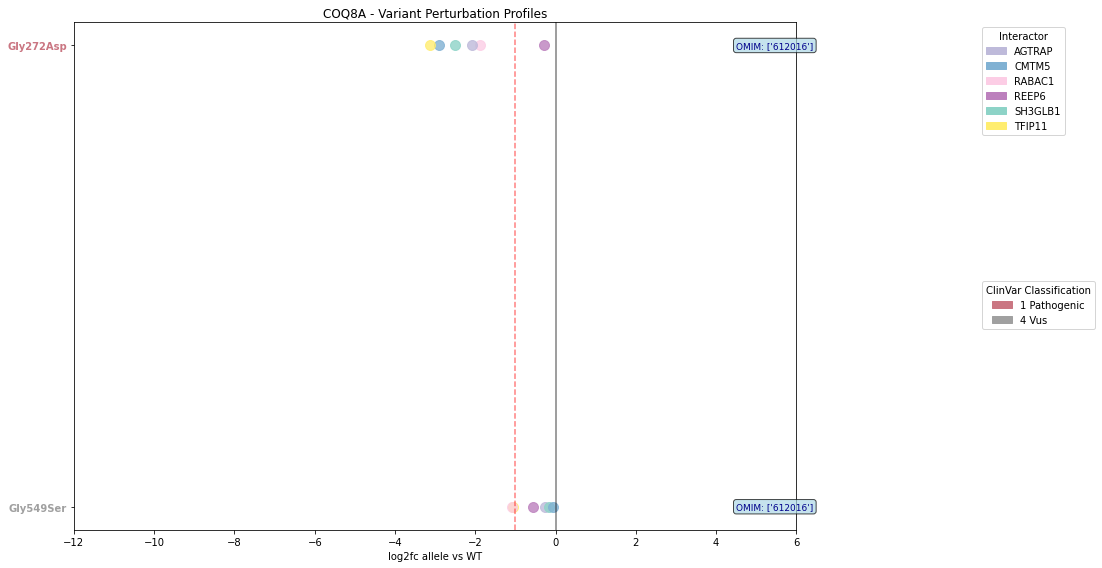


COQ8A summary:
  Number of variants: 2
  Number of interactors: 6
  Total interactions: 12


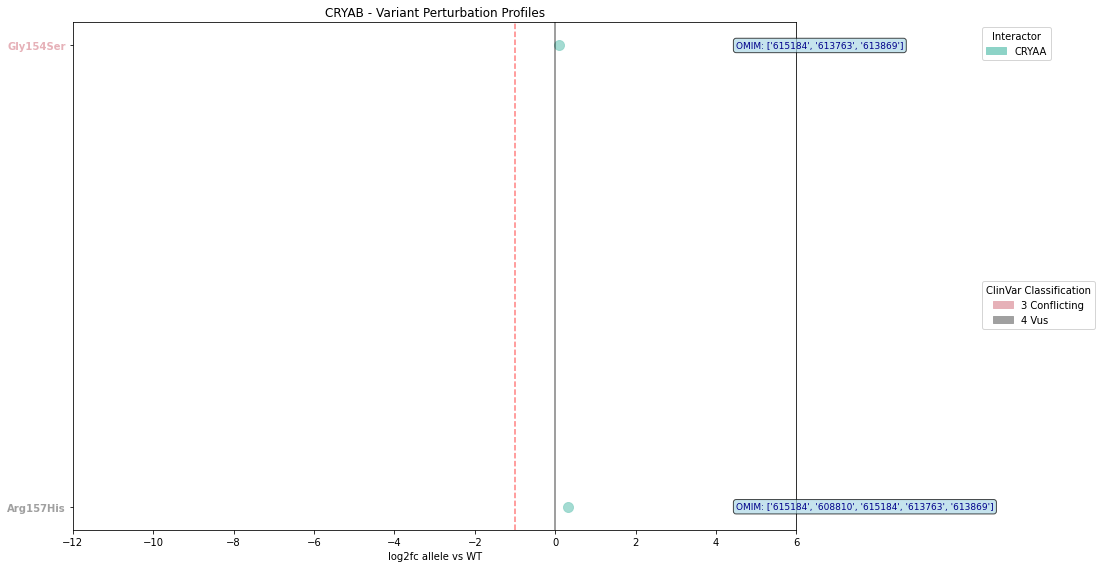


CRYAB summary:
  Number of variants: 2
  Number of interactors: 1
  Total interactions: 2


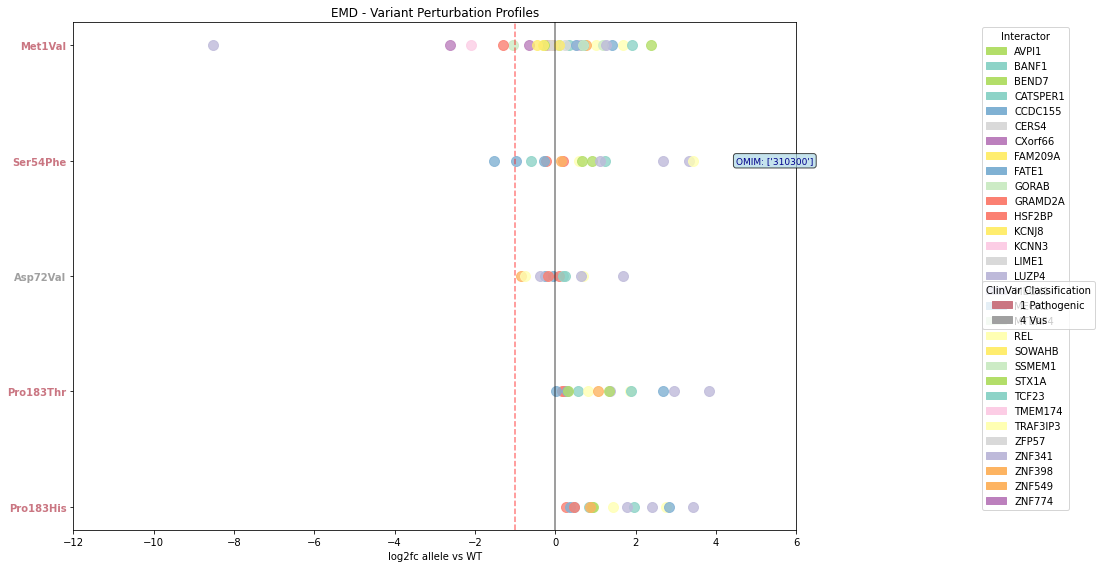


EMD summary:
  Number of variants: 5
  Number of interactors: 31
  Total interactions: 88


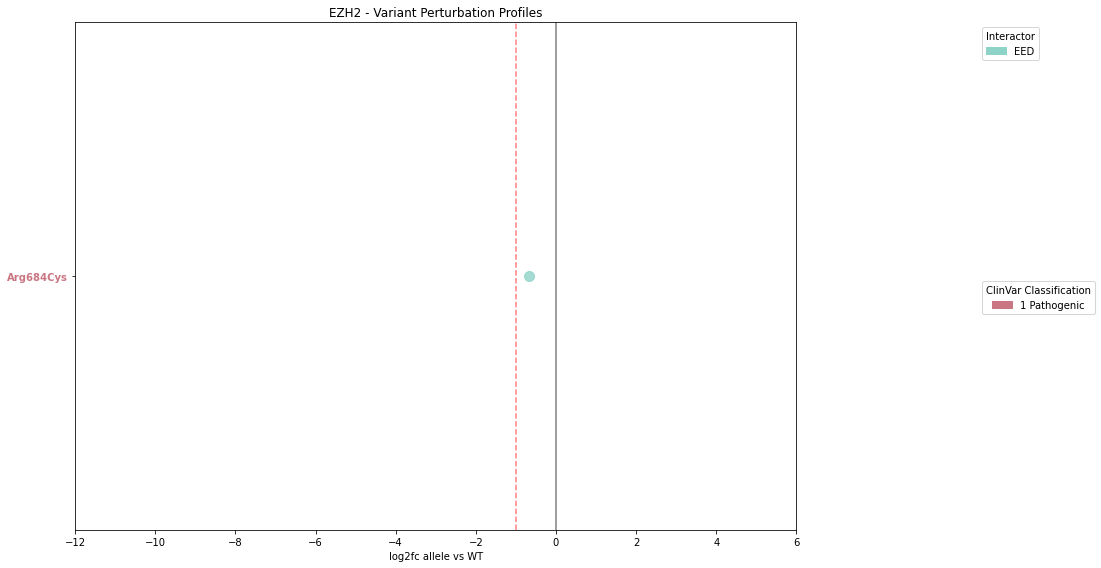


EZH2 summary:
  Number of variants: 1
  Number of interactors: 1
  Total interactions: 1


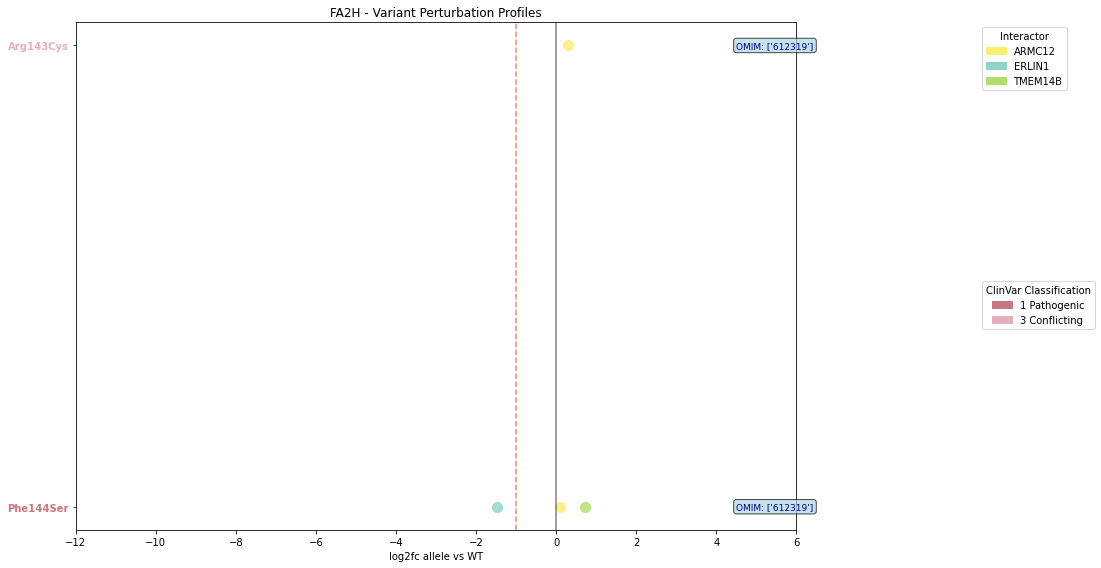


FA2H summary:
  Number of variants: 2
  Number of interactors: 3
  Total interactions: 4


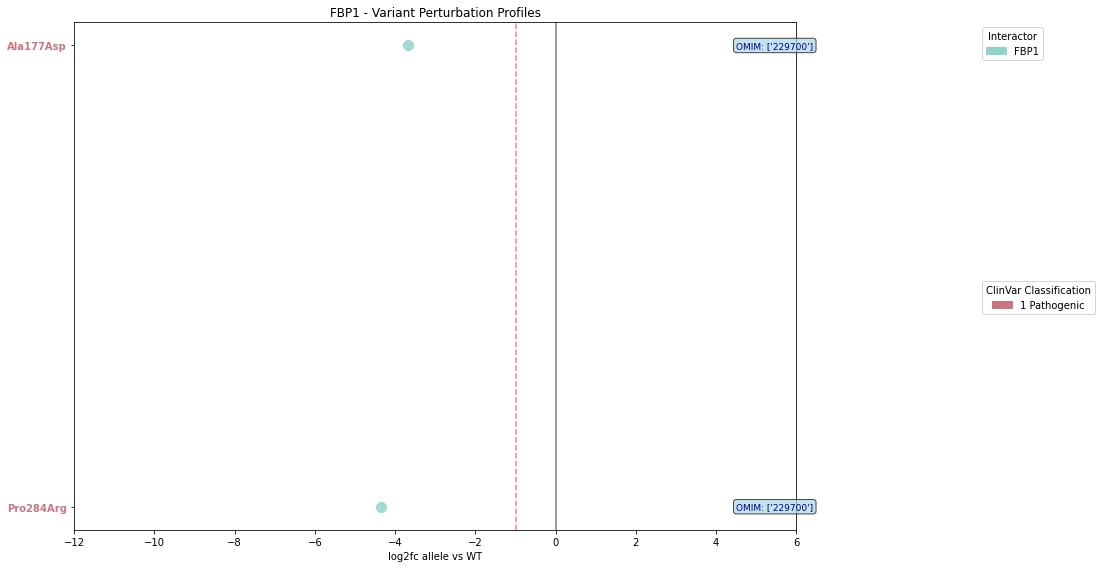


FBP1 summary:
  Number of variants: 2
  Number of interactors: 1
  Total interactions: 2


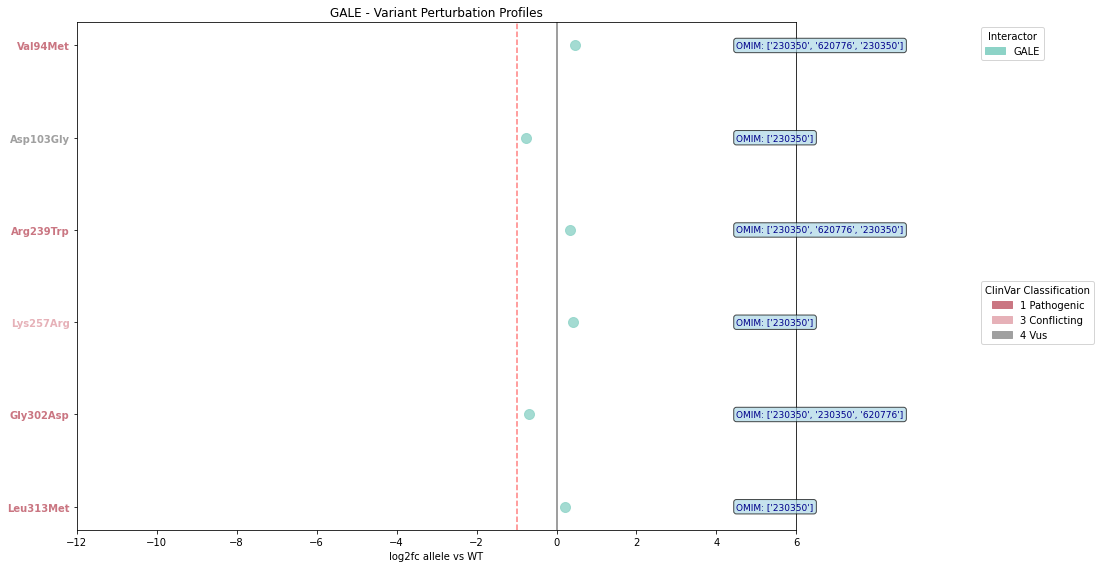


GALE summary:
  Number of variants: 6
  Number of interactors: 1
  Total interactions: 6


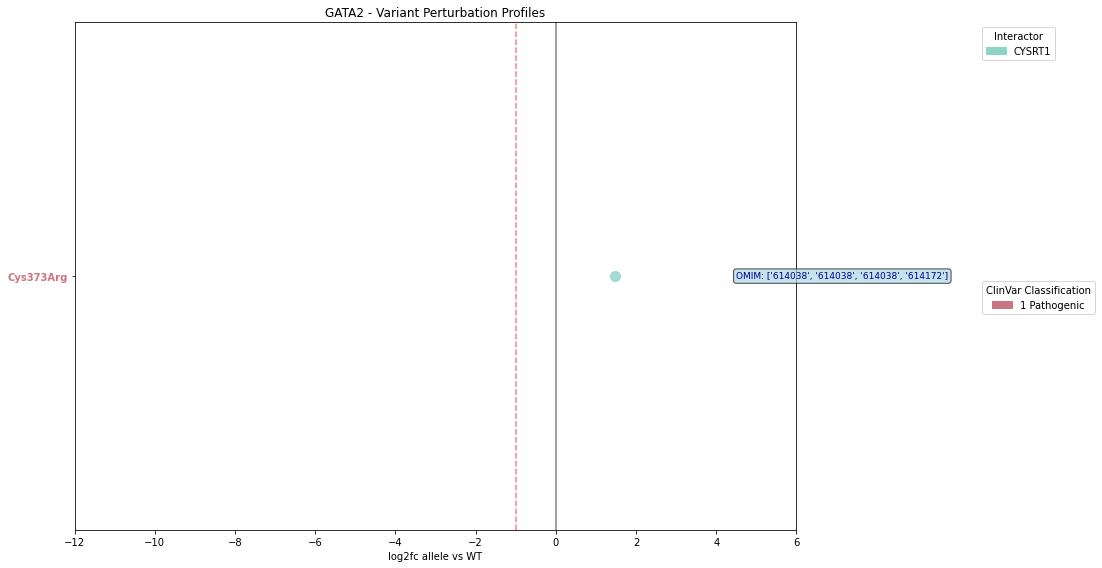


GATA2 summary:
  Number of variants: 1
  Number of interactors: 1
  Total interactions: 1


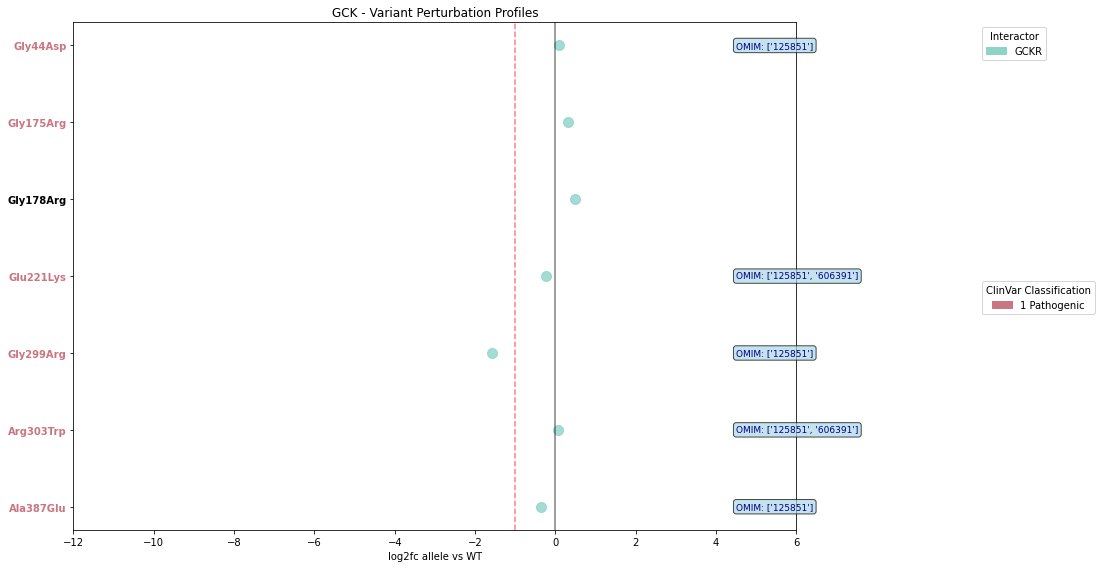


GCK summary:
  Number of variants: 7
  Number of interactors: 1
  Total interactions: 7


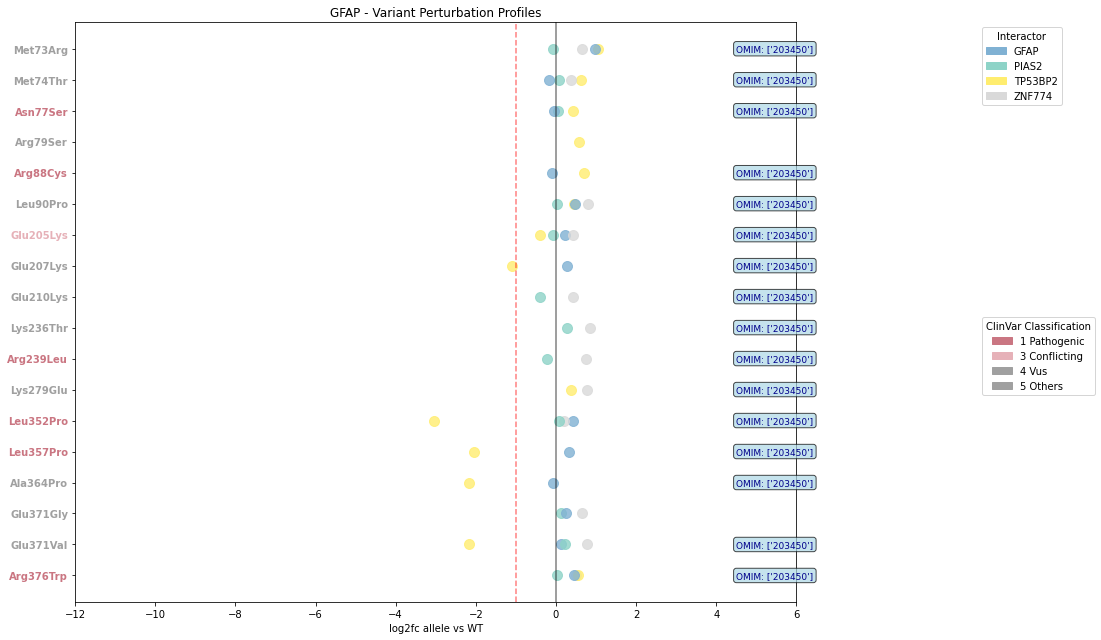


GFAP summary:
  Number of variants: 18
  Number of interactors: 4
  Total interactions: 51


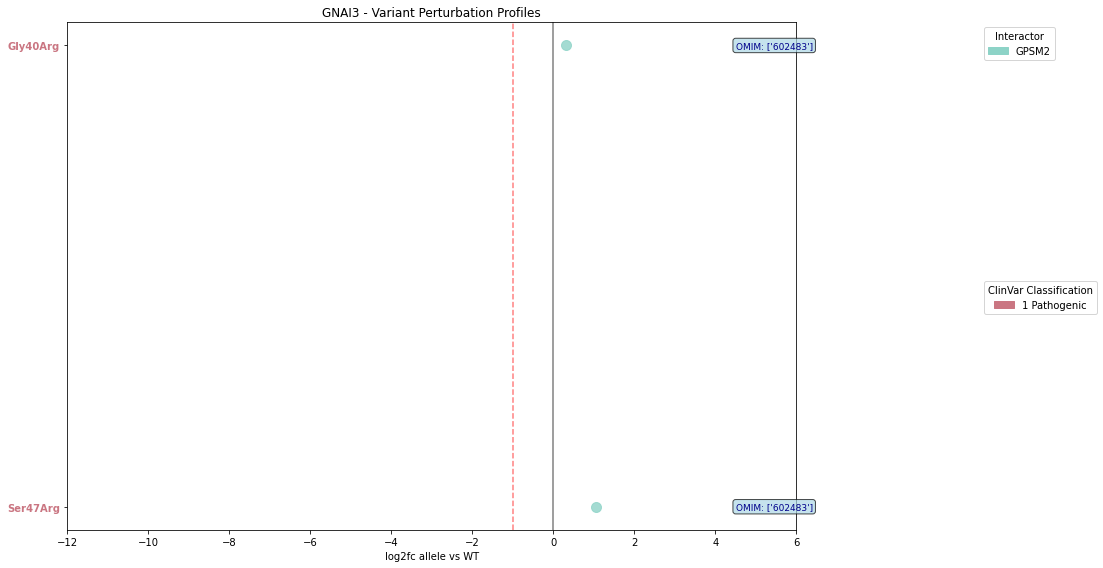


GNAI3 summary:
  Number of variants: 2
  Number of interactors: 1
  Total interactions: 2


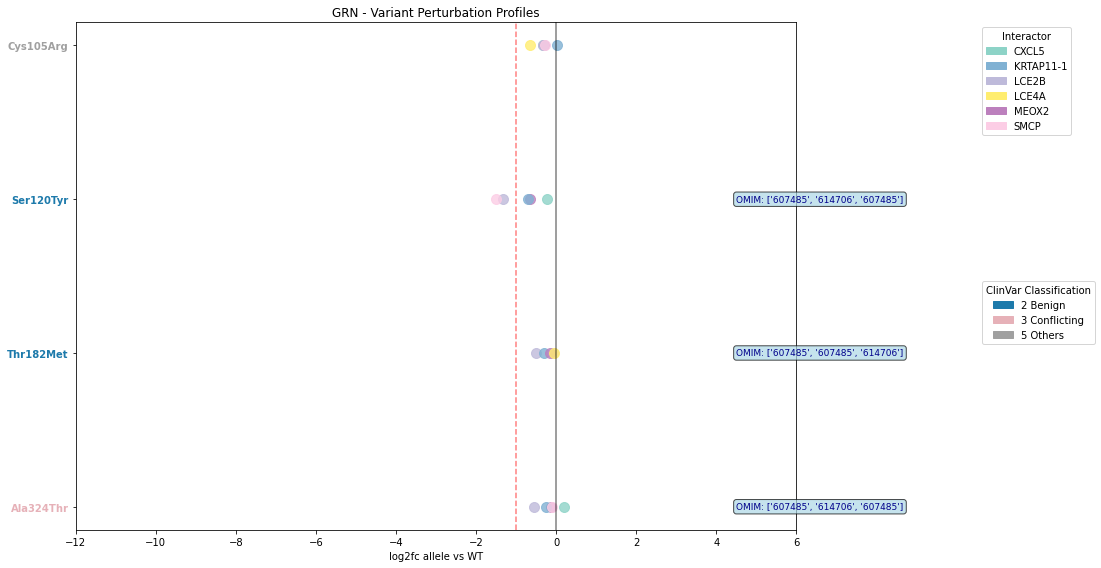


GRN summary:
  Number of variants: 4
  Number of interactors: 6
  Total interactions: 22


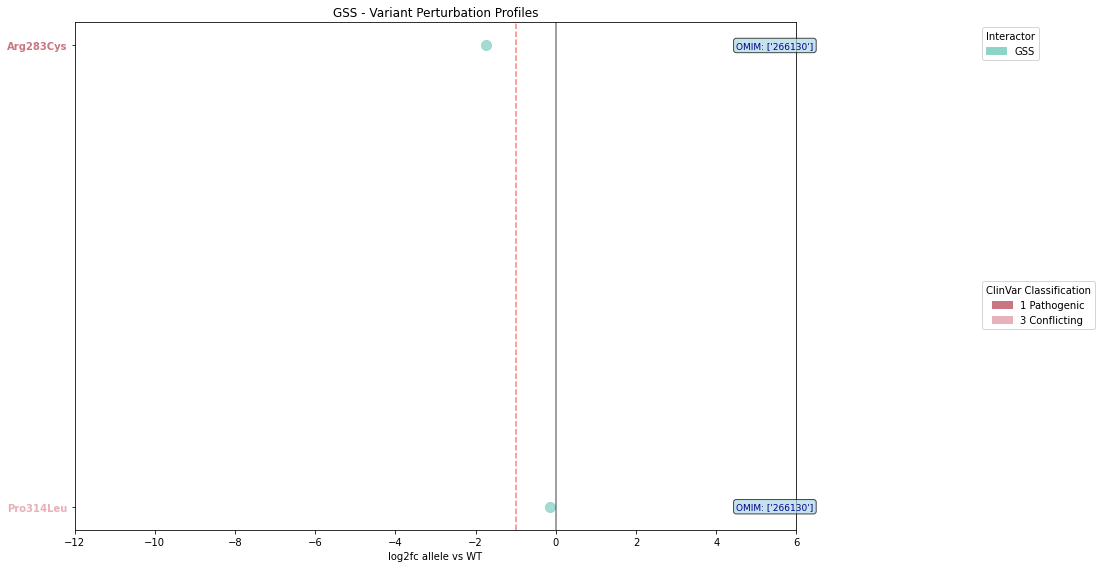


GSS summary:
  Number of variants: 2
  Number of interactors: 1
  Total interactions: 2


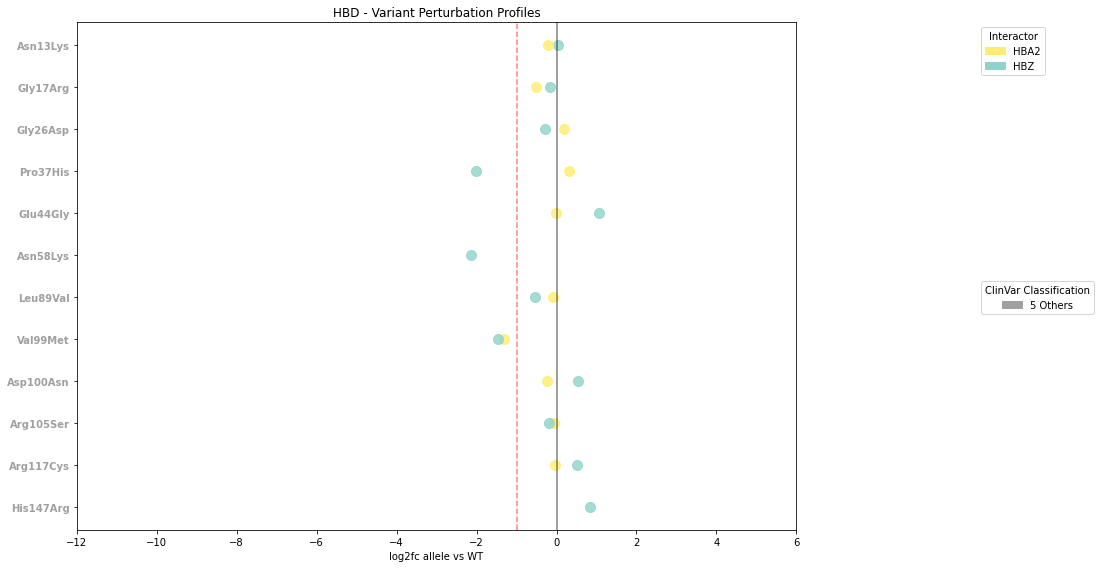


HBD summary:
  Number of variants: 12
  Number of interactors: 2
  Total interactions: 22


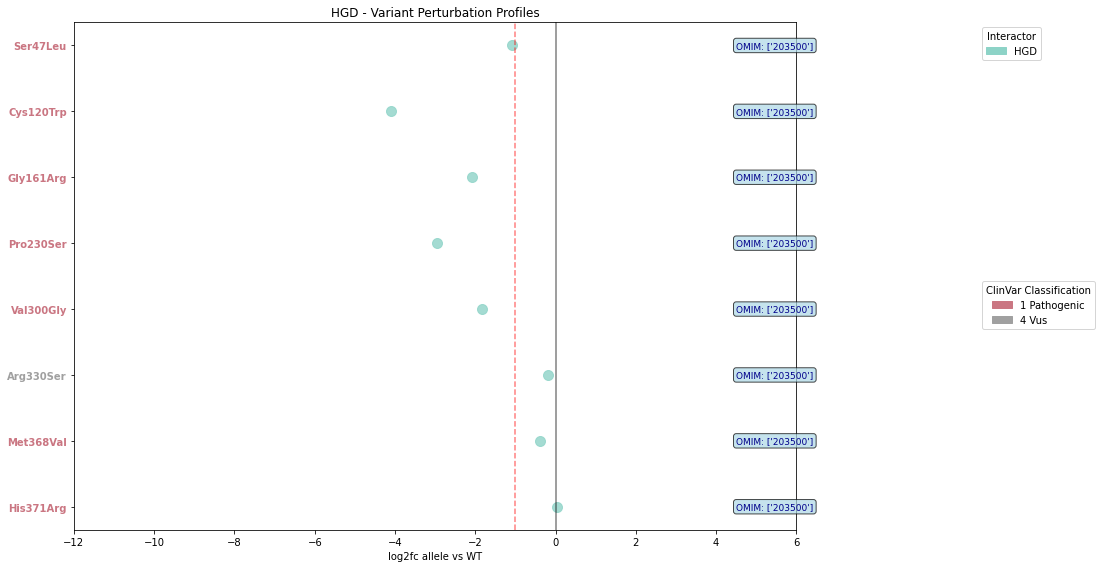


HGD summary:
  Number of variants: 8
  Number of interactors: 1
  Total interactions: 8


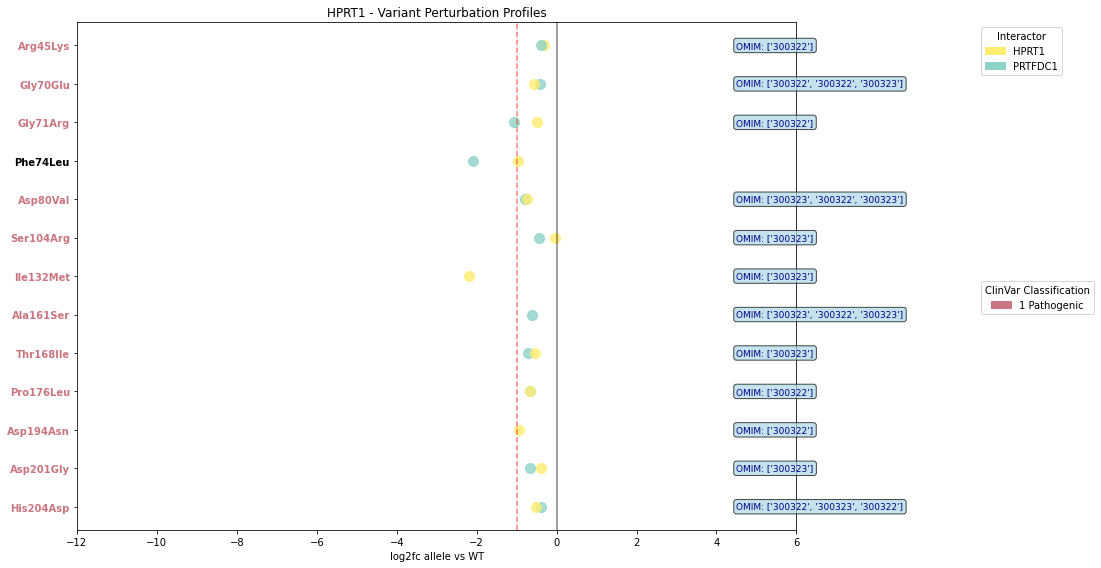


HPRT1 summary:
  Number of variants: 13
  Number of interactors: 2
  Total interactions: 24


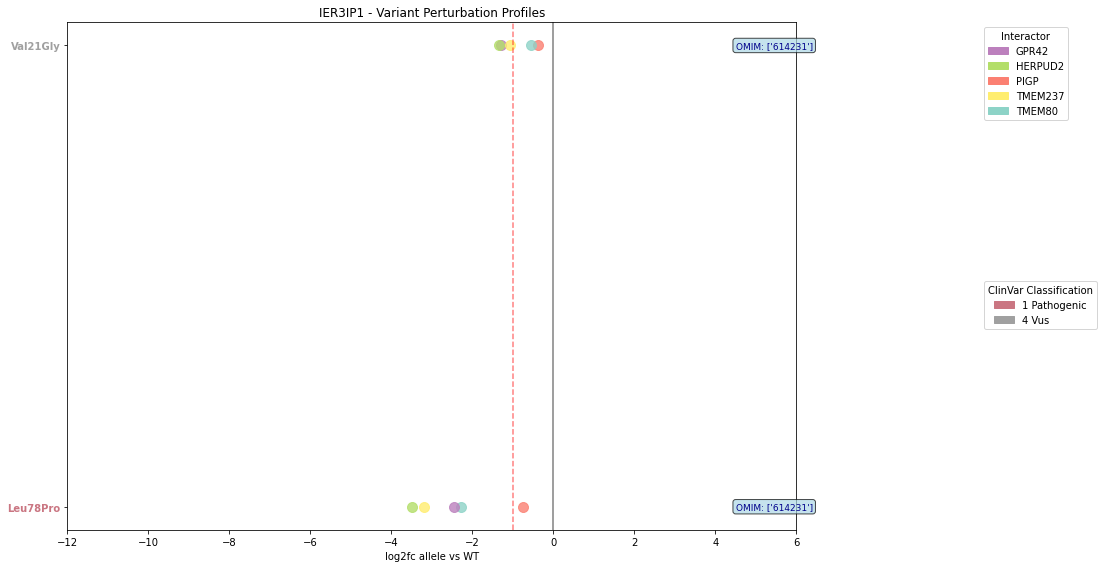


IER3IP1 summary:
  Number of variants: 2
  Number of interactors: 5
  Total interactions: 10


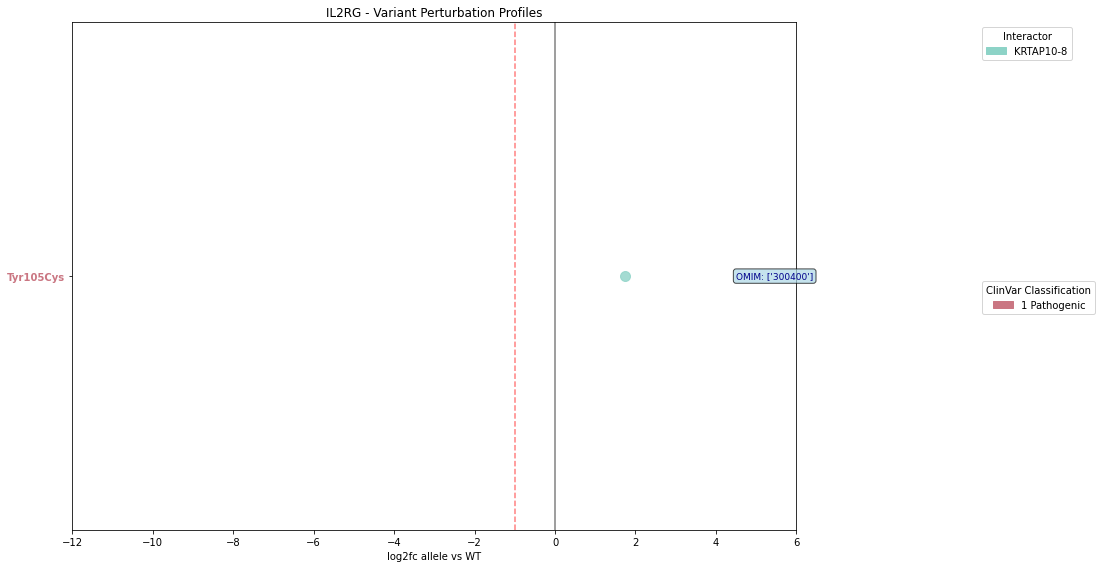


IL2RG summary:
  Number of variants: 1
  Number of interactors: 1
  Total interactions: 1


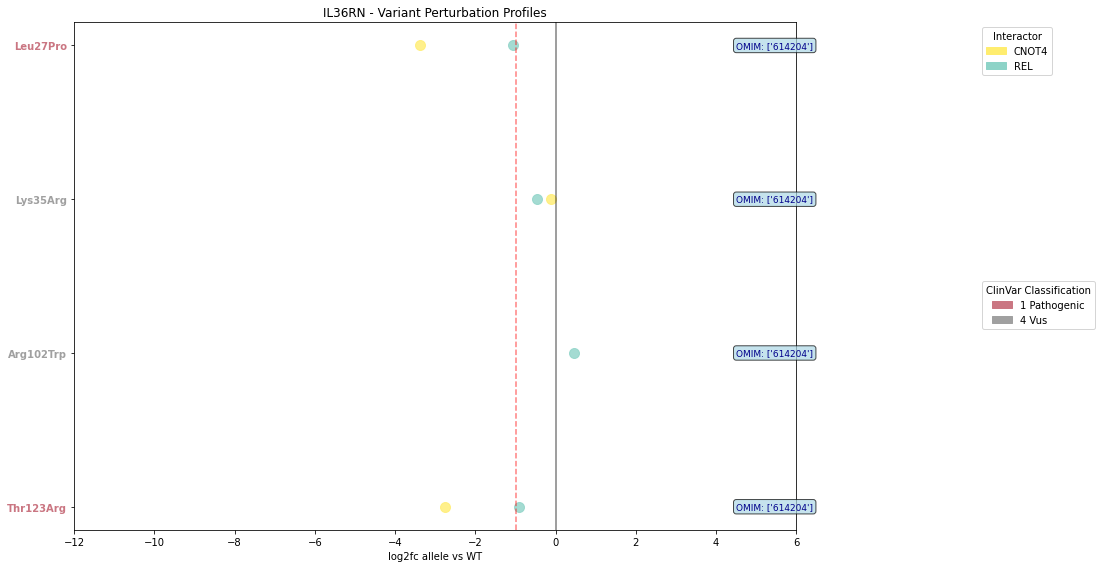


IL36RN summary:
  Number of variants: 4
  Number of interactors: 2
  Total interactions: 7


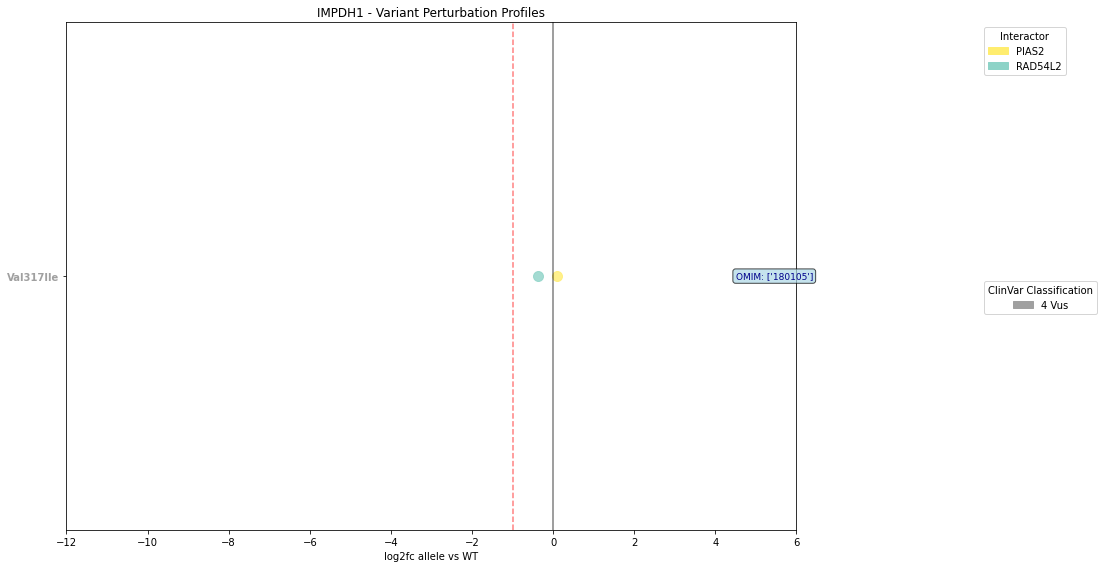


IMPDH1 summary:
  Number of variants: 1
  Number of interactors: 2
  Total interactions: 2


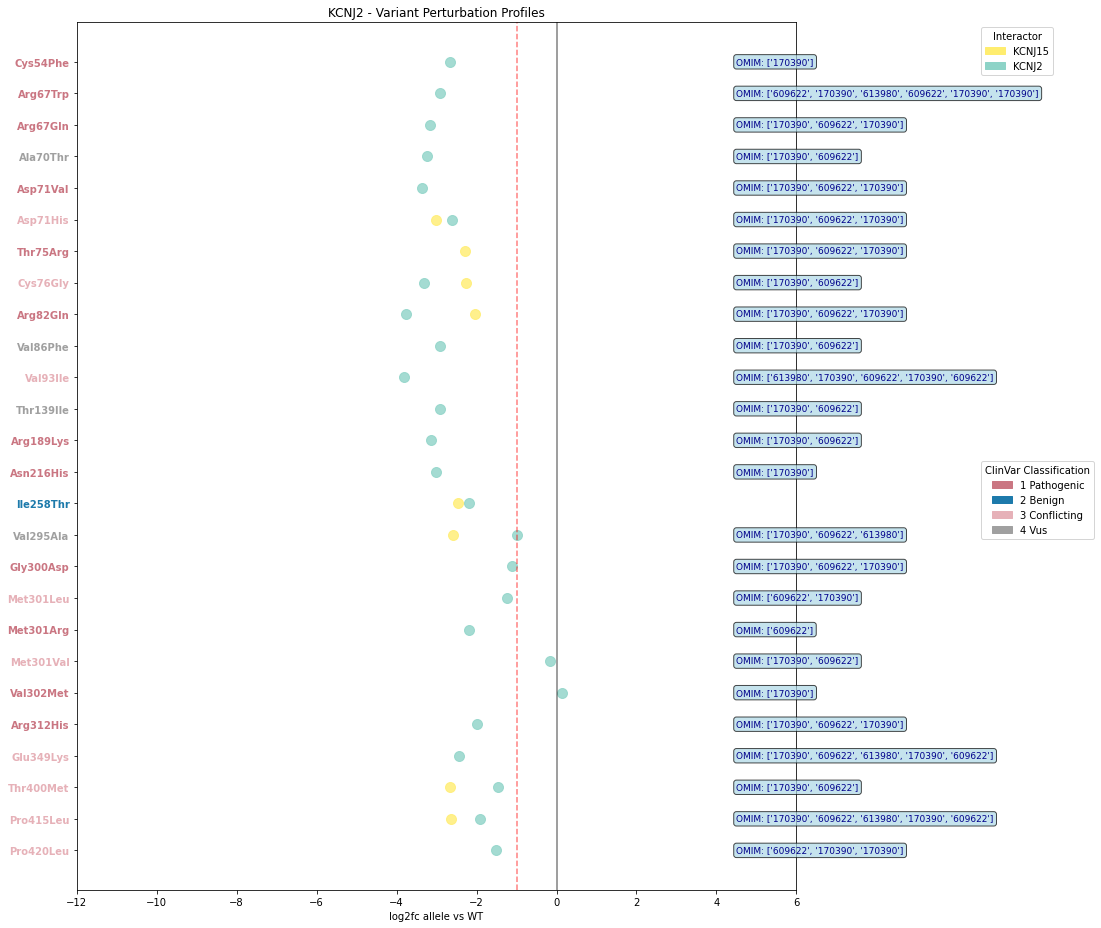


KCNJ2 summary:
  Number of variants: 26
  Number of interactors: 2
  Total interactions: 33


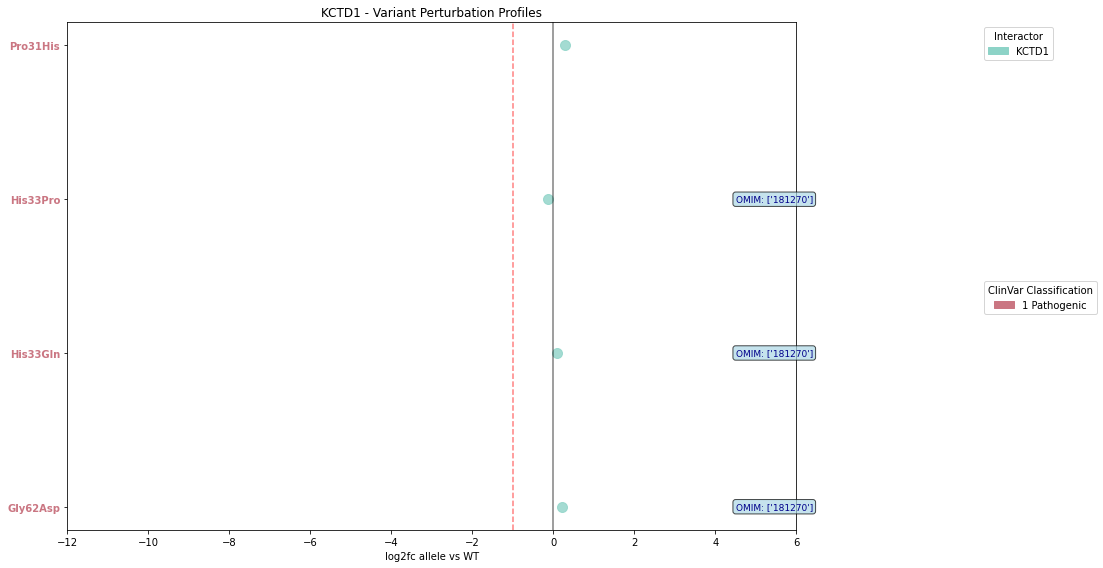


KCTD1 summary:
  Number of variants: 4
  Number of interactors: 1
  Total interactions: 4


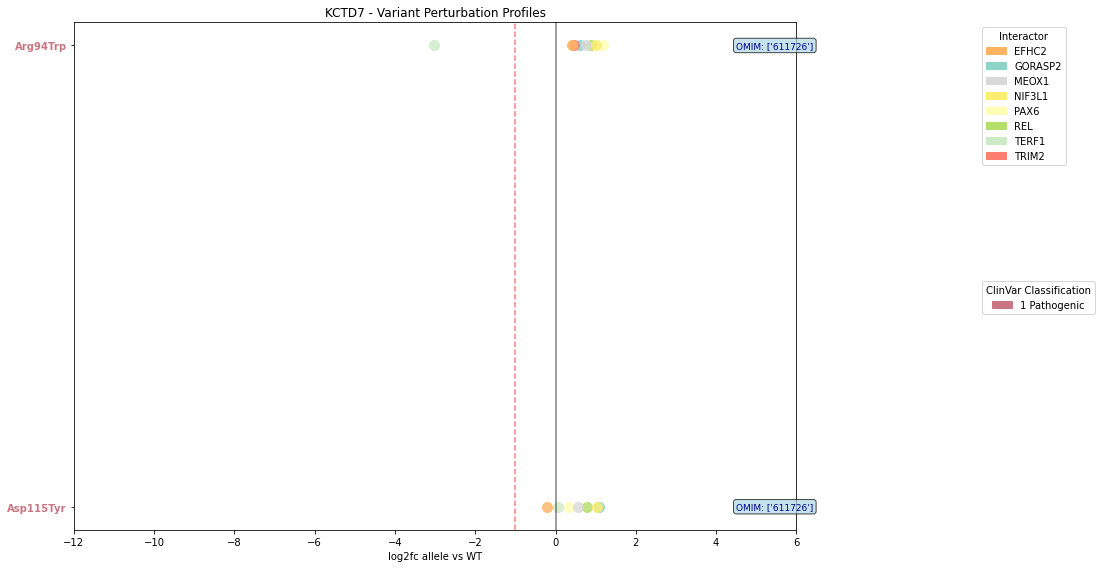


KCTD7 summary:
  Number of variants: 2
  Number of interactors: 8
  Total interactions: 15


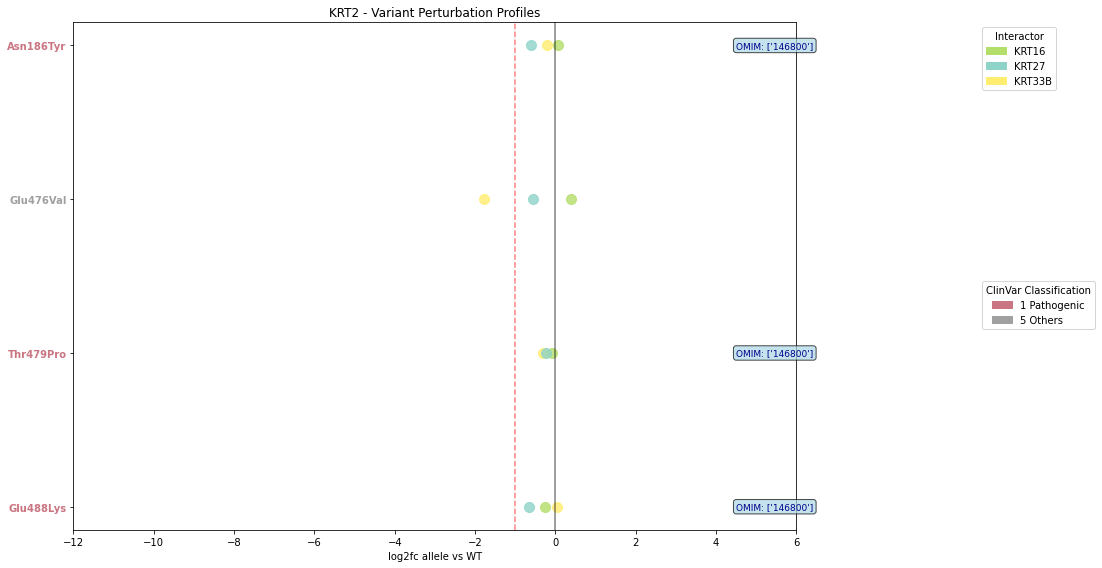


KRT2 summary:
  Number of variants: 4
  Number of interactors: 3
  Total interactions: 12


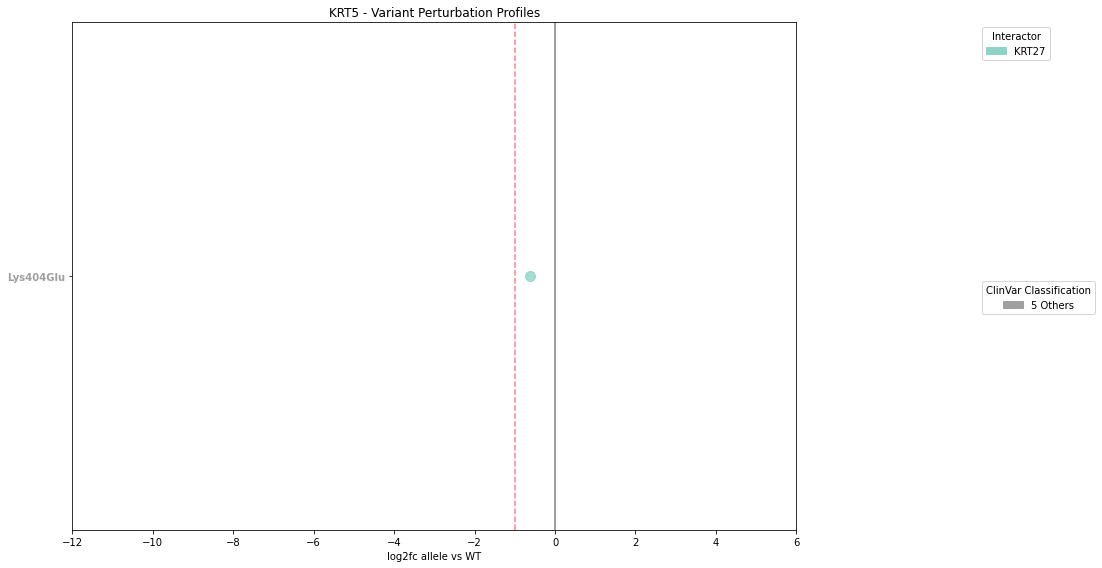


KRT5 summary:
  Number of variants: 1
  Number of interactors: 1
  Total interactions: 1


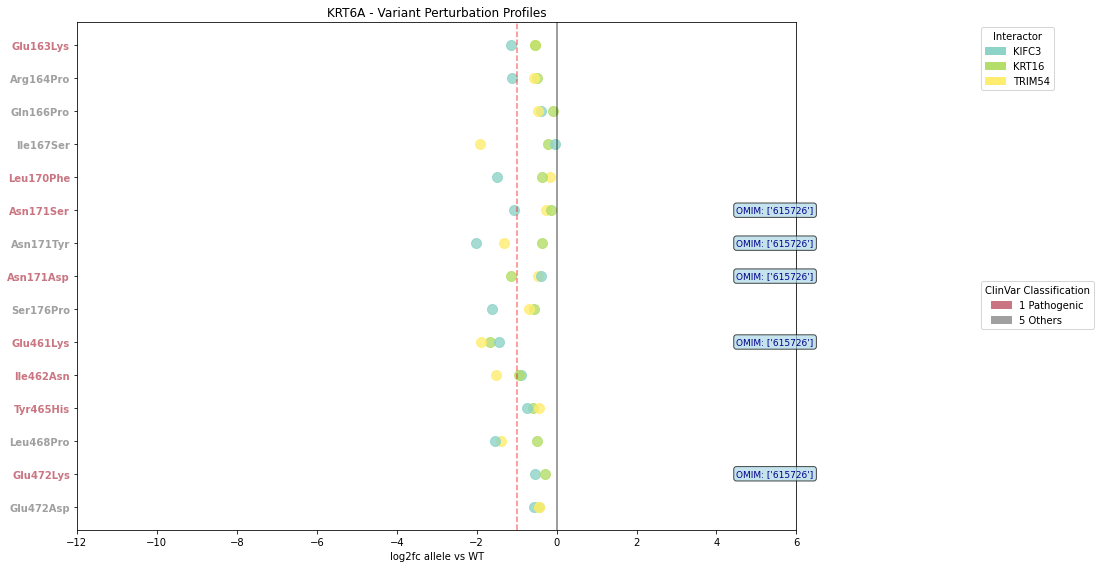


KRT6A summary:
  Number of variants: 15
  Number of interactors: 3
  Total interactions: 44


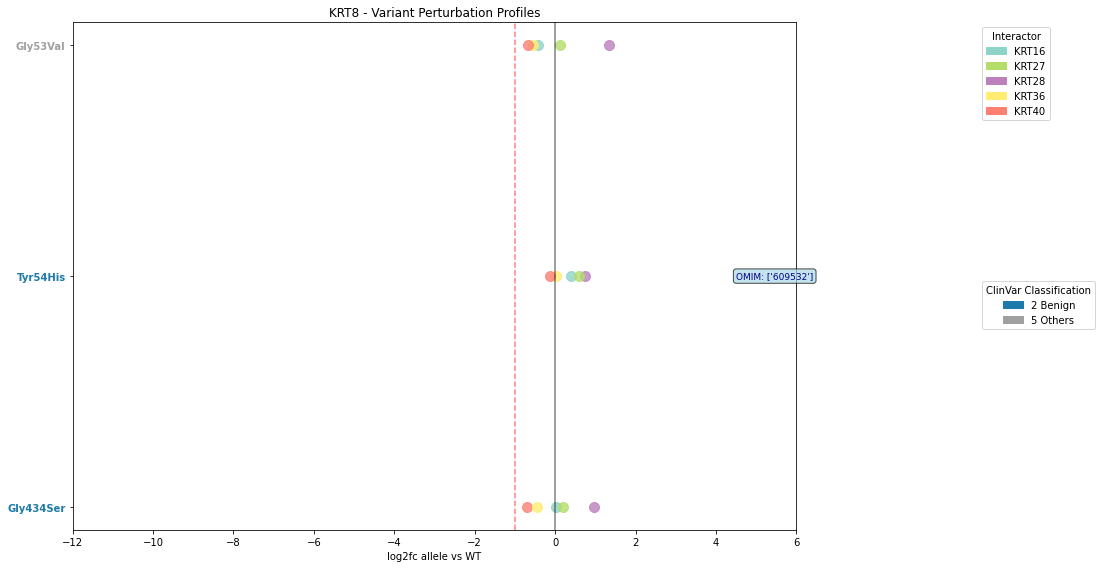


KRT8 summary:
  Number of variants: 3
  Number of interactors: 5
  Total interactions: 15


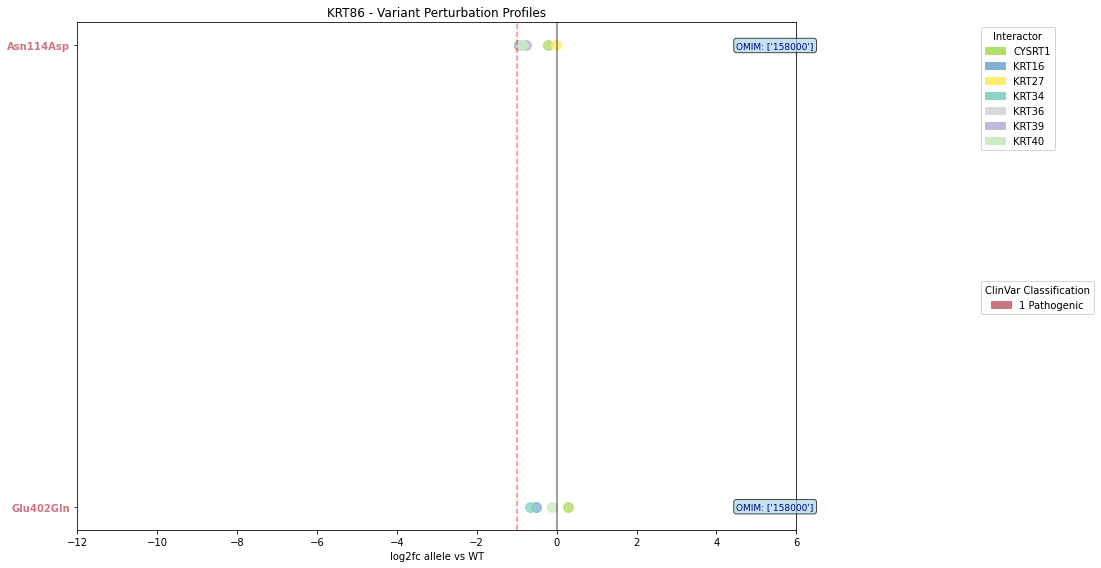


KRT86 summary:
  Number of variants: 2
  Number of interactors: 7
  Total interactions: 11


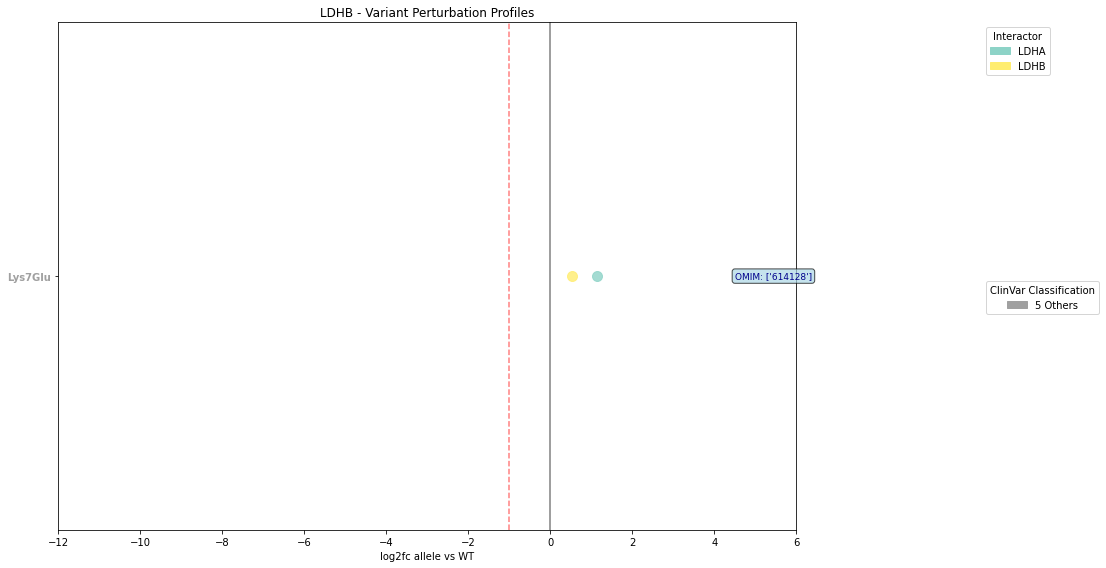


LDHB summary:
  Number of variants: 1
  Number of interactors: 2
  Total interactions: 2


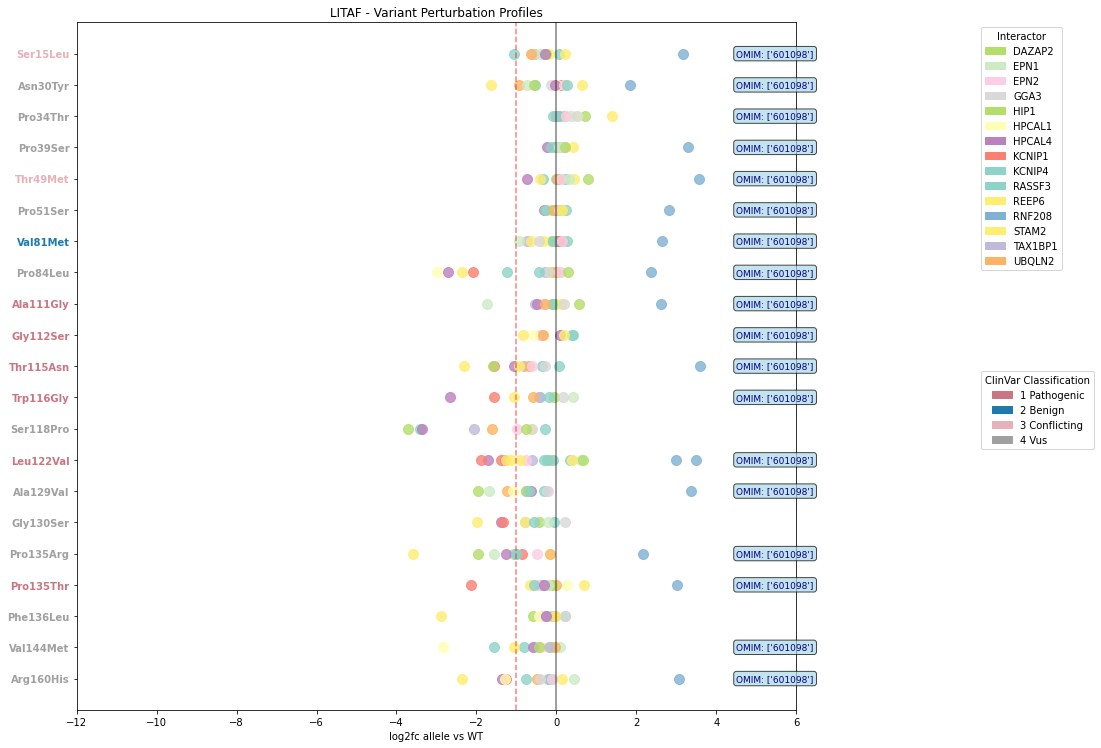


LITAF summary:
  Number of variants: 21
  Number of interactors: 15
  Total interactions: 276


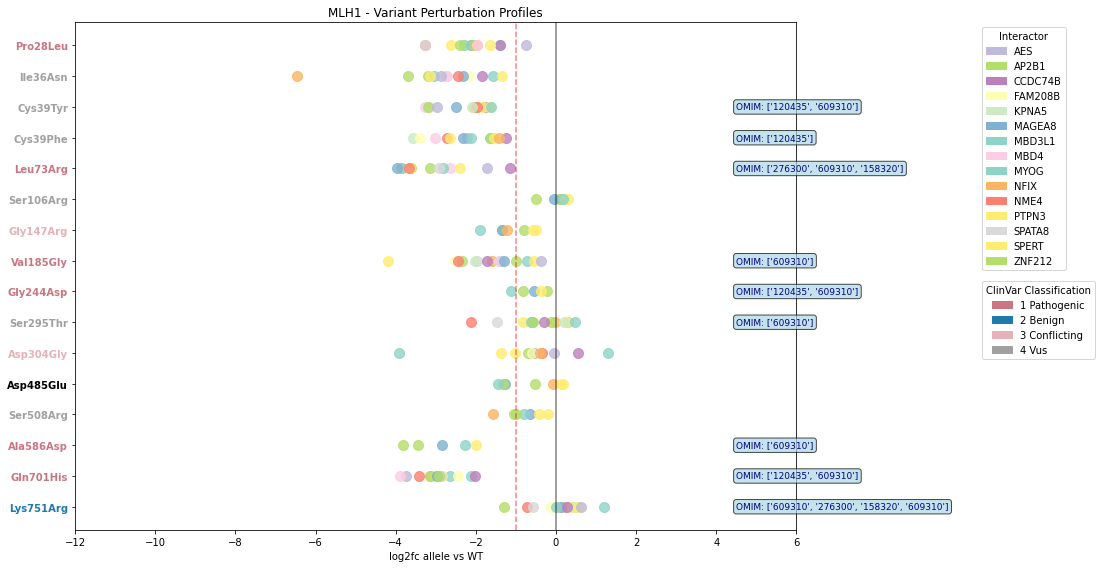


MLH1 summary:
  Number of variants: 16
  Number of interactors: 15
  Total interactions: 174


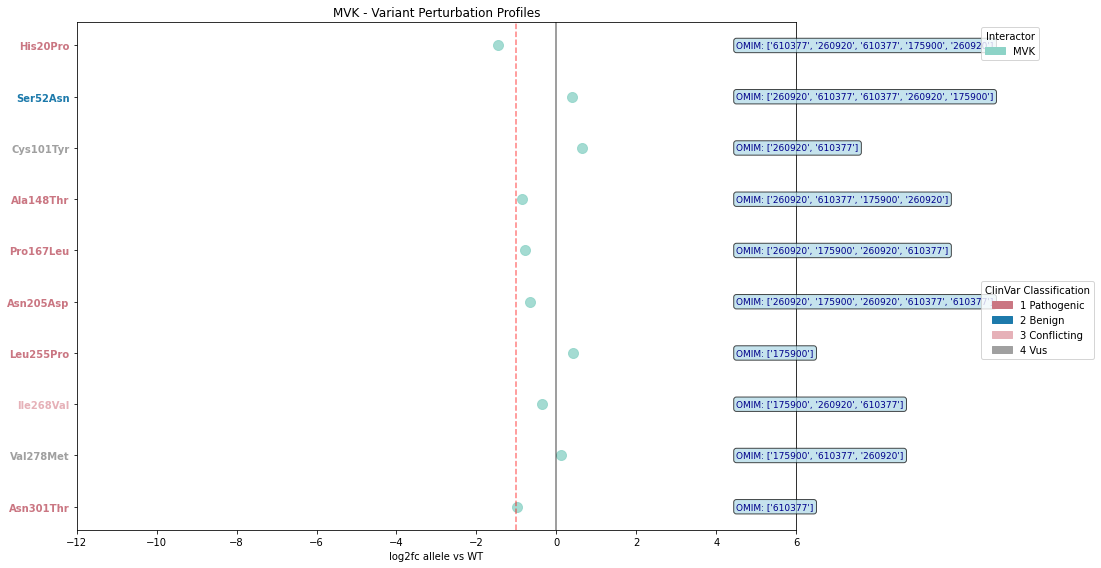


MVK summary:
  Number of variants: 10
  Number of interactors: 1
  Total interactions: 10


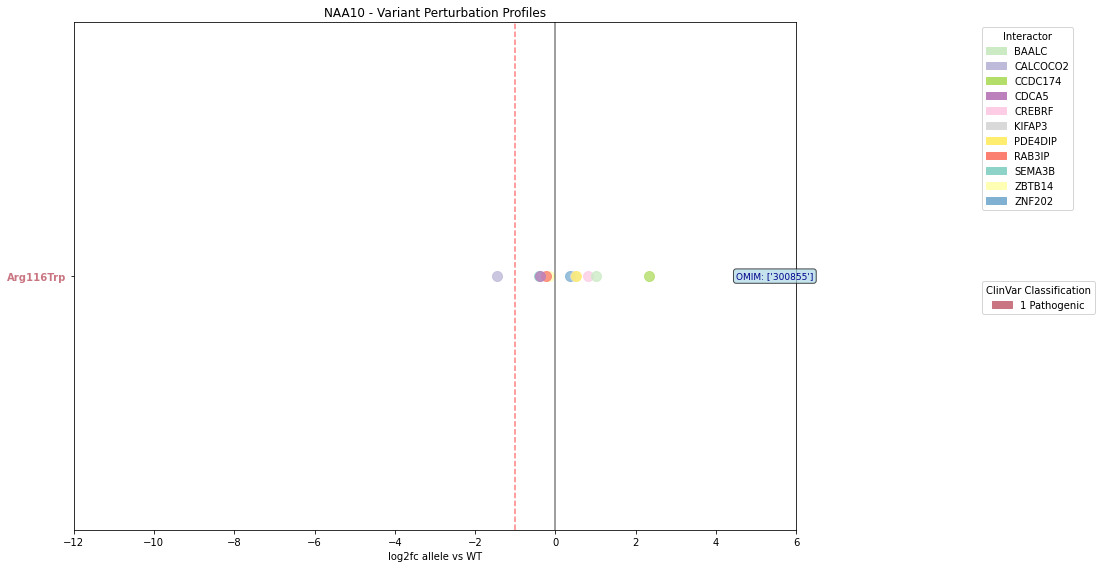


NAA10 summary:
  Number of variants: 1
  Number of interactors: 11
  Total interactions: 11


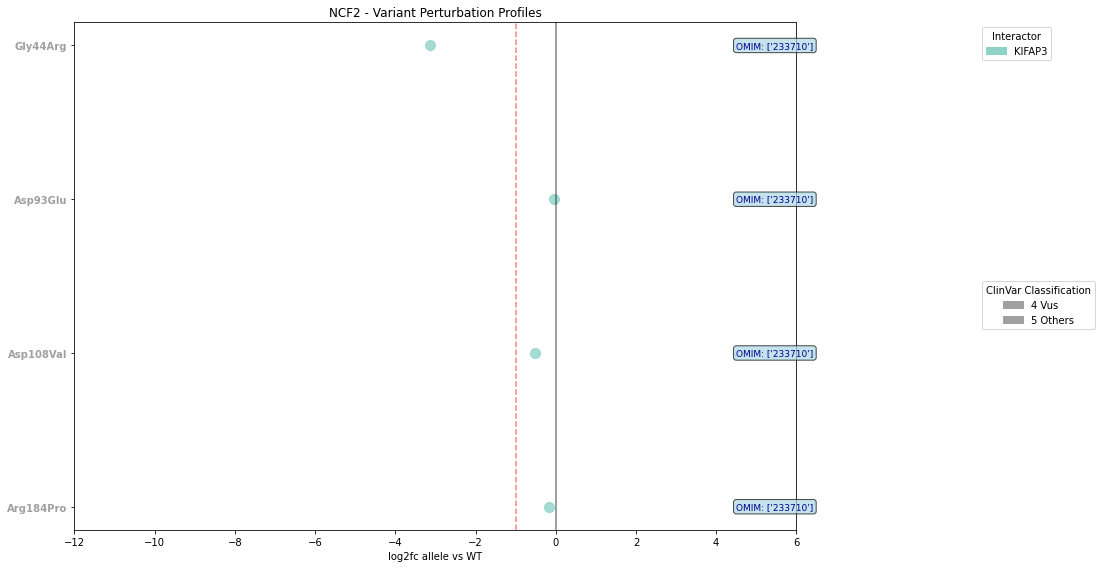


NCF2 summary:
  Number of variants: 4
  Number of interactors: 1
  Total interactions: 4


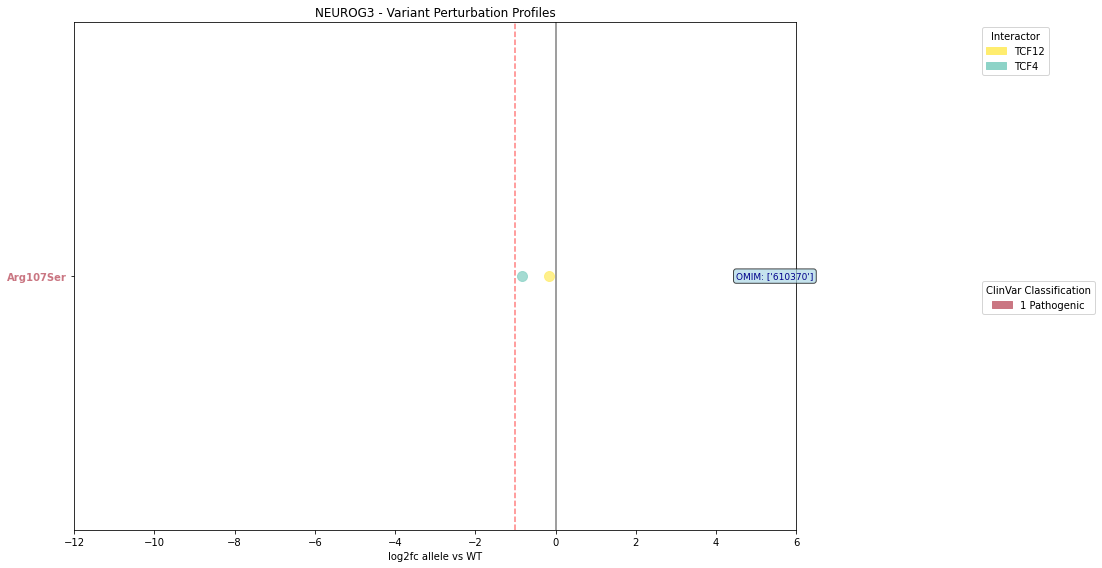


NEUROG3 summary:
  Number of variants: 1
  Number of interactors: 2
  Total interactions: 2


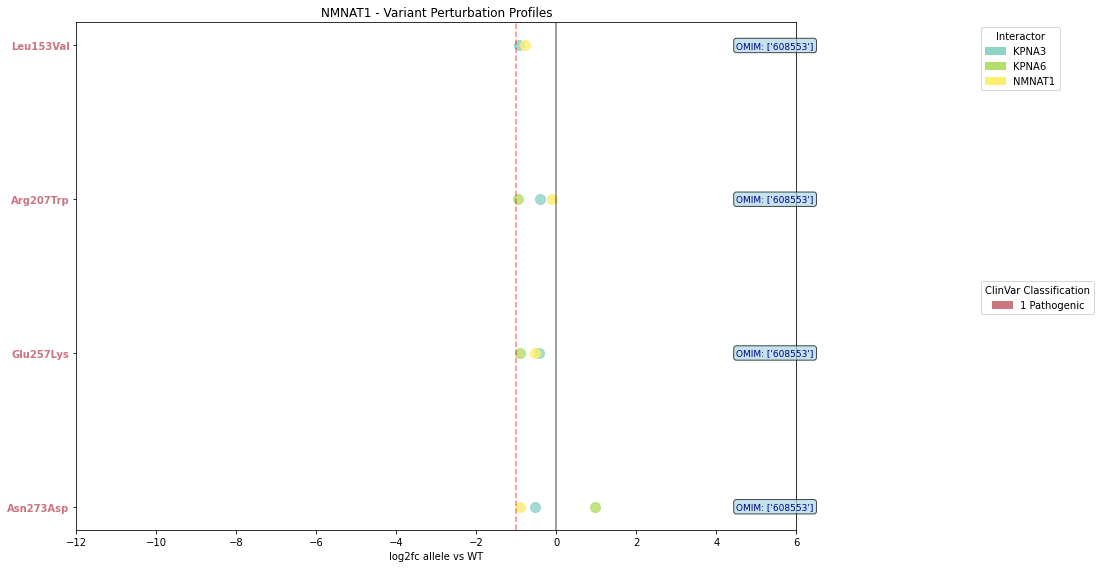


NMNAT1 summary:
  Number of variants: 4
  Number of interactors: 3
  Total interactions: 11


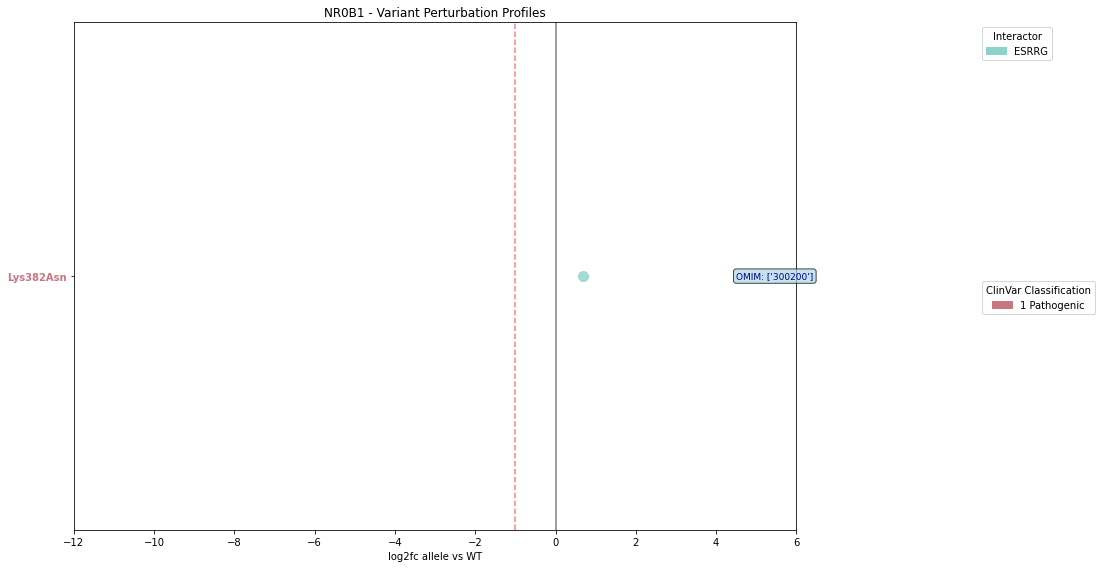


NR0B1 summary:
  Number of variants: 1
  Number of interactors: 1
  Total interactions: 1


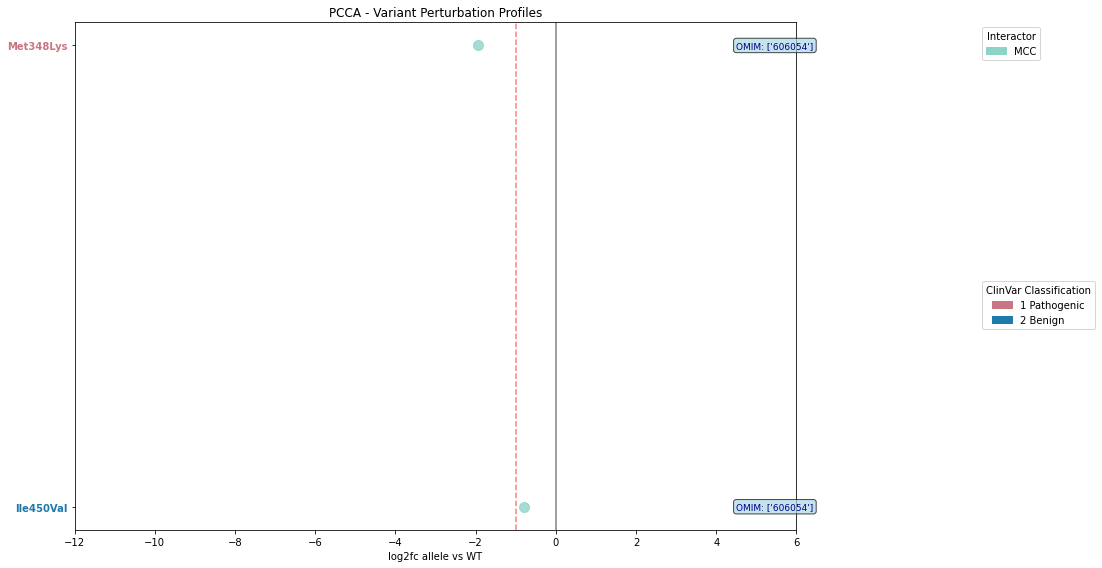


PCCA summary:
  Number of variants: 2
  Number of interactors: 1
  Total interactions: 2


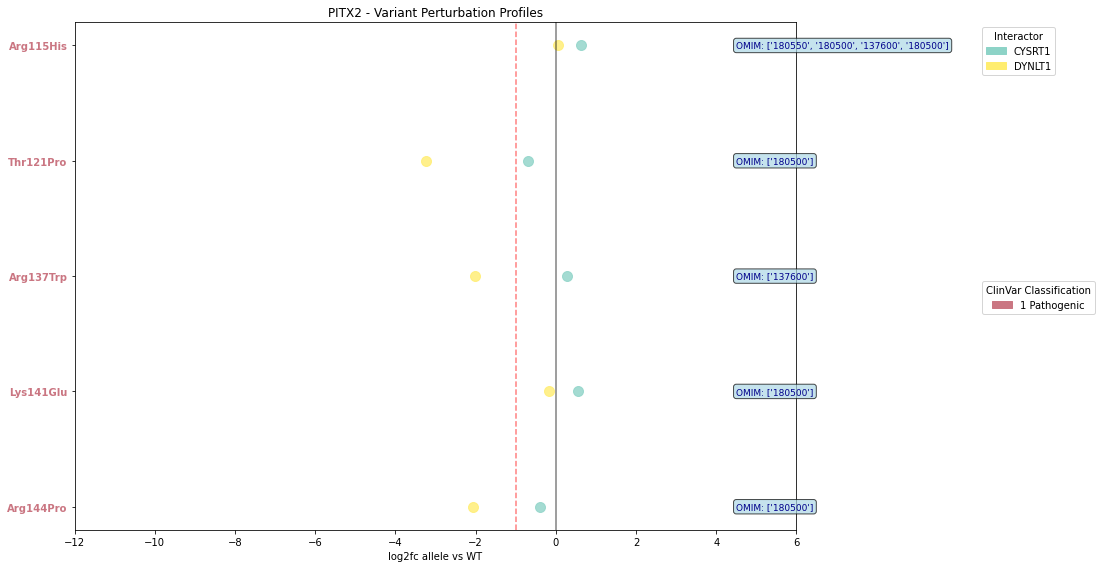


PITX2 summary:
  Number of variants: 5
  Number of interactors: 2
  Total interactions: 10


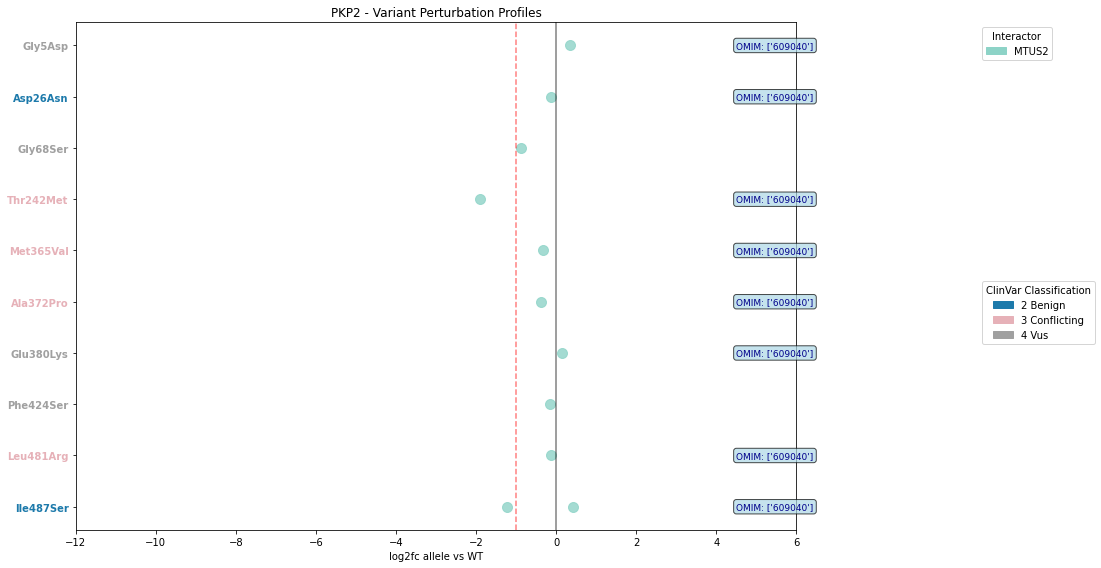


PKP2 summary:
  Number of variants: 10
  Number of interactors: 1
  Total interactions: 11


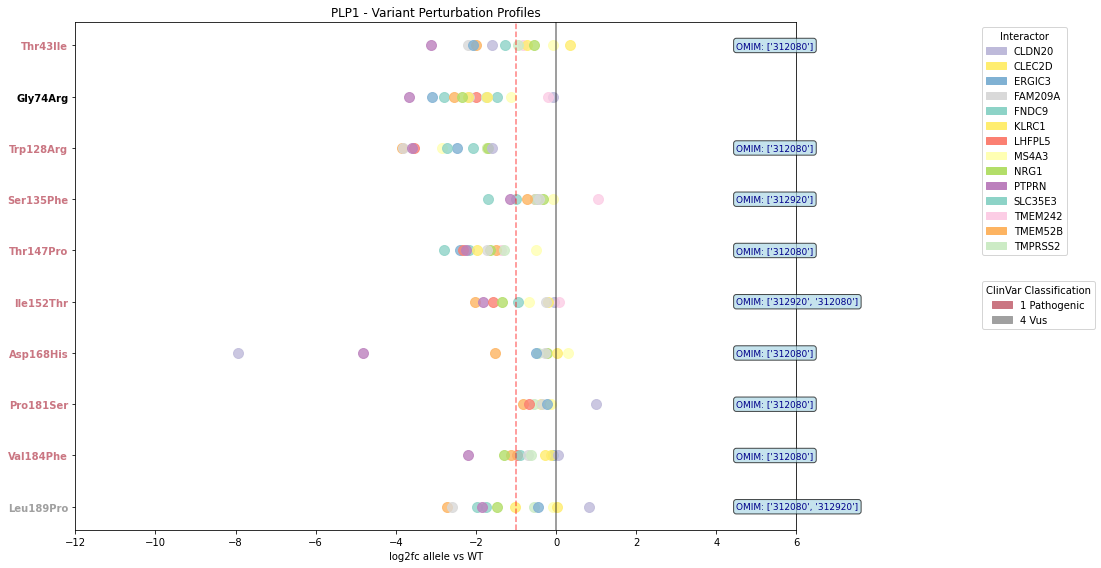


PLP1 summary:
  Number of variants: 10
  Number of interactors: 14
  Total interactions: 112


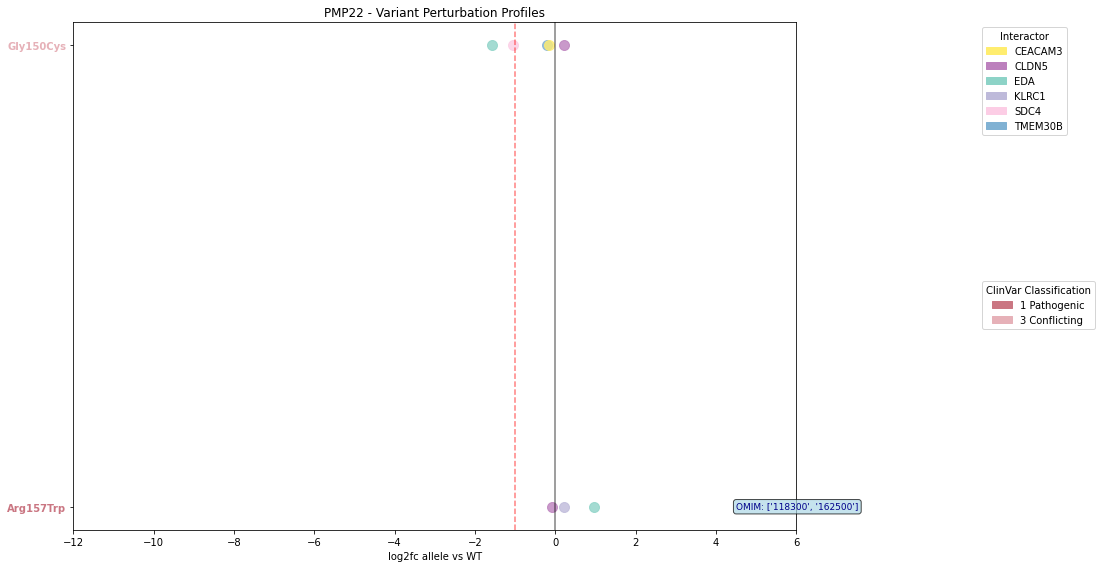


PMP22 summary:
  Number of variants: 2
  Number of interactors: 6
  Total interactions: 8


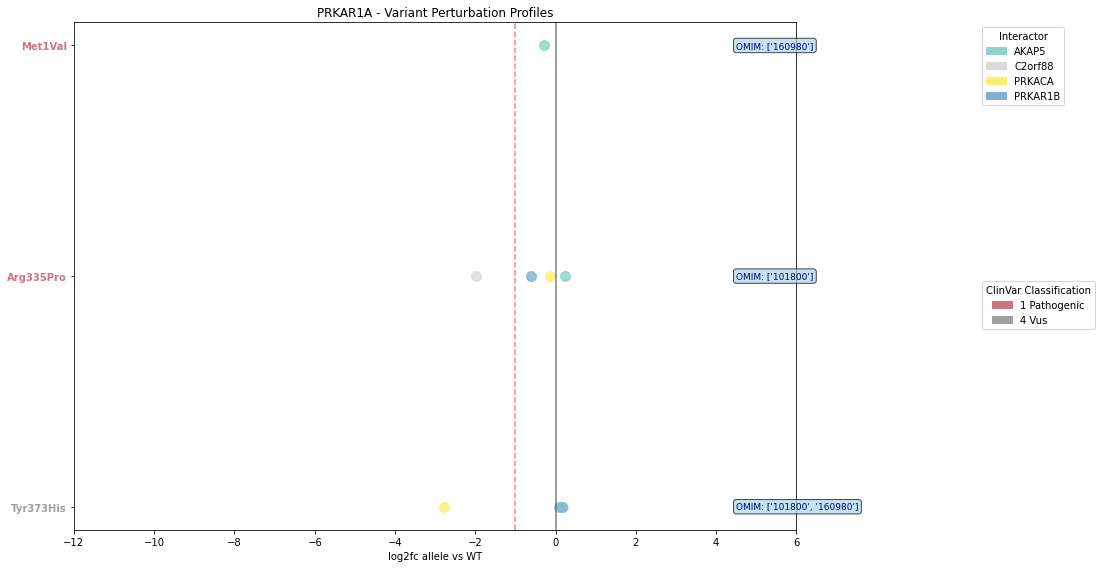


PRKAR1A summary:
  Number of variants: 3
  Number of interactors: 4
  Total interactions: 9


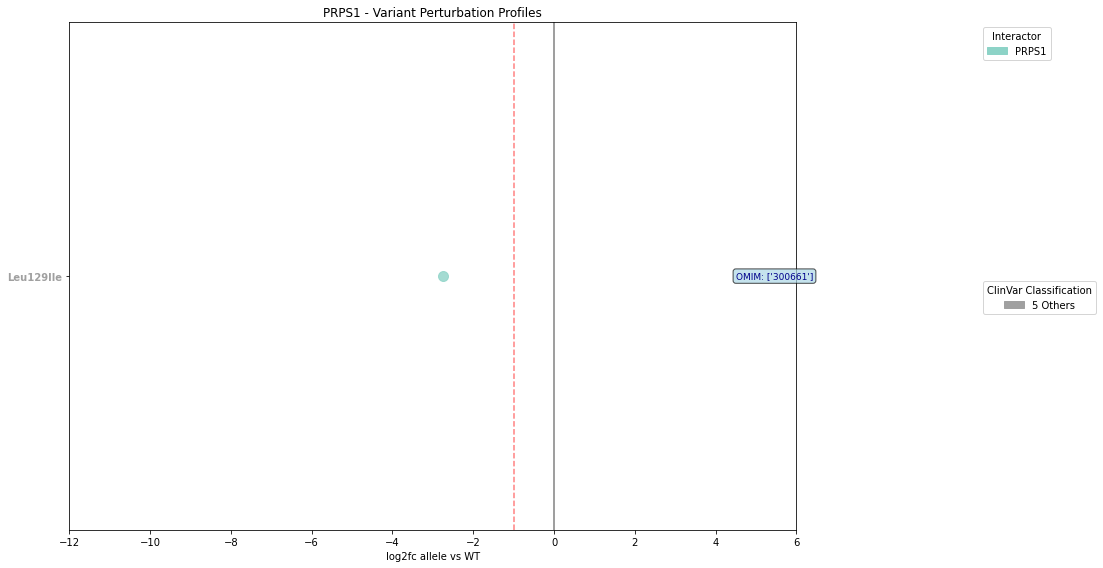


PRPS1 summary:
  Number of variants: 1
  Number of interactors: 1
  Total interactions: 1


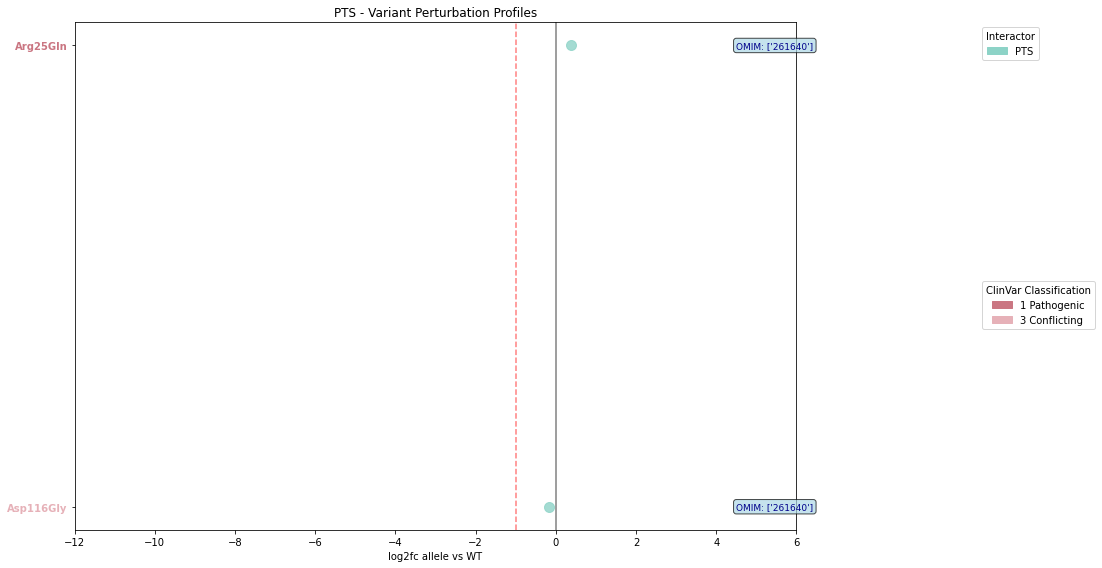


PTS summary:
  Number of variants: 2
  Number of interactors: 1
  Total interactions: 2


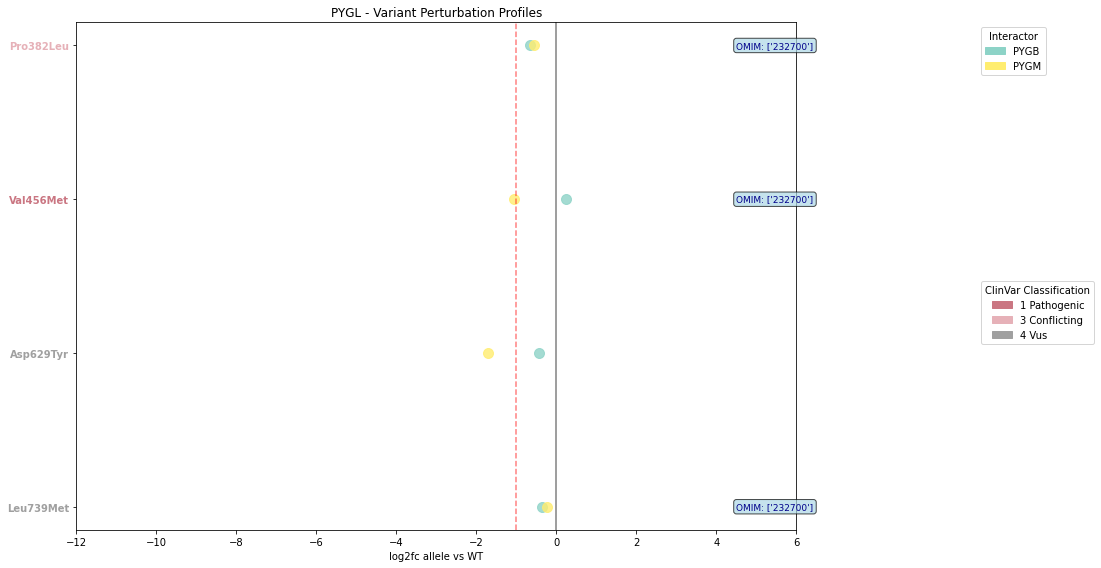


PYGL summary:
  Number of variants: 4
  Number of interactors: 2
  Total interactions: 8


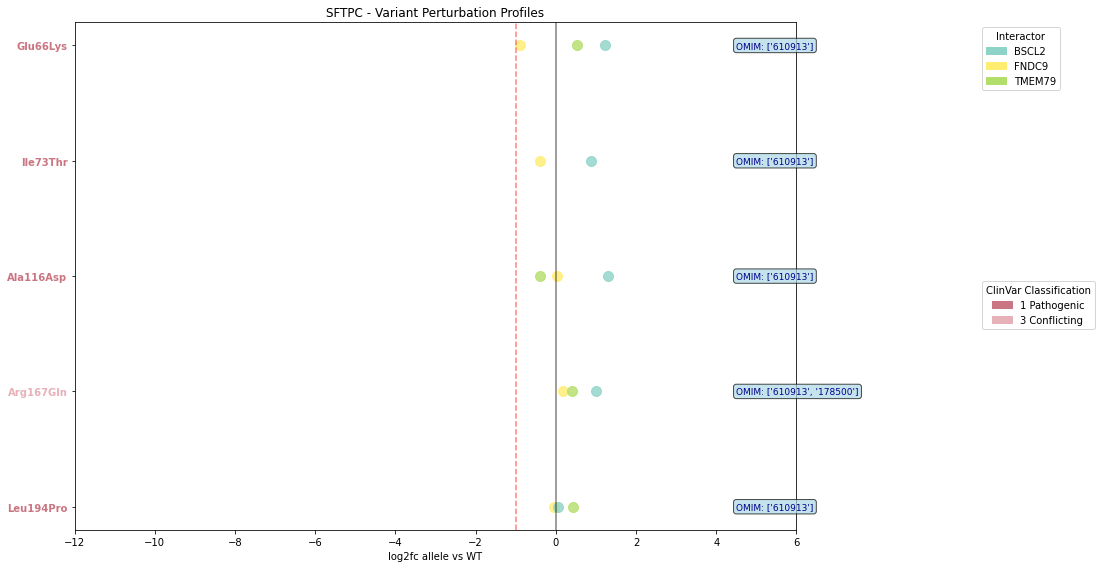


SFTPC summary:
  Number of variants: 5
  Number of interactors: 3
  Total interactions: 14


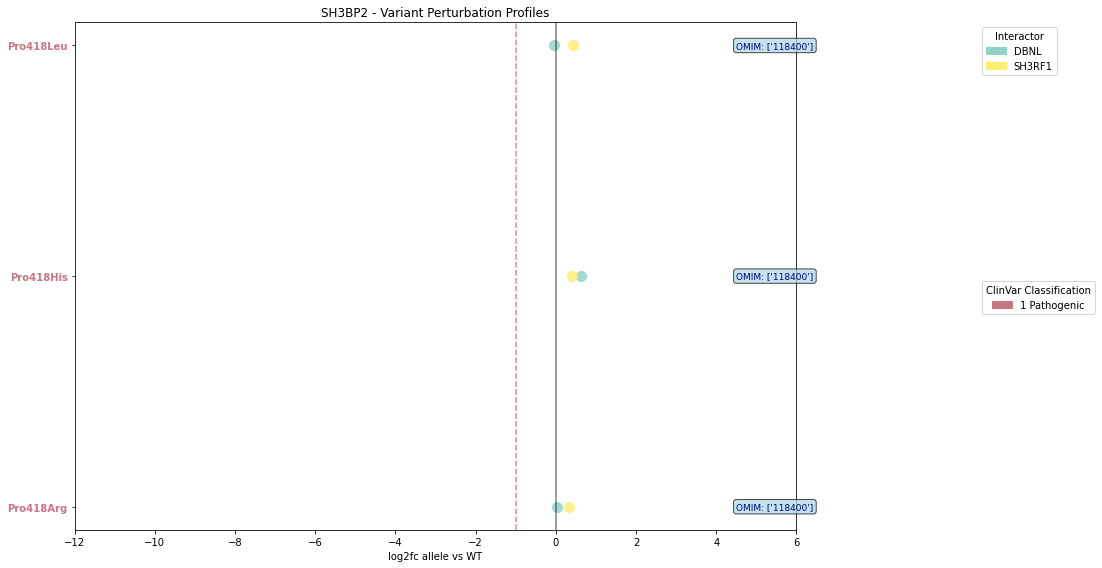


SH3BP2 summary:
  Number of variants: 3
  Number of interactors: 2
  Total interactions: 6


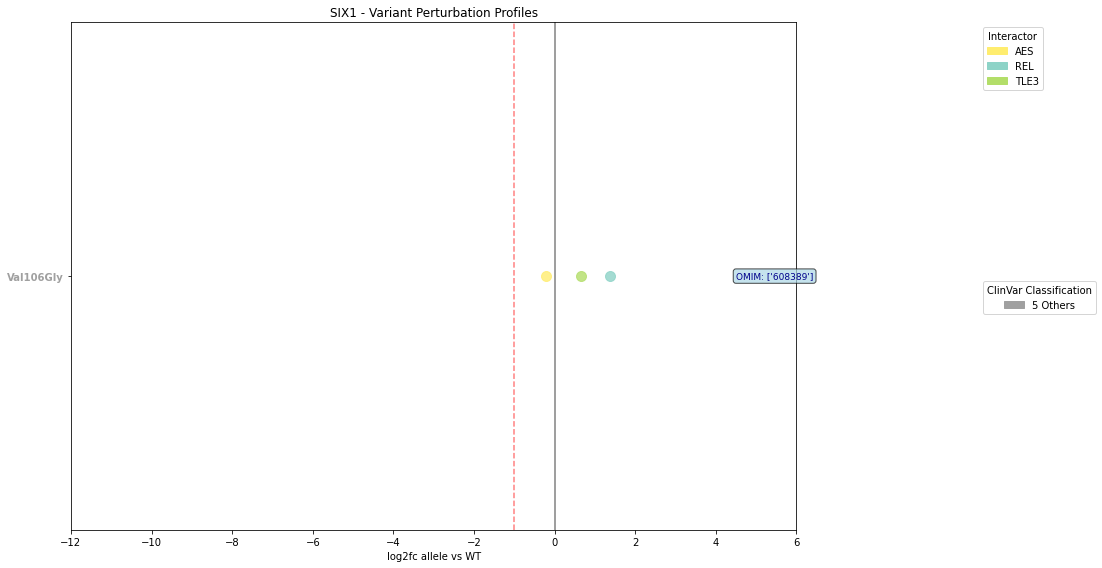


SIX1 summary:
  Number of variants: 1
  Number of interactors: 3
  Total interactions: 3


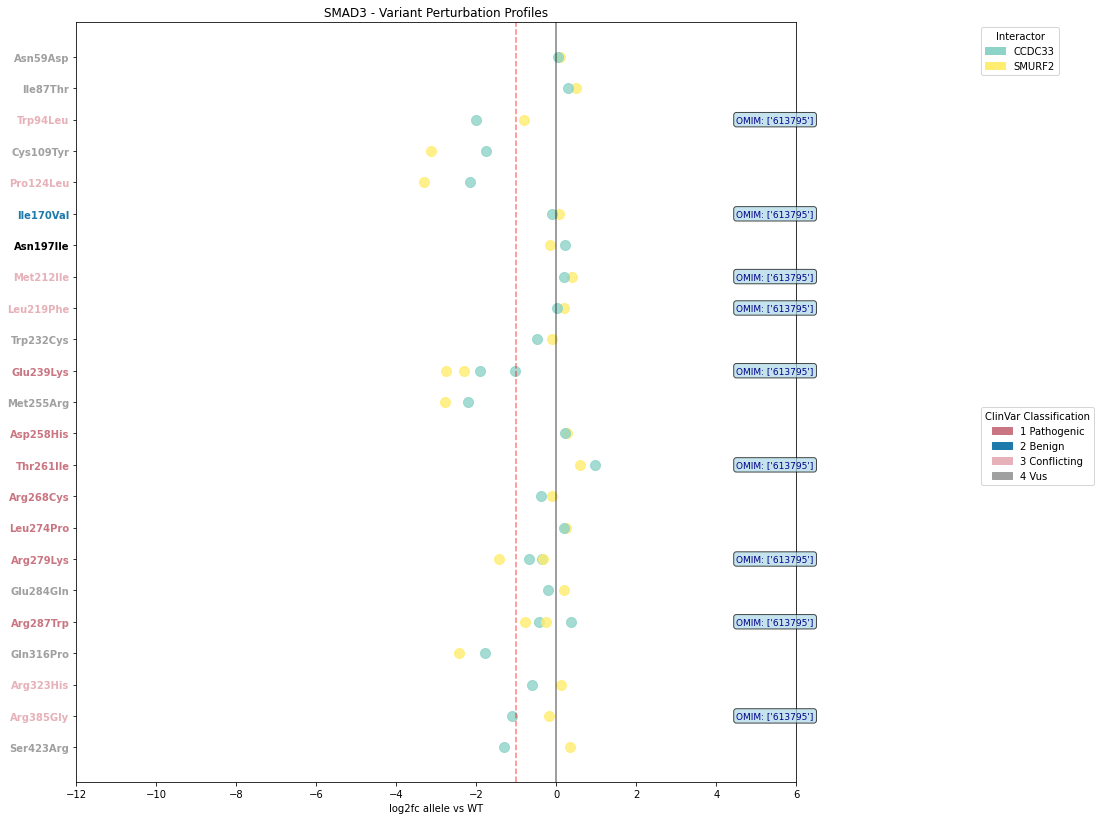


SMAD3 summary:
  Number of variants: 23
  Number of interactors: 2
  Total interactions: 52


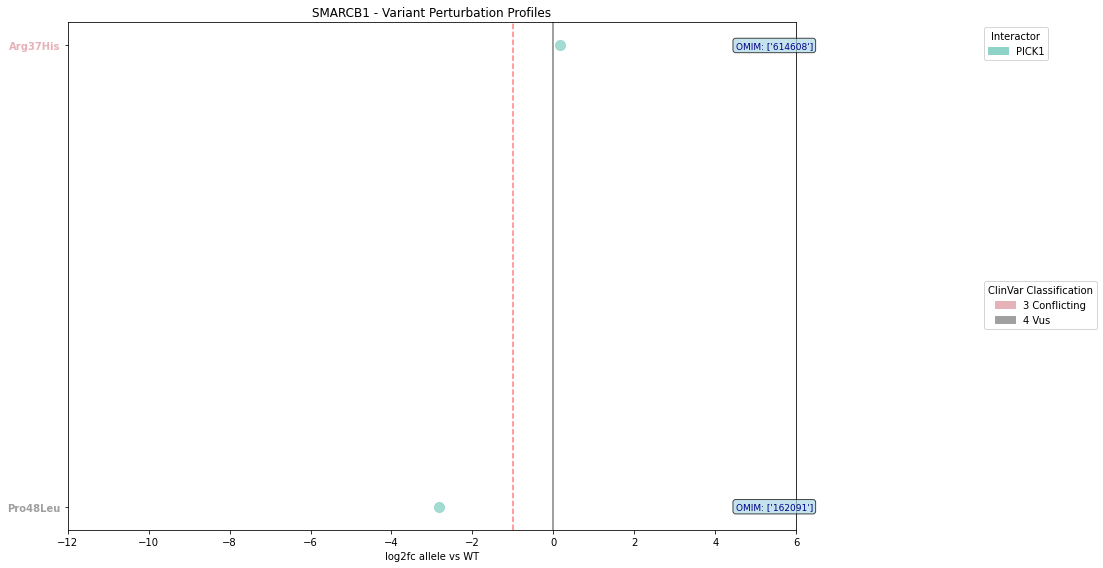


SMARCB1 summary:
  Number of variants: 2
  Number of interactors: 1
  Total interactions: 2


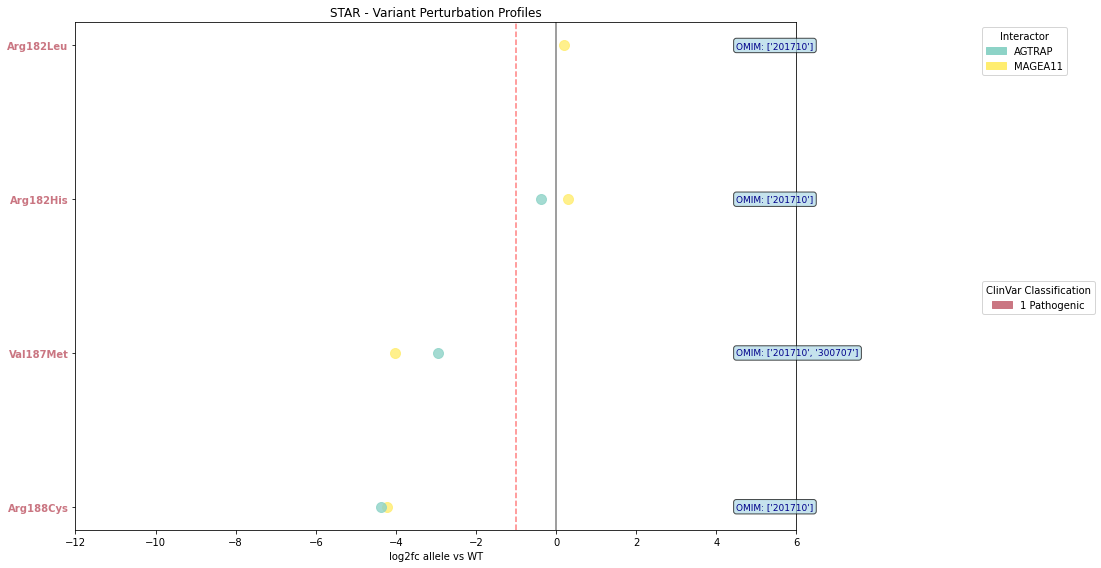


STAR summary:
  Number of variants: 4
  Number of interactors: 2
  Total interactions: 7


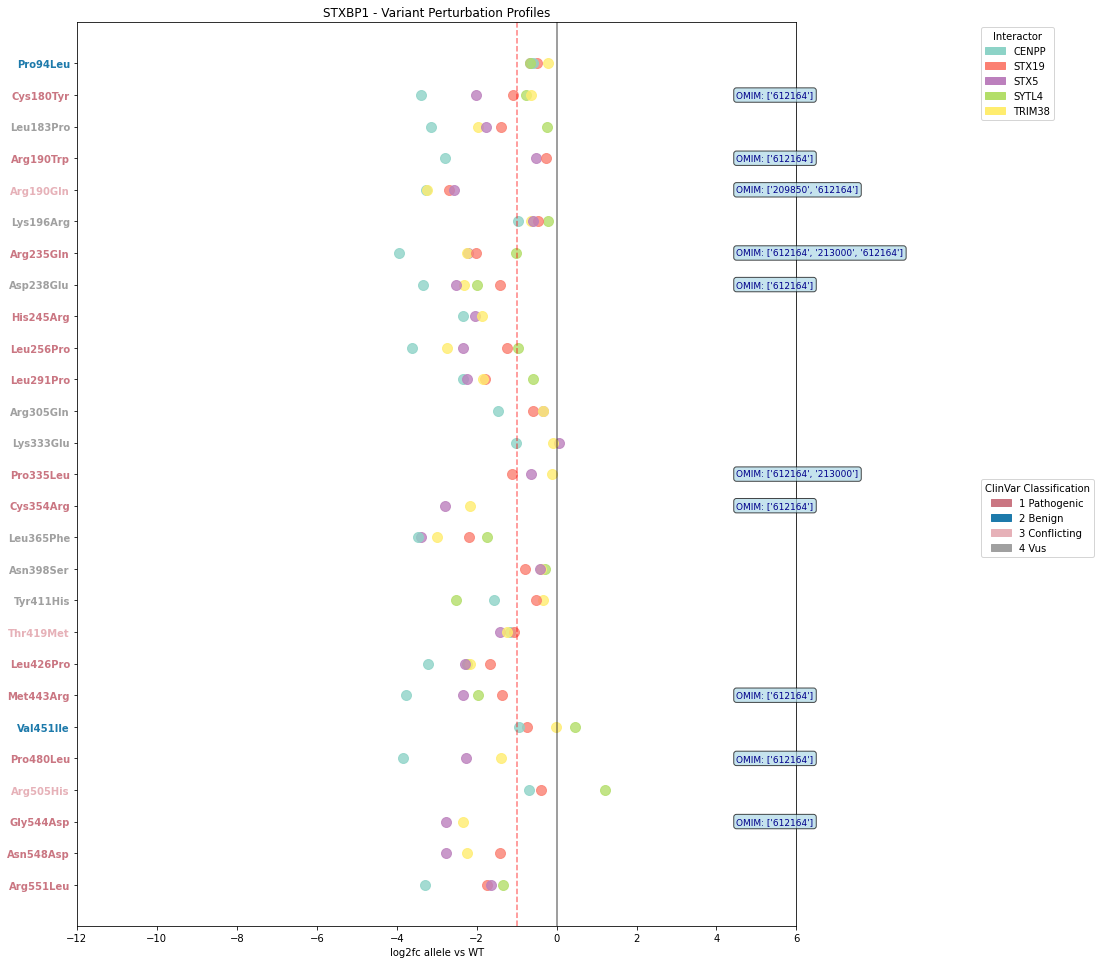


STXBP1 summary:
  Number of variants: 27
  Number of interactors: 5
  Total interactions: 107


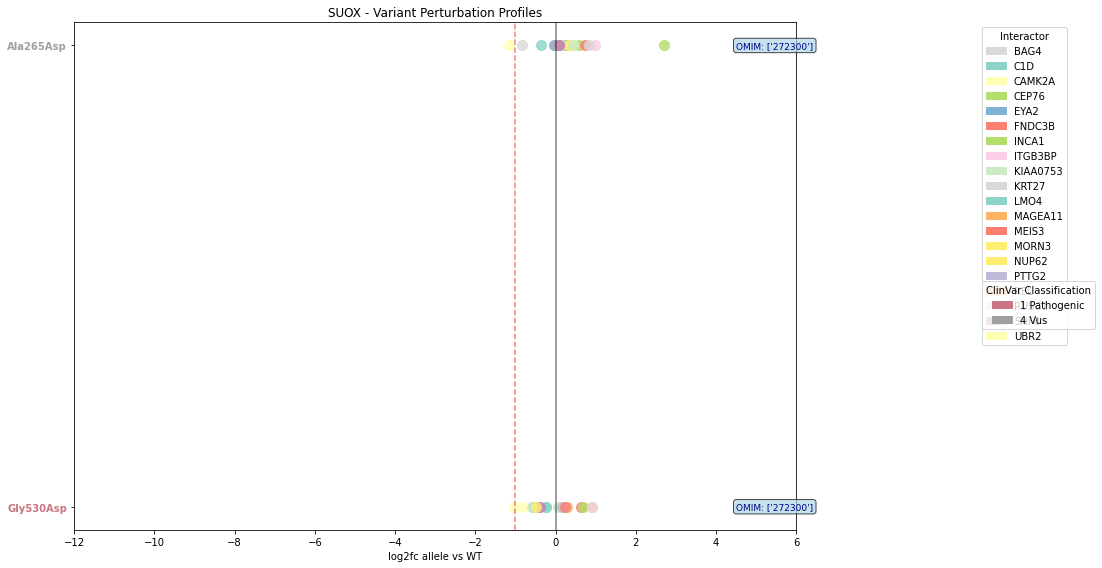


SUOX summary:
  Number of variants: 2
  Number of interactors: 20
  Total interactions: 38


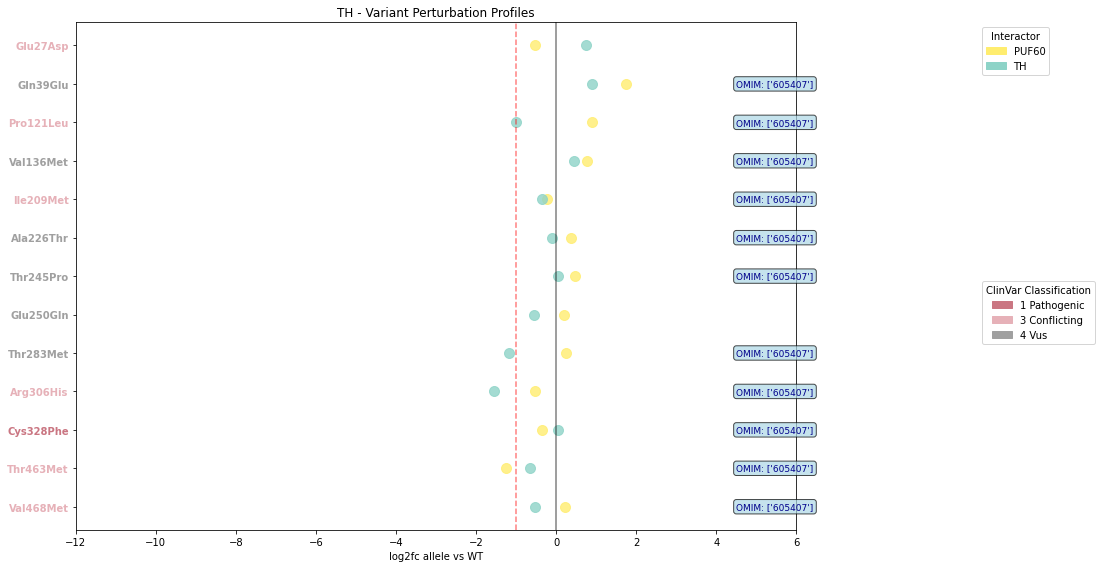


TH summary:
  Number of variants: 13
  Number of interactors: 2
  Total interactions: 26


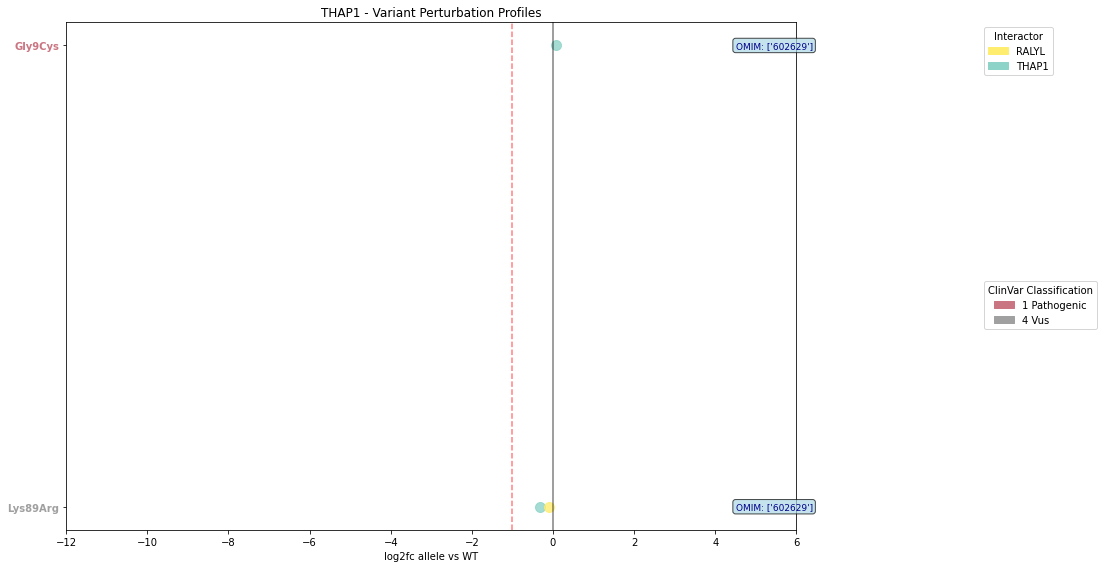


THAP1 summary:
  Number of variants: 2
  Number of interactors: 2
  Total interactions: 3


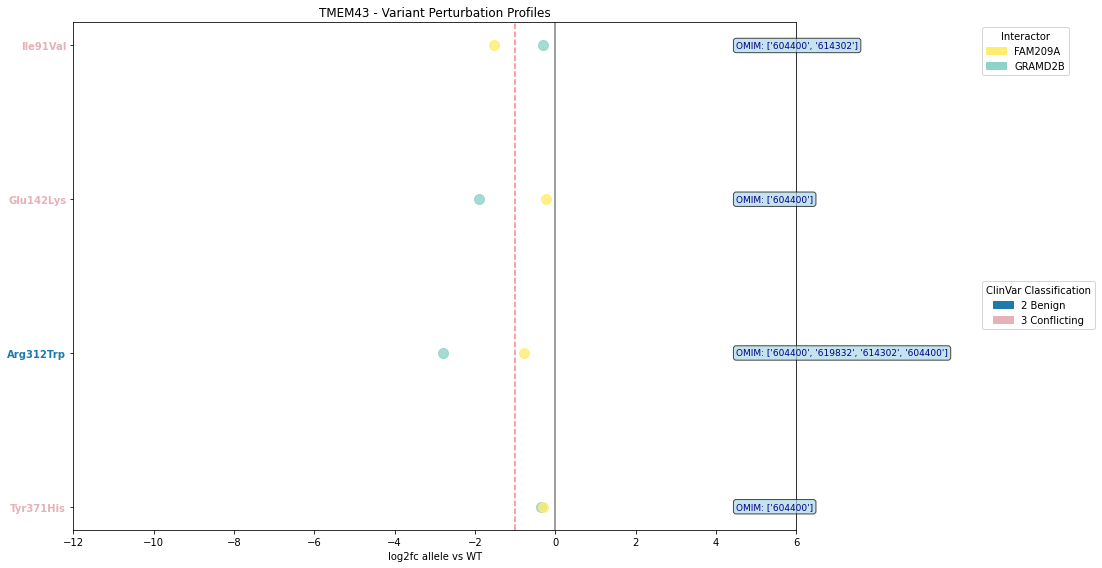


TMEM43 summary:
  Number of variants: 4
  Number of interactors: 2
  Total interactions: 8


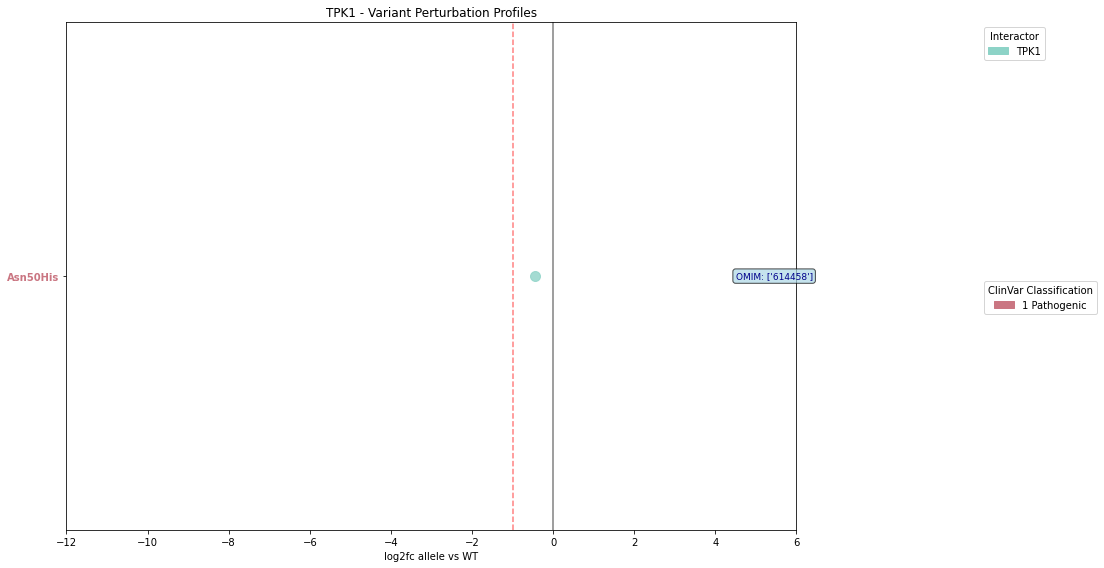


TPK1 summary:
  Number of variants: 1
  Number of interactors: 1
  Total interactions: 1


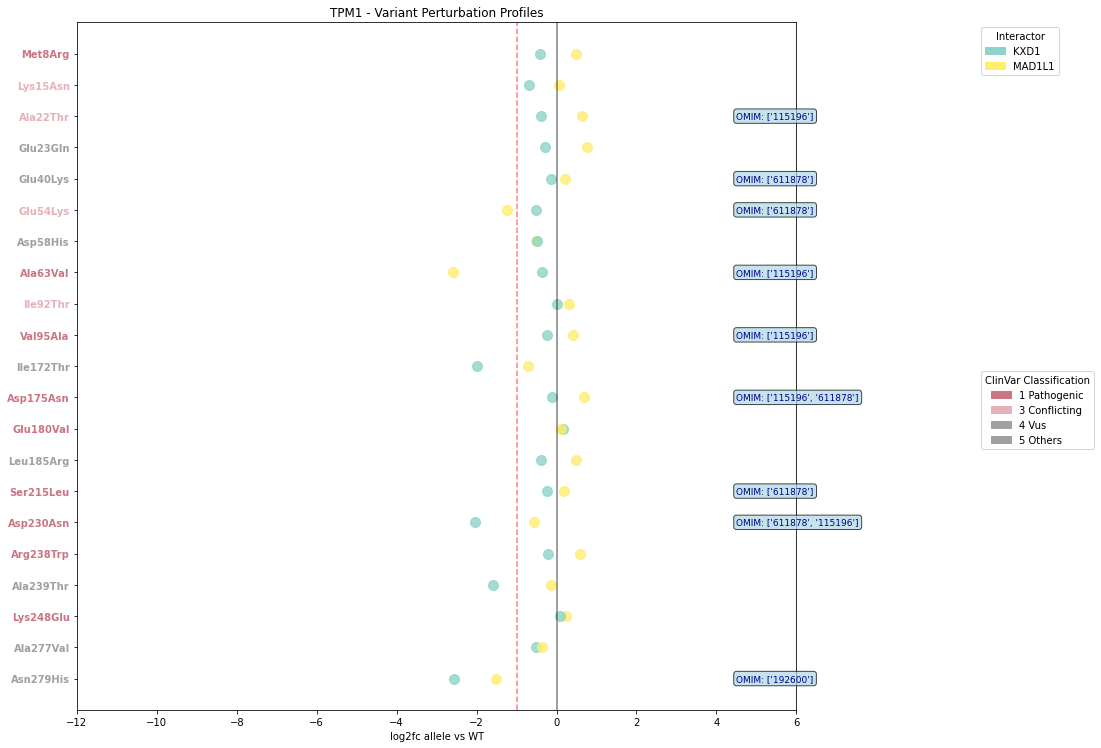


TPM1 summary:
  Number of variants: 21
  Number of interactors: 2
  Total interactions: 42


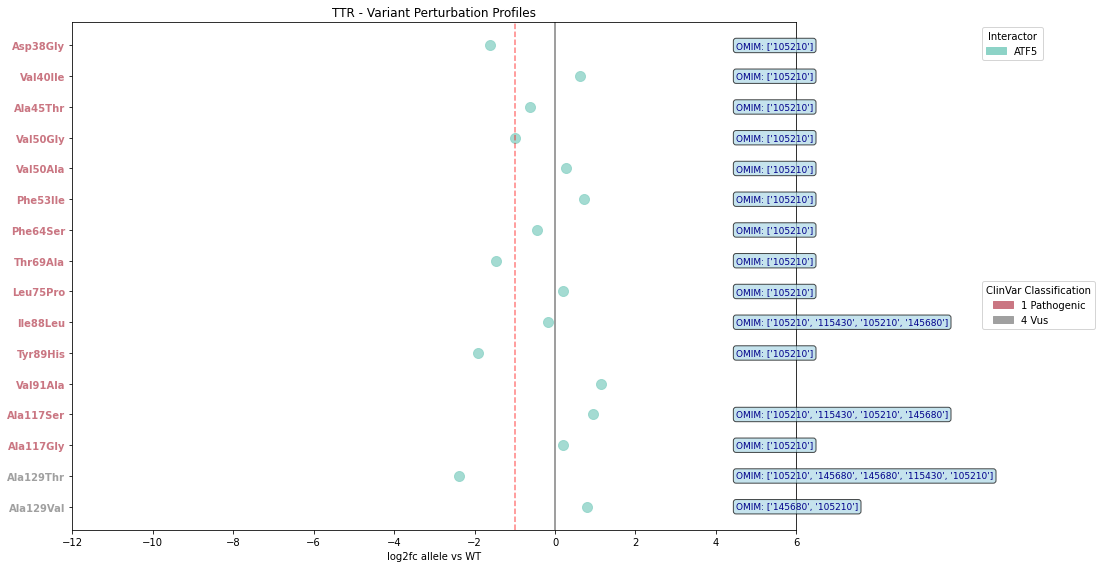


TTR summary:
  Number of variants: 16
  Number of interactors: 1
  Total interactions: 16


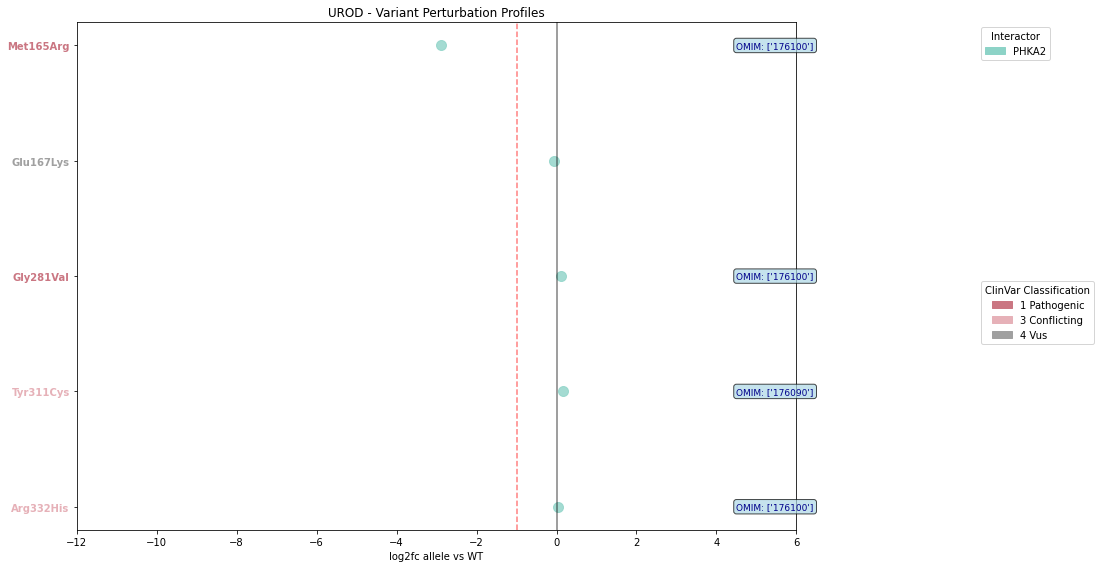


UROD summary:
  Number of variants: 5
  Number of interactors: 1
  Total interactions: 5


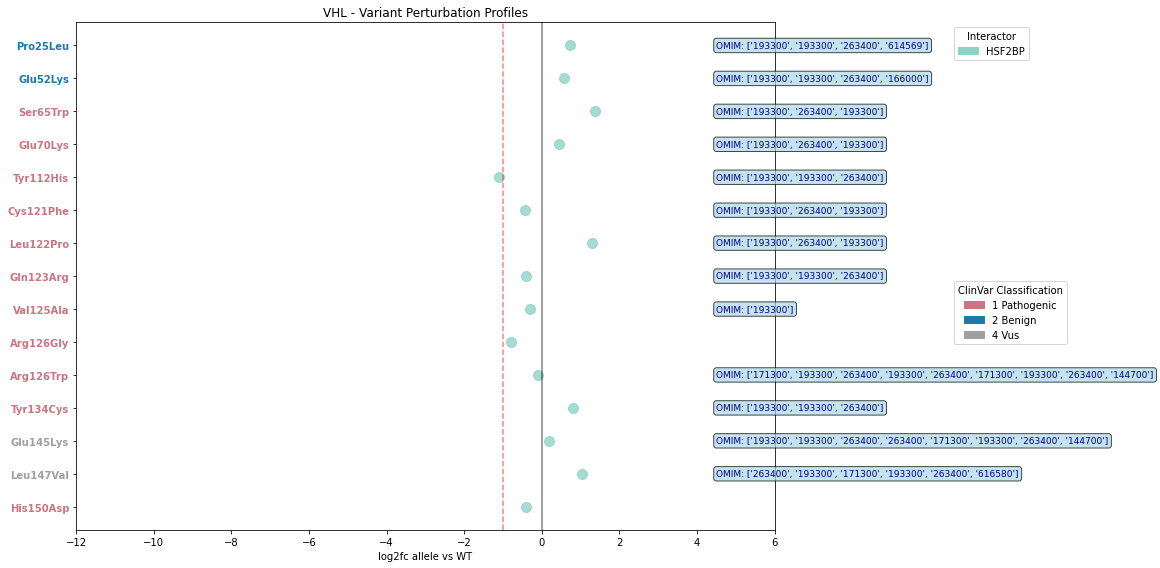


VHL summary:
  Number of variants: 15
  Number of interactors: 1
  Total interactions: 15


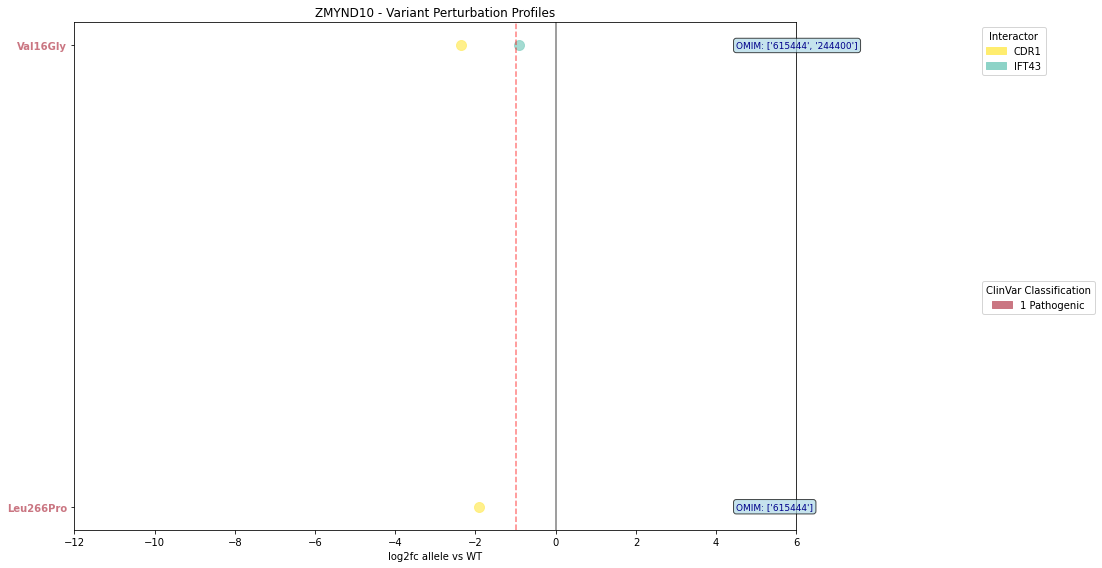


ZMYND10 summary:
  Number of variants: 2
  Number of interactors: 2
  Total interactions: 3


In [8]:
import matplotlib.pyplot as plt
import seaborn as sns
import re
from matplotlib.patches import Patch

# Create plots for all genes
for gene in sorted(scores_pd.symbol.unique().tolist()):
    gene_data = scores.filter(pl.col("symbol") == gene)
    
    if gene_data.shape[0] == 0:
        print(f"No data found for {gene}")
        continue
    
    # Convert to pandas for easier plotting
    gene_pd = gene_data.to_pandas()
    
    # Extract position numbers and sort variants
    def extract_position(aa_change):
        match = re.search(r'(\d+)', aa_change)
        return int(match.group(1)) if match else 0
    
    variants = gene_pd['aa_change'].unique()
    variants_sorted = sorted(variants, key=extract_position, reverse=True)
    interactors = gene_pd['ad_symbol'].unique()
    
    # Create the plot with extra space for OMIM annotations
    fig, ax = plt.subplots(figsize=(16, max(8, len(variants) * 0.5)))
    
    # Color palette for interactors
    colors = plt.cm.Set3(np.linspace(0, 1, len(interactors)))
    interactor_colors = dict(zip(interactors, colors))
    
    # Plot each variant (using sorted order)
    for i, variant in enumerate(variants_sorted):
        variant_data = gene_pd[gene_pd['aa_change'] == variant]
        
        for _, row in variant_data.iterrows():
            interactor = row['ad_symbol']
            log2fc = row['log2fc']
            
            ax.scatter(log2fc, i, 
                      color=interactor_colors[interactor], 
                      s=100, 
                      alpha=0.8,
                      label=interactor if i == 0 else "")
    
    # Add vertical lines
    ax.axvline(x=0, color='black', linestyle='-', alpha=0.5)
    ax.axvline(x=-1, color='red', linestyle='--', alpha=0.5, label='Perturbation threshold')
    
    # Customize plot with colored variant labels and OMIM annotations
    ax.set_yticks(range(len(variants_sorted)))
    
    # Color y-axis labels based on ClinVar classification and add OMIM IDs
    colored_labels = []
    clinvar_categories_used = set()
    for i, variant in enumerate(variants_sorted):
        # Get ClinVar classification for this variant
        variant_row = gene_pd[gene_pd['aa_change'] == variant].iloc[0]
        clinvar_category = variant_row.get('clinvar_clnsig_clean', None)
        label_color = palette_dict["clinvar_clnsig_clean"].get(clinvar_category, "black")
        colored_labels.append((variant, label_color))
        if clinvar_category:
            clinvar_categories_used.add(clinvar_category)
        
        # Add OMIM ID annotation to the right of the plot
        omim_id = variant_row.get('OMIM_IDs', None)
        if omim_id and pd.notna(omim_id):
            # Position the OMIM text to the right of the plot area
            ax.text(4.5, i, f"OMIM: {omim_id}", 
                   verticalalignment='center', 
                   fontsize=9, 
                   color='darkblue',
                   bbox=dict(boxstyle="round,pad=0.3", facecolor="lightblue", alpha=0.7))
    
    ax.set_yticklabels([label for label, color in colored_labels])
    
    # Apply colors to y-tick labels
    for i, (label, color) in enumerate(colored_labels):
        ax.get_yticklabels()[i].set_color(color)
        ax.get_yticklabels()[i].set_fontweight('bold')
    
    ax.set_xlabel('log2fc allele vs WT')
    ax.set_title(f'{gene} - Variant Perturbation Profiles')
    ax.set_xlim(-12, 6)  # Extended to make room for OMIM annotations
    

    # Create legend patches for all interactors
    interactor_patches = []
    for interactor in sorted(interactors):
        color = interactor_colors[interactor]
        interactor_patches.append(Patch(color=color, label=interactor))

    interactor_legend = ax.legend(handles=interactor_patches, 
                                bbox_to_anchor=(1.25, 1), loc='upper left', 
                                title='Interactor')
    # Add ClinVar color legend
    clinvar_patches = []
    for category in sorted(clinvar_categories_used):
        color = palette_dict["clinvar_clnsig_clean"].get(category, "black")
        # Clean up category name for display
        display_name = category.replace('clinvar_clnsig_', '').replace('_', ' ').title()
        clinvar_patches.append(Patch(color=color, label=display_name))
    
    if clinvar_patches:
        clinvar_legend = ax.legend(handles=clinvar_patches, 
                                  bbox_to_anchor=(1.25, 0.5), loc='upper left',
                                  title='ClinVar Classification')
        
        # Add the interactor legend back (matplotlib removes it when adding new legend)
        ax.add_artist(interactor_legend)
    
    plt.tight_layout()
    
    plt.savefig(f"{outputs_dir}/log2fc_plots/{gene}.pdf", dpi=300)
    plt.show()
    
    # if gene == 'STXBP1':
    #     break
    
    print(f"\n{gene} summary:")
    print(f"  Number of variants: {len(variants_sorted)}")
    print(f"  Number of interactors: {len(interactors)}")
    print(f"  Total interactions: {gene_pd.shape[0]}")

In [9]:
interesting_genes = ['STXBP1', 'LITAF', 'MLH1', 'PLP1']

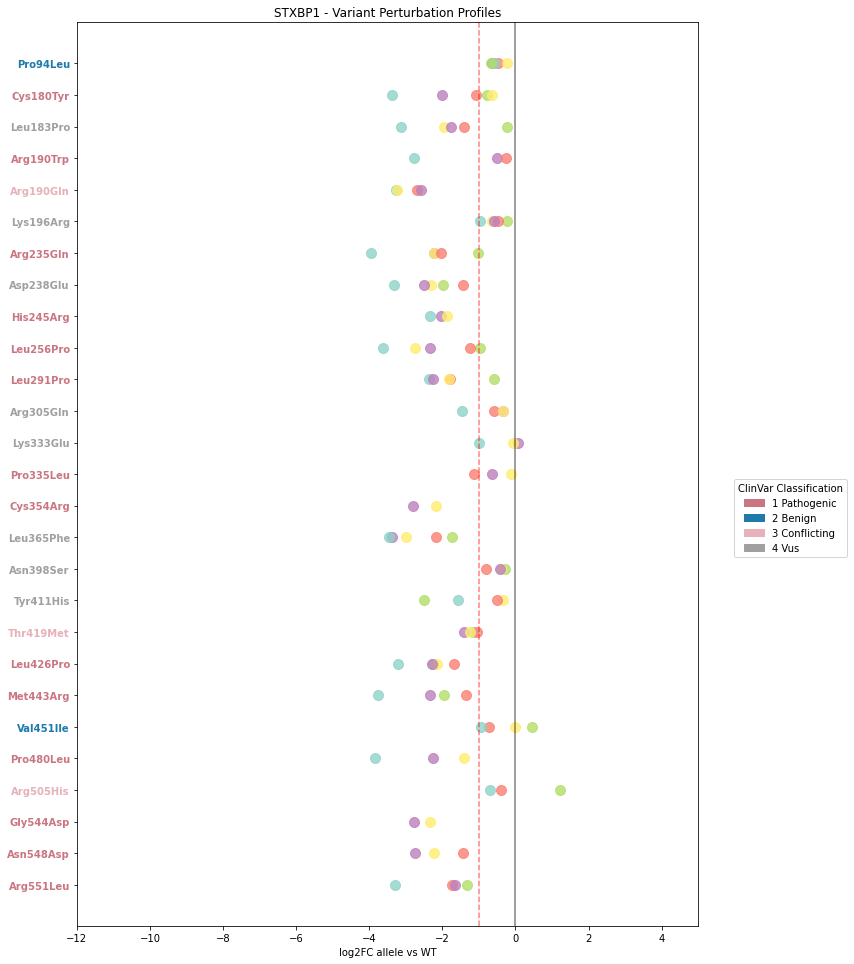


STXBP1 summary:
  Number of variants: 27
  Number of interactors: 5
  Total interactions: 107


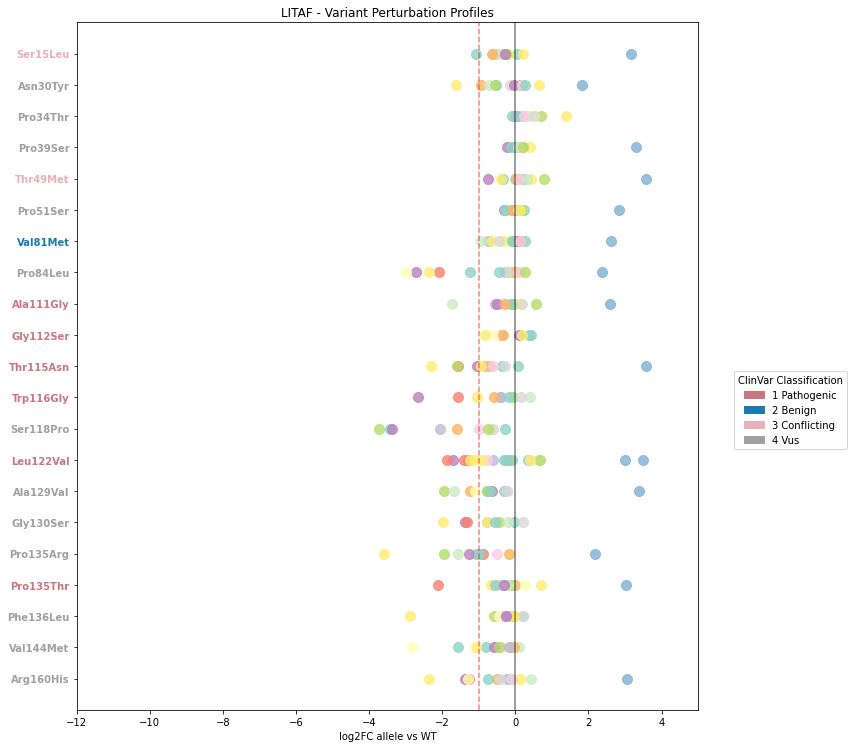


LITAF summary:
  Number of variants: 21
  Number of interactors: 15
  Total interactions: 276


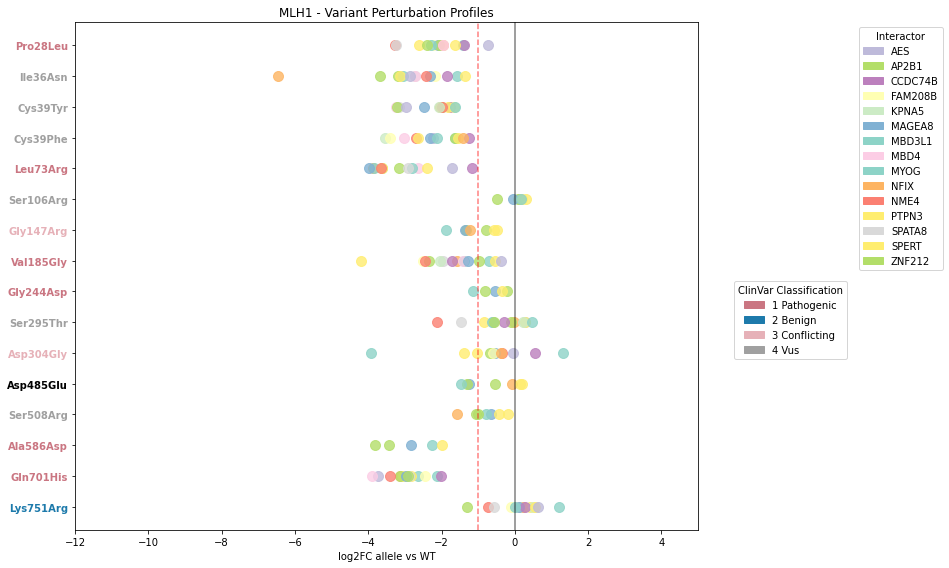


MLH1 summary:
  Number of variants: 16
  Number of interactors: 15
  Total interactions: 174


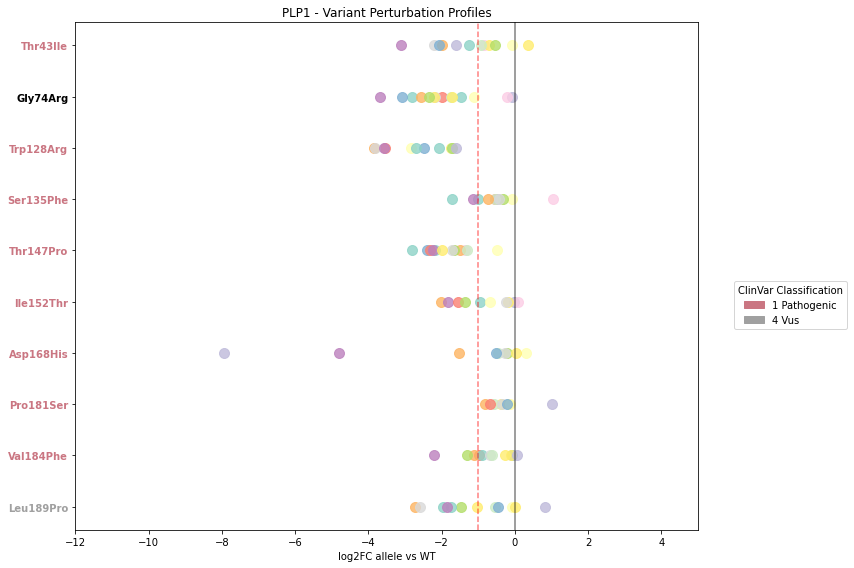


PLP1 summary:
  Number of variants: 10
  Number of interactors: 14
  Total interactions: 112


In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
import re
from matplotlib.patches import Patch

# Create plots for the interesting genes
for gene in interesting_genes:
    gene_data = scores.filter(pl.col("symbol") == gene)
    
    if gene_data.shape[0] == 0:
        print(f"No data found for {gene}")
        continue
    
    # Convert to pandas for easier plotting
    gene_pd = gene_data.to_pandas()
    
    # Extract position numbers and sort variants
    def extract_position(aa_change):
        match = re.search(r'(\d+)', aa_change)
        return int(match.group(1)) if match else 0
    
    variants = gene_pd['aa_change'].unique()
    variants_sorted = sorted(variants, key=extract_position, reverse=True)
    interactors = gene_pd['ad_symbol'].unique()
    
    # Create the plot
    fig, ax = plt.subplots(figsize=(12, max(8, len(variants) * 0.5)))
    
    # Color palette for interactors
    colors = plt.cm.Set3(np.linspace(0, 1, len(interactors)))
    interactor_colors = dict(zip(interactors, colors))
    
    # Plot each variant (using sorted order)
    for i, variant in enumerate(variants_sorted):
        variant_data = gene_pd[gene_pd['aa_change'] == variant]
        
        for _, row in variant_data.iterrows():
            interactor = row['ad_symbol']
            log2fc = row['log2fc']
            
            ax.scatter(log2fc, i, 
                      color=interactor_colors[interactor], 
                      s=100, 
                      alpha=0.8,
                      label=interactor if i == 0 else "")
    
    # Add vertical lines
    ax.axvline(x=0, color='black', linestyle='-', alpha=0.5)
    ax.axvline(x=-1, color='red', linestyle='--', alpha=0.5, label='Perturbation threshold')
    
    # Customize plot with colored variant labels
    ax.set_yticks(range(len(variants_sorted)))
    
    # Color y-axis labels based on ClinVar classification
    colored_labels = []
    clinvar_categories_used = set()
    for variant in variants_sorted:
        # Get ClinVar classification for this variant
        variant_row = gene_pd[gene_pd['aa_change'] == variant].iloc[0]
        clinvar_category = variant_row.get('clinvar_clnsig_clean', None)
        label_color = palette_dict["clinvar_clnsig_clean"].get(clinvar_category, "black")
        colored_labels.append((variant, label_color))
        if clinvar_category:
            clinvar_categories_used.add(clinvar_category)
    
    ax.set_yticklabels([label for label, color in colored_labels])
    
    # Apply colors to y-tick labels
    for i, (label, color) in enumerate(colored_labels):
        ax.get_yticklabels()[i].set_color(color)
        ax.get_yticklabels()[i].set_fontweight('bold')
    
    ax.set_xlabel('log2FC allele vs WT')
    ax.set_title(f'{gene} - Variant Perturbation Profiles')
    ax.set_xlim(-12, 5)
    
    
    # Create legend patches for all interactors
    interactor_patches = []
    for interactor in sorted(interactors):
        color = interactor_colors[interactor]
        interactor_patches.append(Patch(color=color, label=interactor))

    interactor_legend = ax.legend(handles=interactor_patches, 
                                 bbox_to_anchor=(1.25, 1), loc='upper left', 
                                 title='Interactor')
    
    # Add ClinVar color legend
    clinvar_patches = []
    for category in sorted(clinvar_categories_used):
        color = palette_dict["clinvar_clnsig_clean"].get(category, "black")
        # Clean up category name for display
        display_name = category.replace('clinvar_clnsig_', '').replace('_', ' ').title()
        clinvar_patches.append(Patch(color=color, label=display_name))
    
    if clinvar_patches:
        clinvar_legend = ax.legend(handles=clinvar_patches, 
                                  bbox_to_anchor=(1.05, 0.5), loc='upper left',
                                  title='ClinVar Classification')
        
        # Add the interactor legend back (matplotlib removes it when adding new legend)
        ax.add_artist(interactor_legend)
    
    plt.tight_layout()
    plt.show()
    
    print(f"\n{gene} summary:")
    print(f"  Number of variants: {len(variants_sorted)}")
    print(f"  Number of interactors: {len(interactors)}")
    print(f"  Total interactions: {gene_pd.shape[0]}")

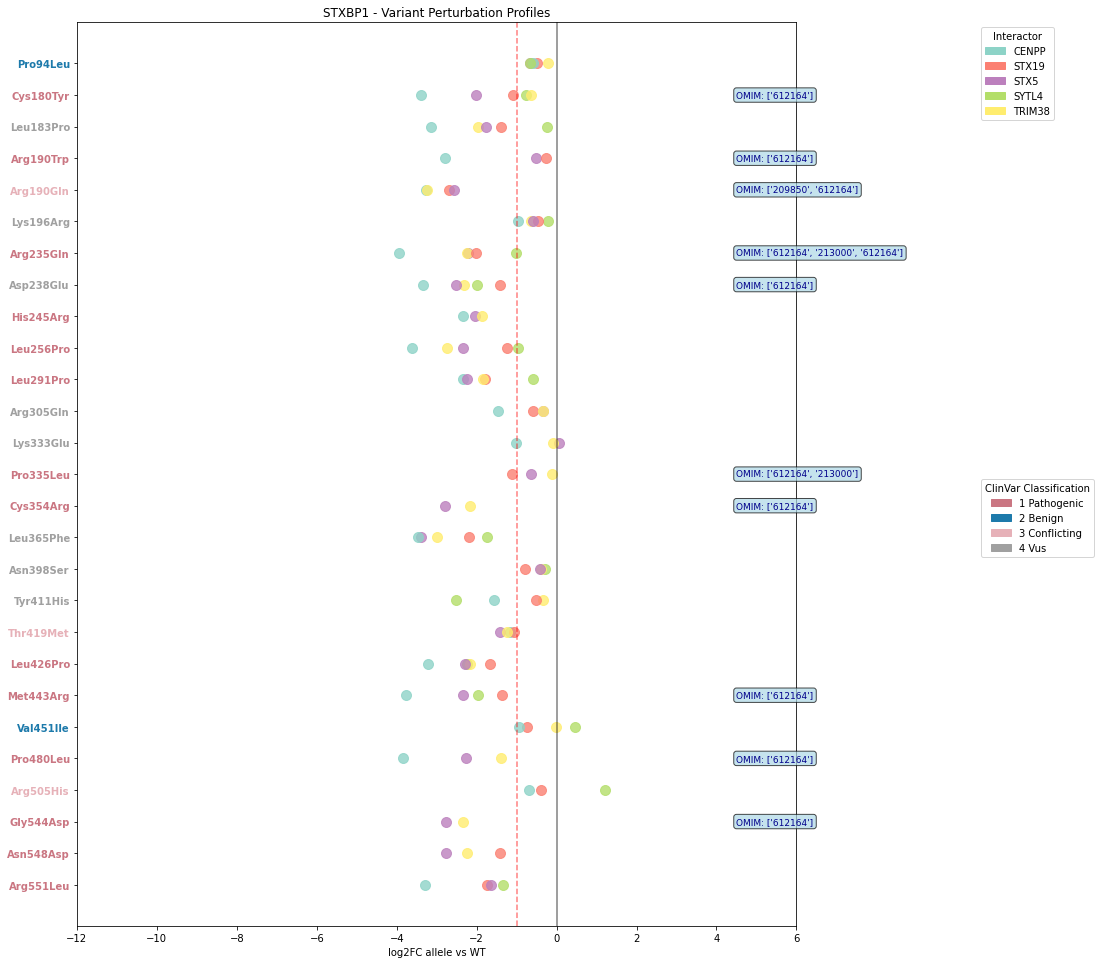


STXBP1 summary:
  Number of variants: 27
  Number of interactors: 5
  Total interactions: 107


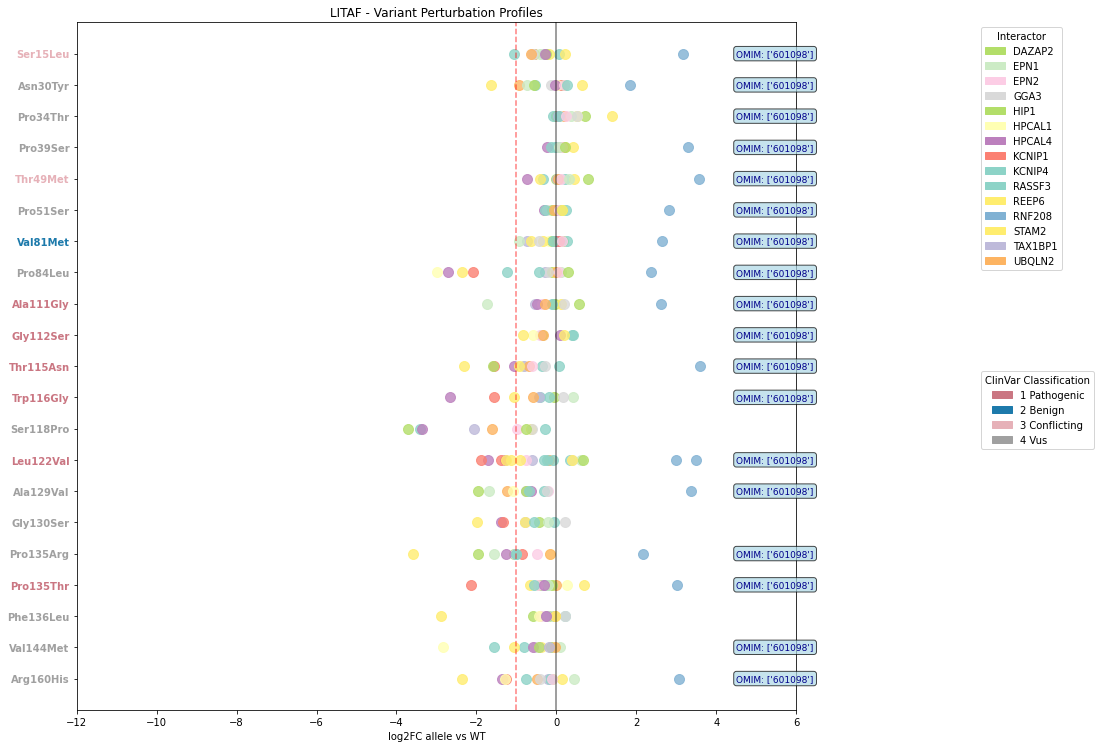


LITAF summary:
  Number of variants: 21
  Number of interactors: 15
  Total interactions: 276


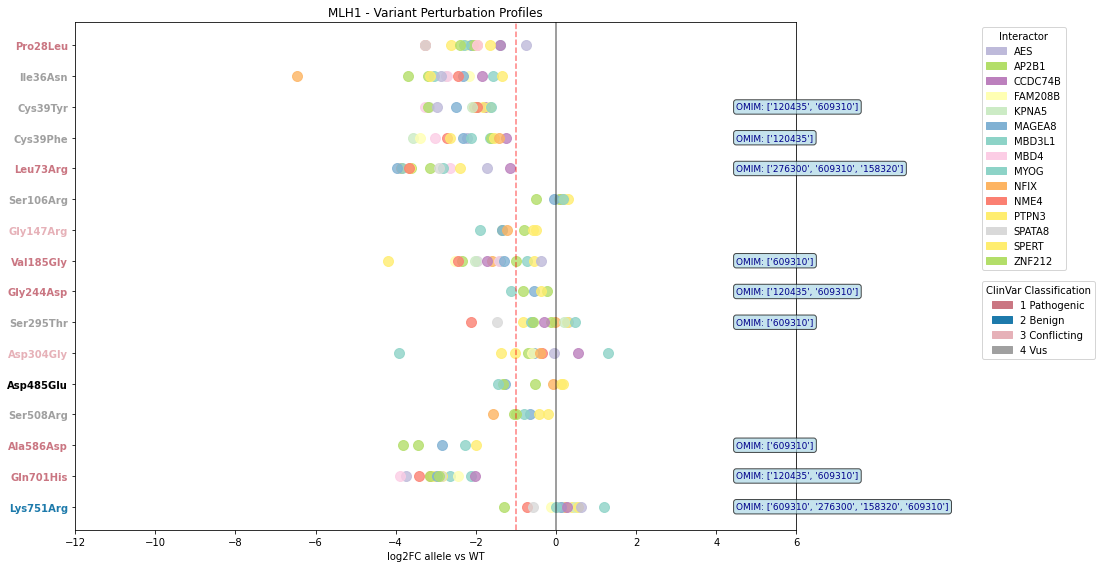


MLH1 summary:
  Number of variants: 16
  Number of interactors: 15
  Total interactions: 174


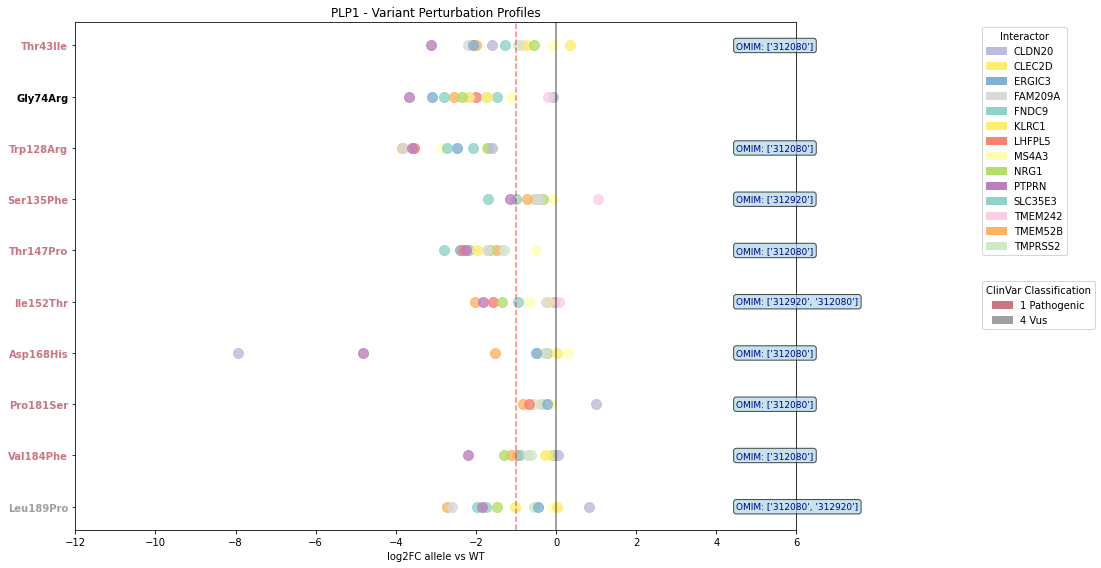


PLP1 summary:
  Number of variants: 10
  Number of interactors: 14
  Total interactions: 112


In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
import re
from matplotlib.patches import Patch

# Create plots for the interesting genes
for gene in interesting_genes:
    gene_data = scores.filter(pl.col("symbol") == gene)
    
    if gene_data.shape[0] == 0:
        print(f"No data found for {gene}")
        continue
    
    # Convert to pandas for easier plotting
    gene_pd = gene_data.to_pandas()
    
    # Extract position numbers and sort variants
    def extract_position(aa_change):
        match = re.search(r'(\d+)', aa_change)
        return int(match.group(1)) if match else 0
    
    variants = gene_pd['aa_change'].unique()
    variants_sorted = sorted(variants, key=extract_position, reverse=True)
    interactors = gene_pd['ad_symbol'].unique()
    
    # Create the plot with extra space for OMIM annotations
    fig, ax = plt.subplots(figsize=(16, max(8, len(variants) * 0.5)))
    
    # Color palette for interactors
    colors = plt.cm.Set3(np.linspace(0, 1, len(interactors)))
    interactor_colors = dict(zip(interactors, colors))
    
    # Plot each variant (using sorted order)
    for i, variant in enumerate(variants_sorted):
        variant_data = gene_pd[gene_pd['aa_change'] == variant]
        
        for _, row in variant_data.iterrows():
            interactor = row['ad_symbol']
            log2fc = row['log2fc']
            
            ax.scatter(log2fc, i, 
                      color=interactor_colors[interactor], 
                      s=100, 
                      alpha=0.8,
                      label=interactor if i == 0 else "")
    
    # Add vertical lines
    ax.axvline(x=0, color='black', linestyle='-', alpha=0.5)
    ax.axvline(x=-1, color='red', linestyle='--', alpha=0.5, label='Perturbation threshold')
    
    # Customize plot with colored variant labels and OMIM annotations
    ax.set_yticks(range(len(variants_sorted)))
    
    # Color y-axis labels based on ClinVar classification and add OMIM IDs
    colored_labels = []
    clinvar_categories_used = set()
    for i, variant in enumerate(variants_sorted):
        # Get ClinVar classification for this variant
        variant_row = gene_pd[gene_pd['aa_change'] == variant].iloc[0]
        clinvar_category = variant_row.get('clinvar_clnsig_clean', None)
        label_color = palette_dict["clinvar_clnsig_clean"].get(clinvar_category, "black")
        colored_labels.append((variant, label_color))
        if clinvar_category:
            clinvar_categories_used.add(clinvar_category)
        
        # Add OMIM ID annotation to the right of the plot
        omim_id = variant_row.get('OMIM_IDs', None)
        if omim_id and pd.notna(omim_id):
            # Position the OMIM text to the right of the plot area
            ax.text(4.5, i, f"OMIM: {omim_id}", 
                   verticalalignment='center', 
                   fontsize=9, 
                   color='darkblue',
                   bbox=dict(boxstyle="round,pad=0.3", facecolor="lightblue", alpha=0.7))
    
    ax.set_yticklabels([label for label, color in colored_labels])
    
    # Apply colors to y-tick labels
    for i, (label, color) in enumerate(colored_labels):
        ax.get_yticklabels()[i].set_color(color)
        ax.get_yticklabels()[i].set_fontweight('bold')
    
    ax.set_xlabel('log2FC allele vs WT')
    ax.set_title(f'{gene} - Variant Perturbation Profiles')
    ax.set_xlim(-12, 6)  # Extended to make room for OMIM annotations
    
    
    # Create legend patches for all interactors
    interactor_patches = []
    for interactor in sorted(interactors):
        color = interactor_colors[interactor]
        interactor_patches.append(Patch(color=color, label=interactor))

    interactor_legend = ax.legend(handles=interactor_patches, 
                                 bbox_to_anchor=(1.25, 1), loc='upper left', 
                                 title='Interactor')
    
    
    # Add ClinVar color legend
    clinvar_patches = []
    for category in sorted(clinvar_categories_used):
        color = palette_dict["clinvar_clnsig_clean"].get(category, "black")
        # Clean up category name for display
        display_name = category.replace('clinvar_clnsig_', '').replace('_', ' ').title()
        clinvar_patches.append(Patch(color=color, label=display_name))
    
    if clinvar_patches:
        clinvar_legend = ax.legend(handles=clinvar_patches, 
                                  bbox_to_anchor=(1.25, 0.5), loc='upper left',
                                  title='ClinVar Classification')
        
        # Add the interactor legend back (matplotlib removes it when adding new legend)
        ax.add_artist(interactor_legend)
    
    plt.tight_layout()
    plt.show()
    
    print(f"\n{gene} summary:")
    print(f"  Number of variants: {len(variants_sorted)}")
    print(f"  Number of interactors: {len(interactors)}")
    print(f"  Total interactions: {gene_pd.shape[0]}")

In [12]:
scores_pd = scores.to_pandas()
scores_pd[(scores_pd.db_orf_id == 7982) &
          (scores_pd.db_mut_id == 202799)]

,ad_orf_id,db_orf_id,db_mut_id,retest_batch,n_conditions,summed_consensus_score,lwh1_consensus_score,summed_consensus_score_normalized,lwh1_consensus_score_normalized,wt_summed_score,...,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,variant_class_log2fc,log2fc,perturbed,OMIM_IDs
422,7982,7982,202799,VUSAPWT1B2,1,512.240864,NaN,0.170747,NaN,2341.154340,...,ENSG00000165704,CEGS2,1_Pathogenic,NaN,NaN,HPRT1_Ile132Met,QN,-2.191666,True,['300323']
1043,2860,7982,202799,VUSAPWT1B2,1,0.000000,NaN,0.000000,NaN,2316.993879,...,ENSG00000165704,CEGS2,1_Pathogenic,NaN,NaN,HPRT1_Ile132Met,QN,-12.915191,True,['300323']


In [13]:
scores_pd = scores.to_pandas()
scores_pd[(scores_pd.db_orf_id == 8420) &
          (scores_pd.db_mut_id == 216660)][['symbol', 'aa_change']]

,symbol,aa_change
6,ALAS2,Lys262Gln


In [14]:
scores_pd = scores.to_pandas()
scores_pd[(scores_pd.db_orf_id == 2651) &
          (scores_pd.db_mut_id == 214302)][['symbol', 'aa_change']]

,symbol,aa_change
749,CLN6,Gly123Asp


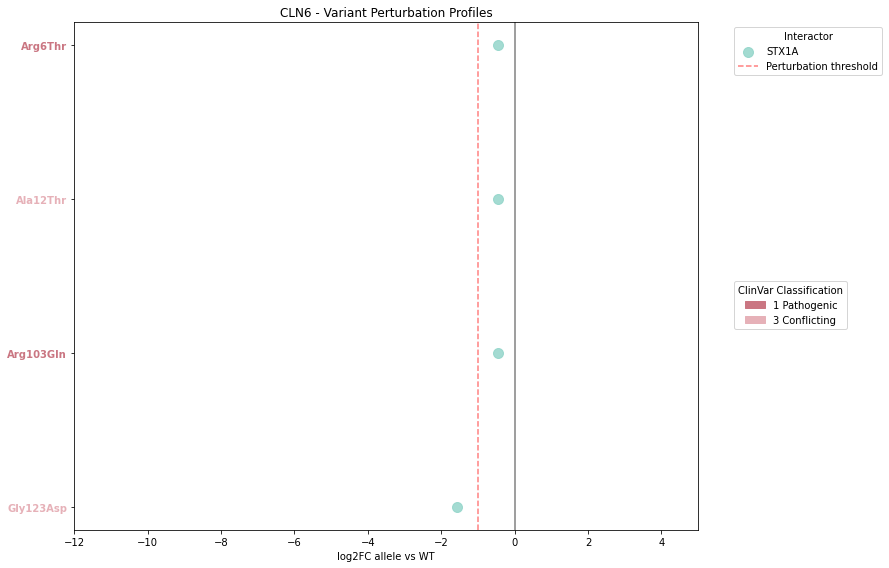


CLN6 summary:
  Number of variants: 4
  Number of interactors: 1
  Total interactions: 4


In [15]:
import matplotlib.pyplot as plt
import seaborn as sns
import re

# Create plots for the interesting genes
for gene in sorted(scores_pd.symbol.unique().tolist()):
    
    interest_gene = 'CLN6'
    
    if gene != interest_gene:
        continue

    gene_data = scores.filter(pl.col("symbol") == gene)
    
    if gene_data.shape[0] == 0:
        print(f"No data found for {gene}")
        continue
    
    # Convert to pandas for easier plotting
    gene_pd = gene_data.to_pandas()
    
    # Extract position numbers and sort variants
    def extract_position(aa_change):
        match = re.search(r'(\d+)', aa_change)
        return int(match.group(1)) if match else 0
    
    variants = gene_pd['aa_change'].unique()
    variants_sorted = sorted(variants, key=extract_position, reverse=True)
    interactors = gene_pd['ad_symbol'].unique()
    
    # Create the plot
    fig, ax = plt.subplots(figsize=(12, max(8, len(variants) * 0.5)))
    
    # Color palette for interactors
    colors = plt.cm.Set3(np.linspace(0, 1, len(interactors)))
    interactor_colors = dict(zip(interactors, colors))
    
    # Plot each variant (using sorted order)
    for i, variant in enumerate(variants_sorted):
        variant_data = gene_pd[gene_pd['aa_change'] == variant]
        
        for _, row in variant_data.iterrows():
            interactor = row['ad_symbol']
            log2fc = row['log2fc']
            
            ax.scatter(log2fc, i, 
                      color=interactor_colors[interactor], 
                      s=100, 
                      alpha=0.8,
                      label=interactor if i == 0 else "")
    
    # Add vertical lines
    ax.axvline(x=0, color='black', linestyle='-', alpha=0.5)
    ax.axvline(x=-1, color='red', linestyle='--', alpha=0.5, label='Perturbation threshold')
    
    # Customize plot with colored variant labels
    ax.set_yticks(range(len(variants_sorted)))
    
    # Color y-axis labels based on ClinVar classification
    colored_labels = []
    clinvar_categories_used = set()
    for variant in variants_sorted:
        # Get ClinVar classification for this variant
        variant_row = gene_pd[gene_pd['aa_change'] == variant].iloc[0]
        clinvar_category = variant_row.get('clinvar_clnsig_clean', None)
        label_color = palette_dict["clinvar_clnsig_clean"].get(clinvar_category, "black")
        colored_labels.append((variant, label_color))
        if clinvar_category:
            clinvar_categories_used.add(clinvar_category)
    
    ax.set_yticklabels([label for label, color in colored_labels])
    
    # Apply colors to y-tick labels
    for i, (label, color) in enumerate(colored_labels):
        ax.get_yticklabels()[i].set_color(color)
        ax.get_yticklabels()[i].set_fontweight('bold')
    
    ax.set_xlabel('log2FC allele vs WT')
    ax.set_title(f'{gene} - Variant Perturbation Profiles')
    ax.set_xlim(-12, 5)
    
    # Handle interactor legend
    handles, labels = ax.get_legend_handles_labels()
    by_label = dict(zip(labels, handles))
    interactor_legend = ax.legend(by_label.values(), by_label.keys(), 
                                 bbox_to_anchor=(1.05, 1), loc='upper left', 
                                 title='Interactor')
    
    # Add ClinVar color legend
    clinvar_patches = []
    for category in sorted(clinvar_categories_used):
        color = palette_dict["clinvar_clnsig_clean"].get(category, "black")
        # Clean up category name for display
        display_name = category.replace('clinvar_clnsig_', '').replace('_', ' ').title()
        clinvar_patches.append(Patch(color=color, label=display_name))
    
    if clinvar_patches:
        clinvar_legend = ax.legend(handles=clinvar_patches, 
                                  bbox_to_anchor=(1.05, 0.5), loc='upper left',
                                  title='ClinVar Classification')
        
        # Add the interactor legend back (matplotlib removes it when adding new legend)
        ax.add_artist(interactor_legend)
    
    plt.tight_layout()
    plt.show()
    
    print(f"\n{gene} summary:")
    print(f"  Number of variants: {len(variants_sorted)}")
    print(f"  Number of interactors: {len(interactors)}")
    print(f"  Total interactions: {gene_pd.shape[0]}")

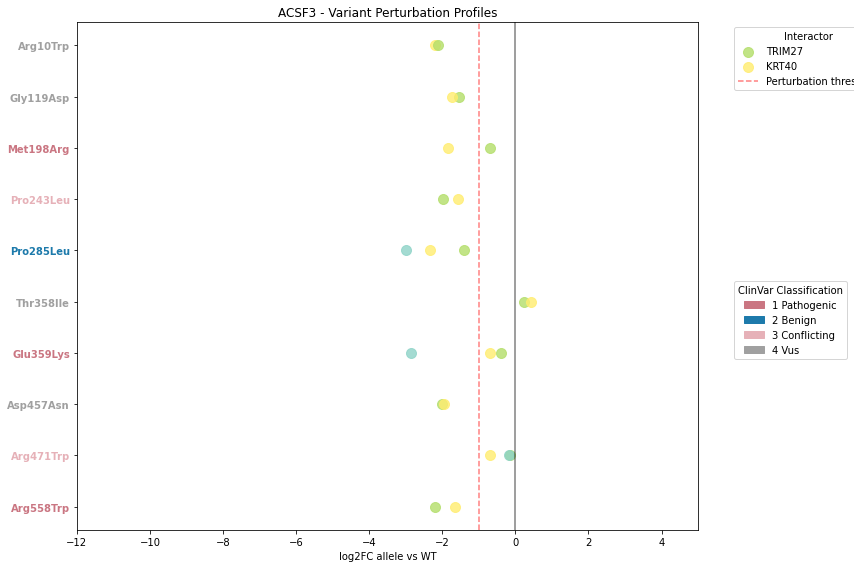


ACSF3 summary:
  Number of variants: 10
  Number of interactors: 3
  Total interactions: 23


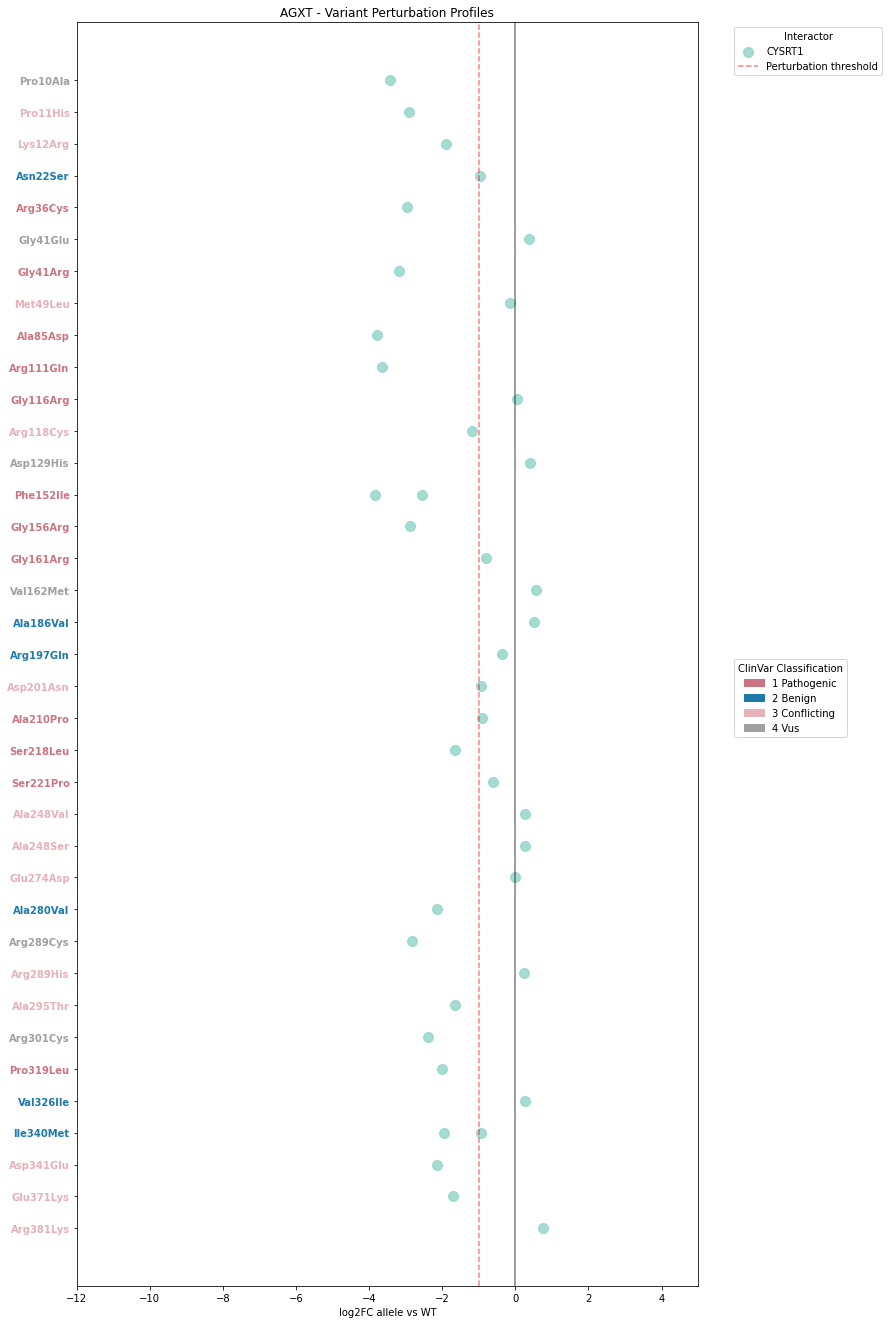


AGXT summary:
  Number of variants: 37
  Number of interactors: 1
  Total interactions: 39


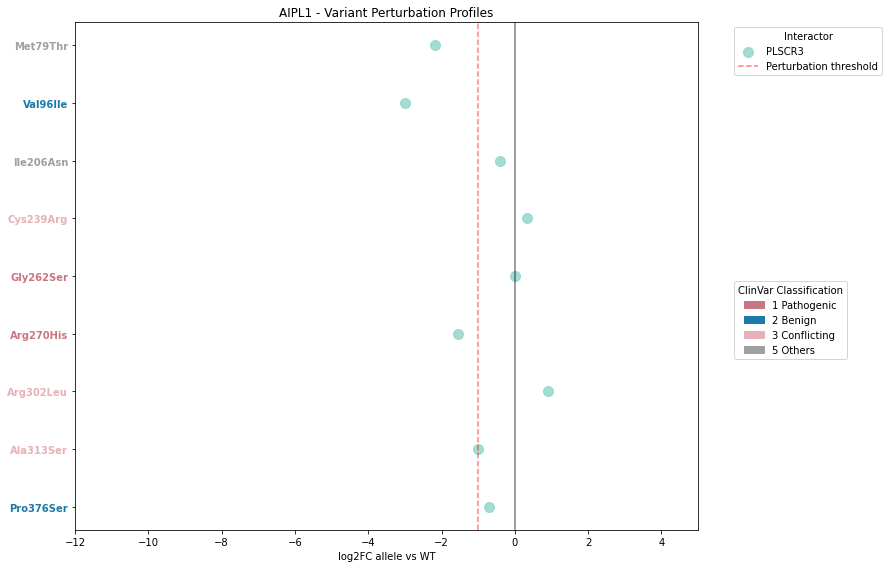


AIPL1 summary:
  Number of variants: 9
  Number of interactors: 1
  Total interactions: 9


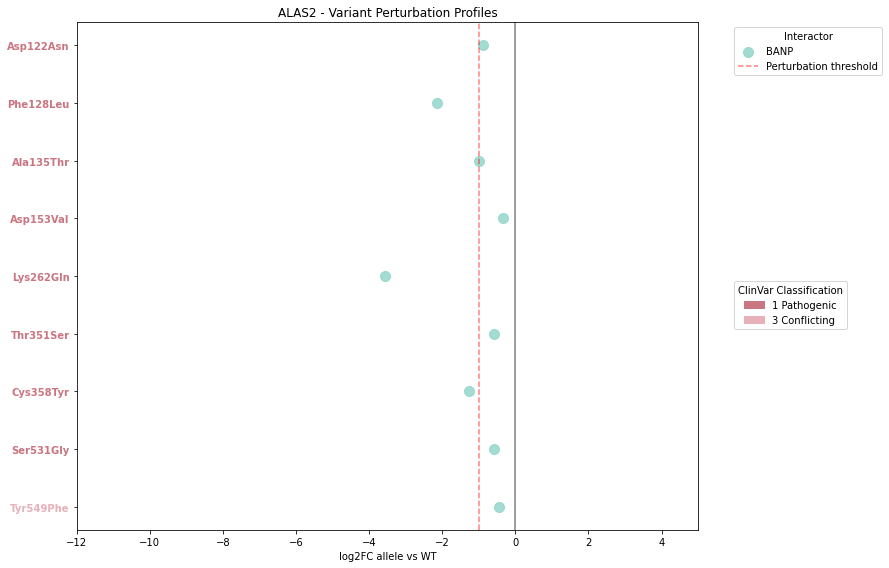


ALAS2 summary:
  Number of variants: 9
  Number of interactors: 1
  Total interactions: 9


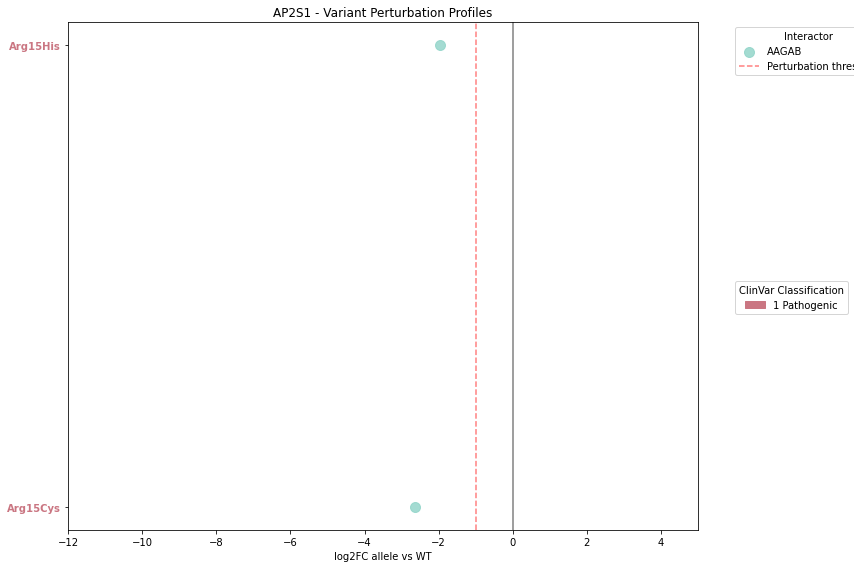


AP2S1 summary:
  Number of variants: 2
  Number of interactors: 1
  Total interactions: 2


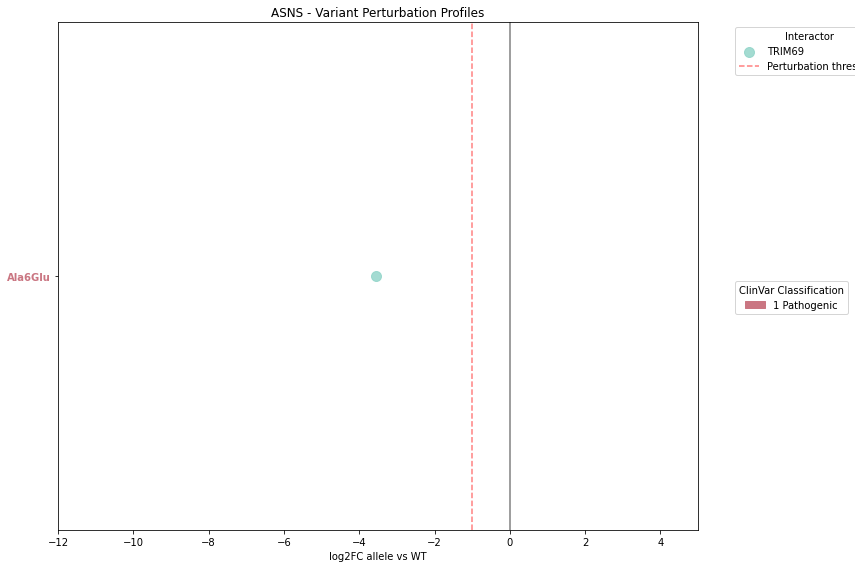


ASNS summary:
  Number of variants: 1
  Number of interactors: 1
  Total interactions: 1


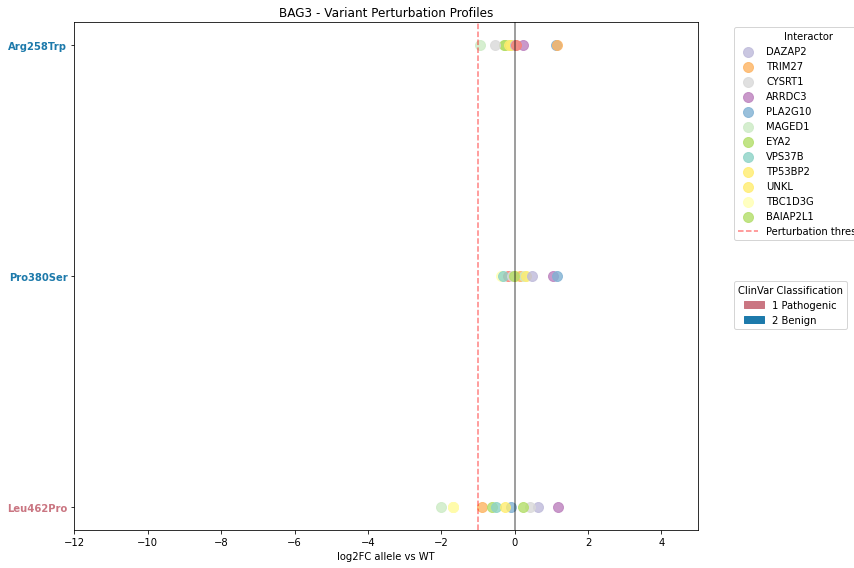


BAG3 summary:
  Number of variants: 3
  Number of interactors: 13
  Total interactions: 37


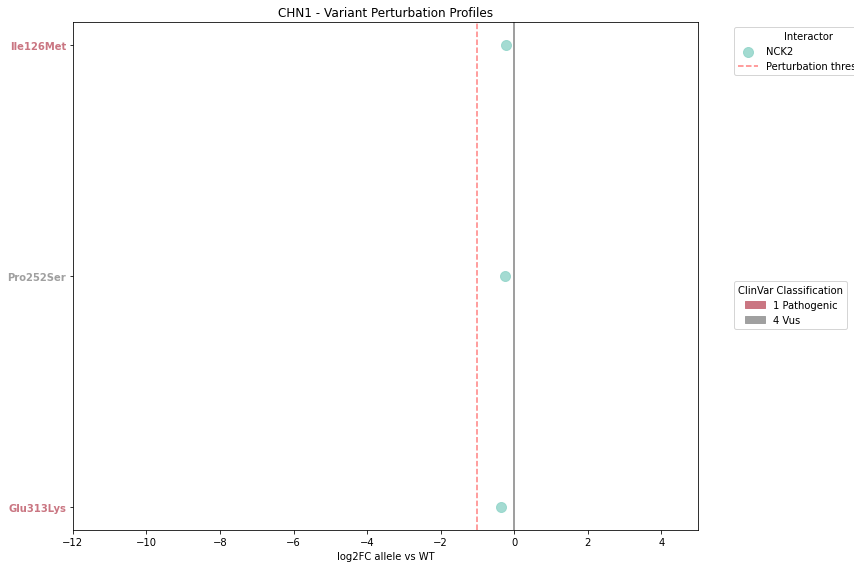


CHN1 summary:
  Number of variants: 3
  Number of interactors: 1
  Total interactions: 3


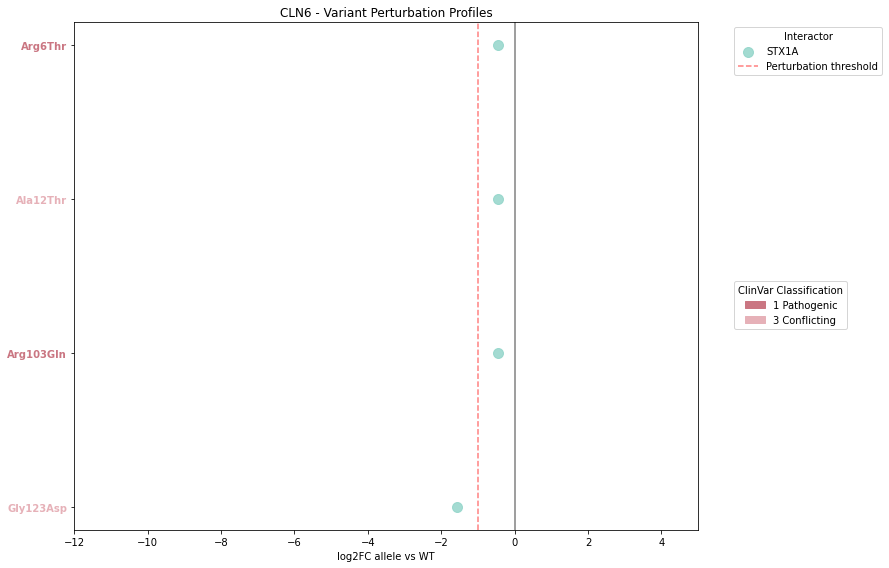


CLN6 summary:
  Number of variants: 4
  Number of interactors: 1
  Total interactions: 4


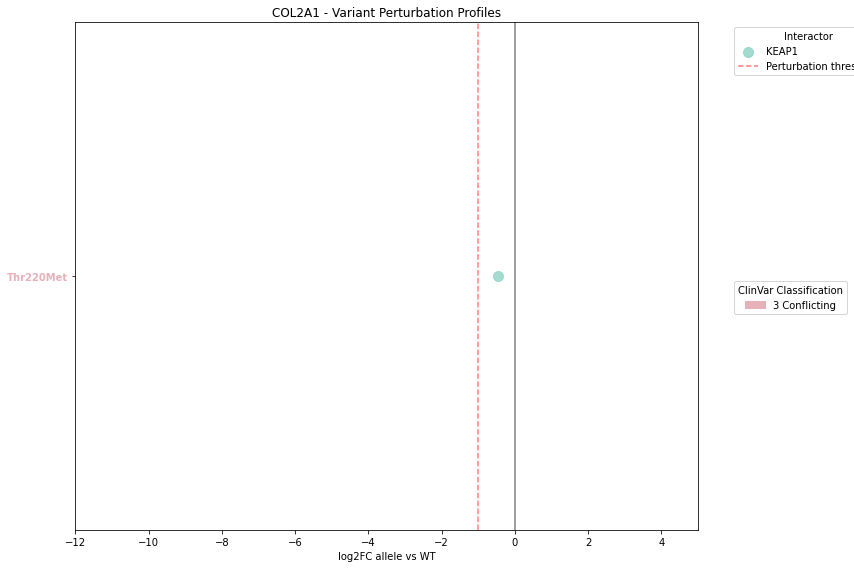


COL2A1 summary:
  Number of variants: 1
  Number of interactors: 1
  Total interactions: 1


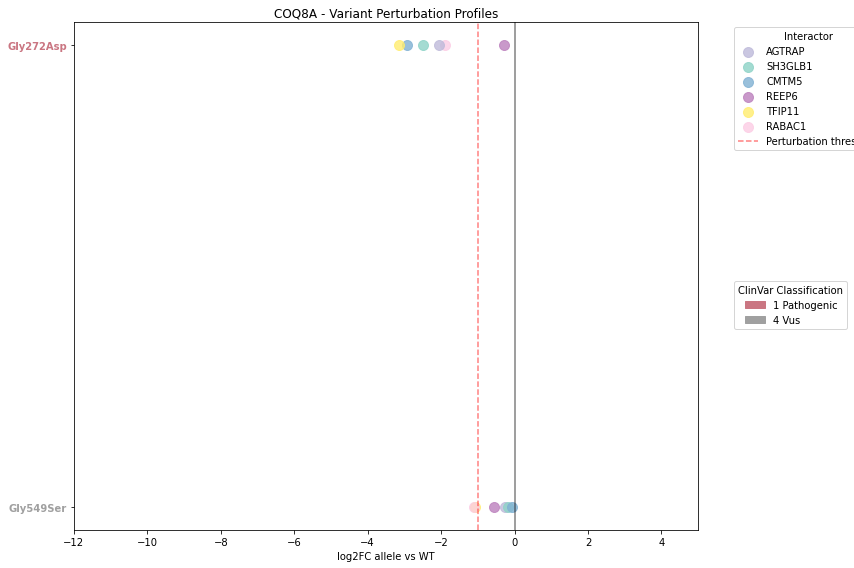


COQ8A summary:
  Number of variants: 2
  Number of interactors: 6
  Total interactions: 12


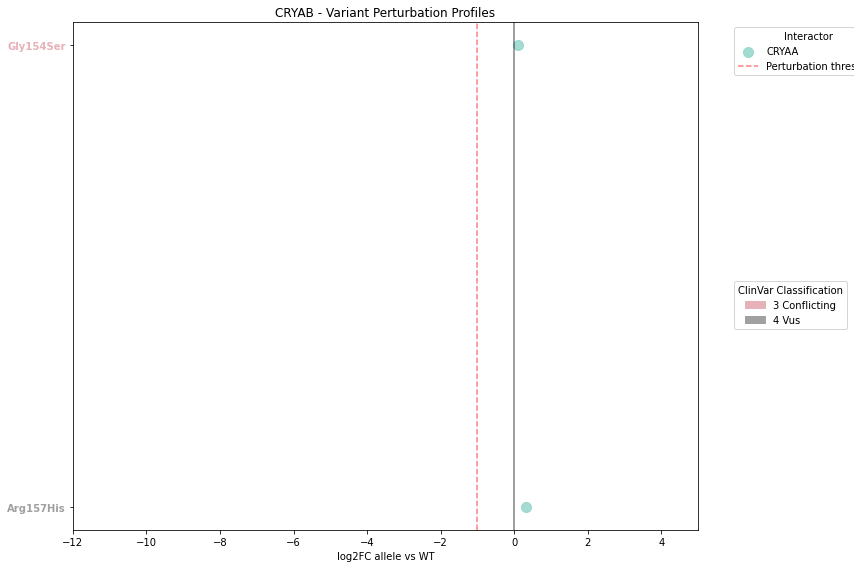


CRYAB summary:
  Number of variants: 2
  Number of interactors: 1
  Total interactions: 2


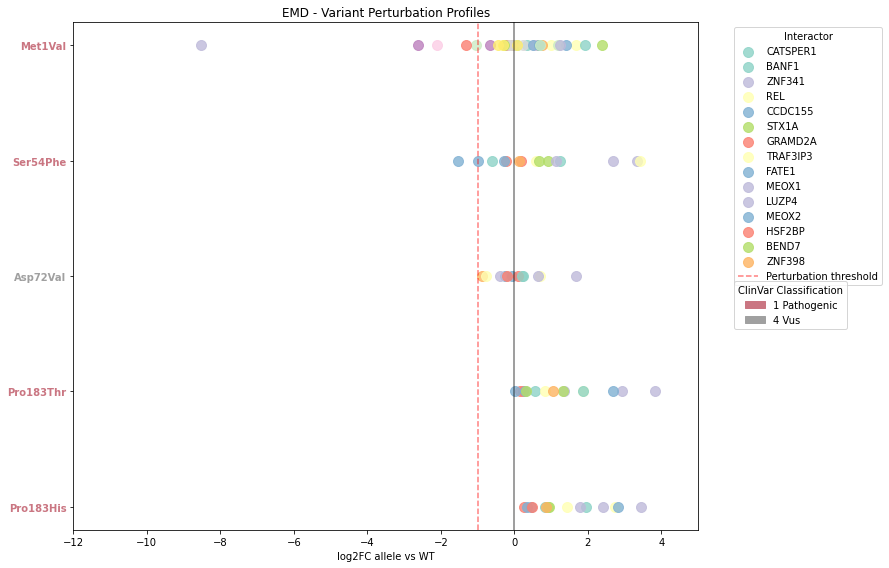


EMD summary:
  Number of variants: 5
  Number of interactors: 31
  Total interactions: 88


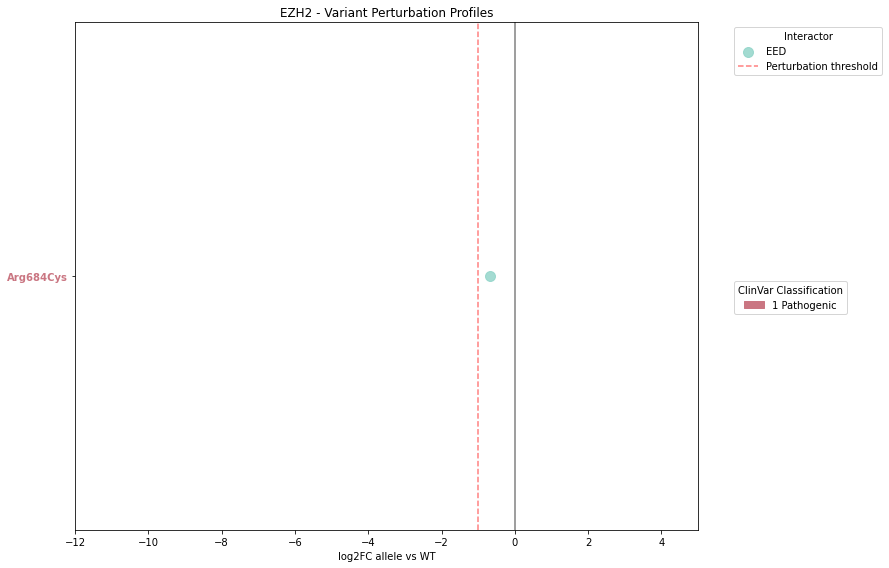


EZH2 summary:
  Number of variants: 1
  Number of interactors: 1
  Total interactions: 1


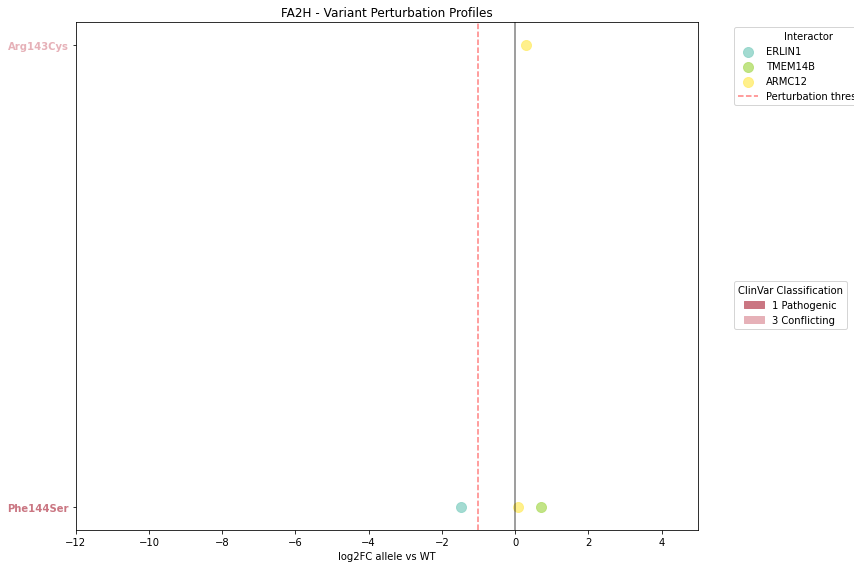


FA2H summary:
  Number of variants: 2
  Number of interactors: 3
  Total interactions: 4


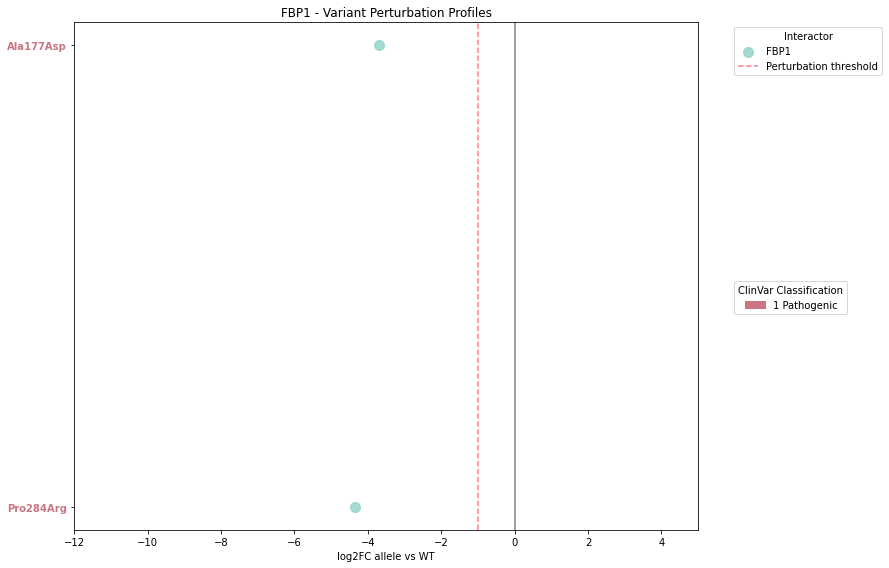


FBP1 summary:
  Number of variants: 2
  Number of interactors: 1
  Total interactions: 2


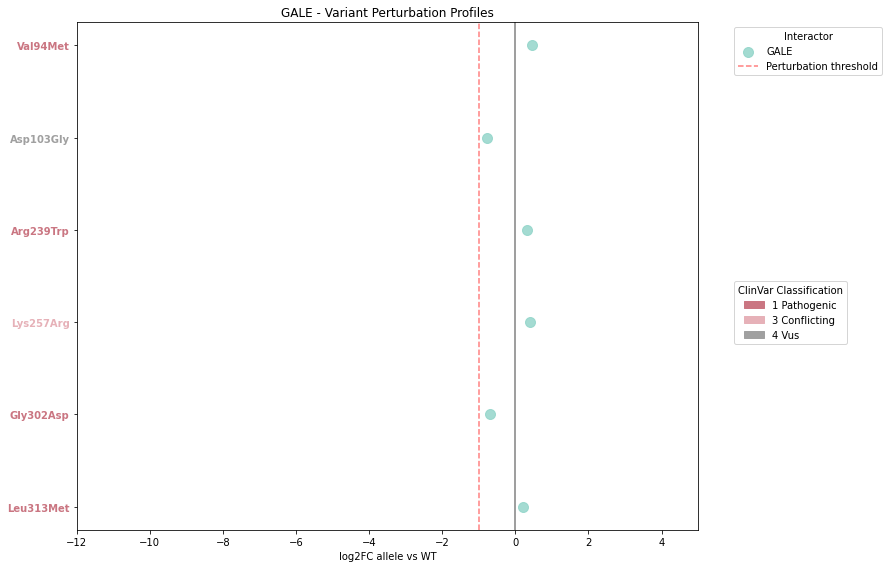


GALE summary:
  Number of variants: 6
  Number of interactors: 1
  Total interactions: 6


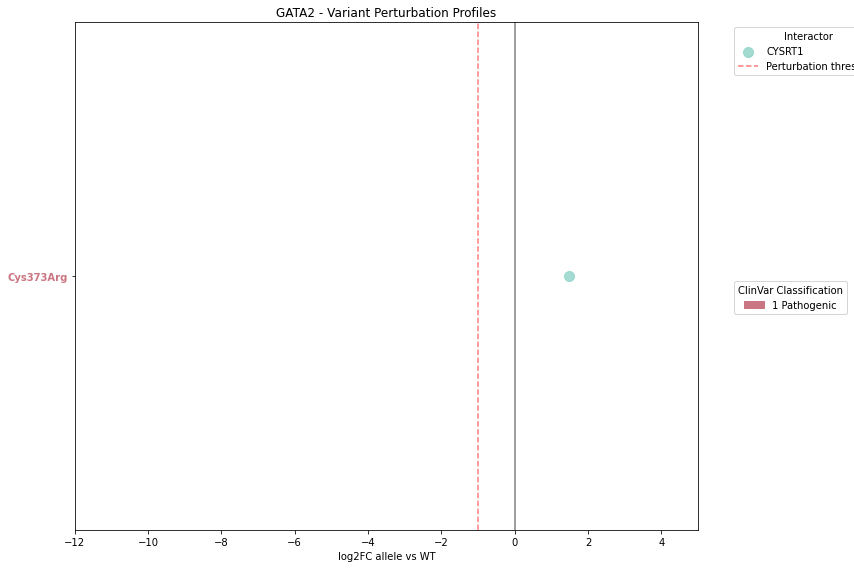


GATA2 summary:
  Number of variants: 1
  Number of interactors: 1
  Total interactions: 1


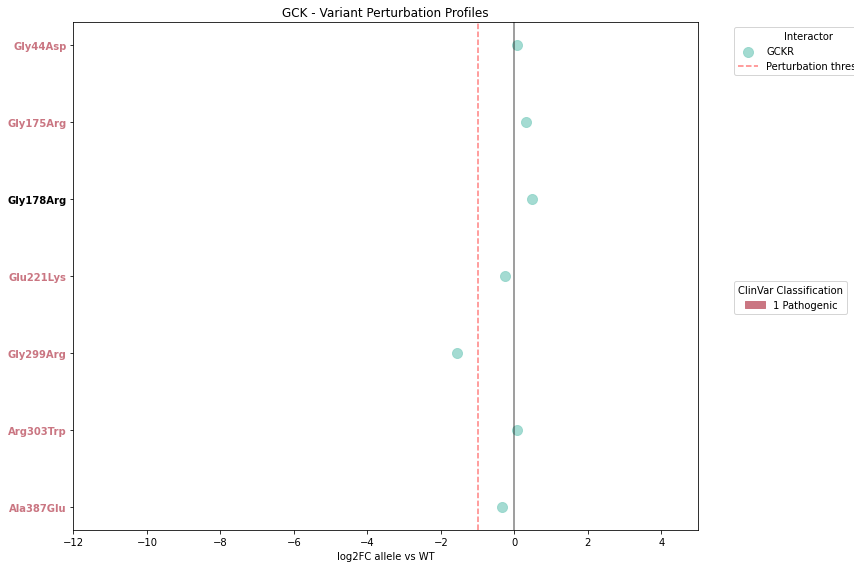


GCK summary:
  Number of variants: 7
  Number of interactors: 1
  Total interactions: 7


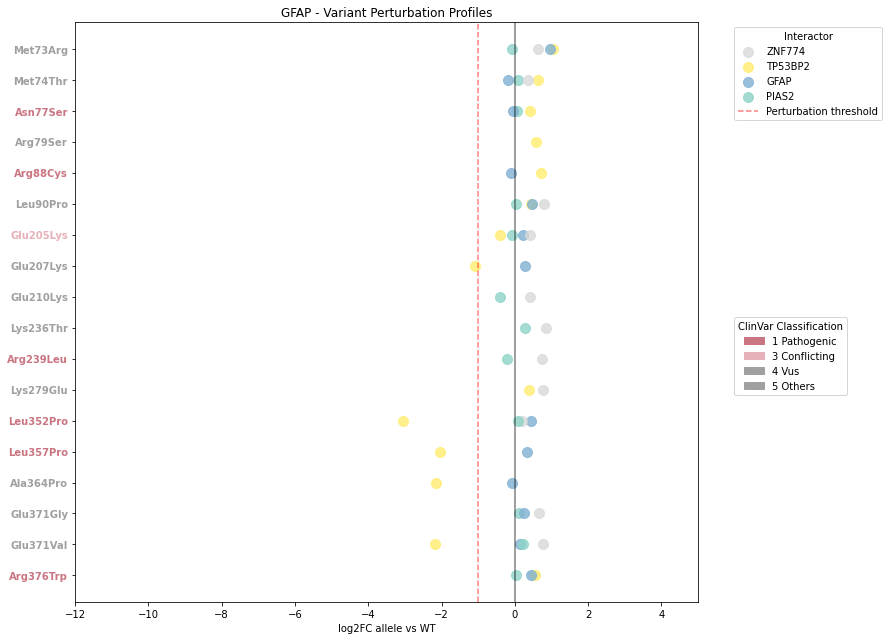


GFAP summary:
  Number of variants: 18
  Number of interactors: 4
  Total interactions: 51


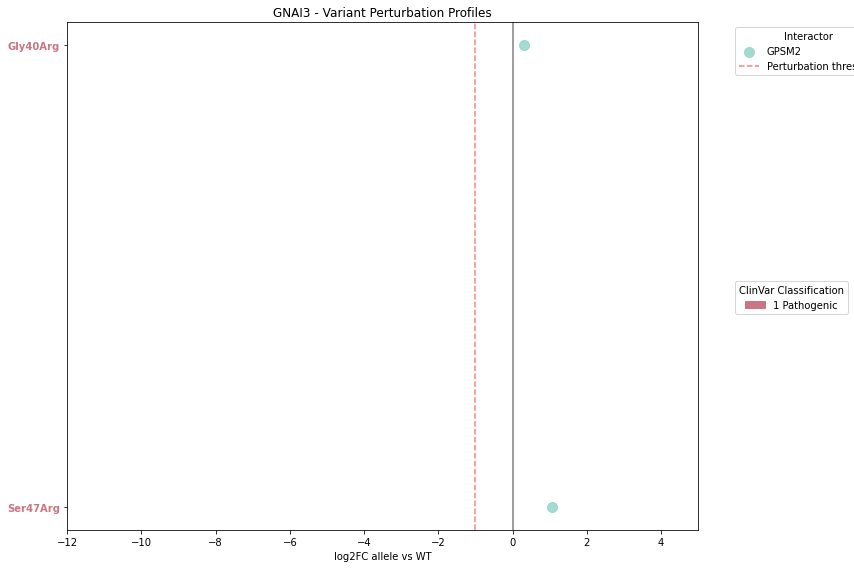


GNAI3 summary:
  Number of variants: 2
  Number of interactors: 1
  Total interactions: 2


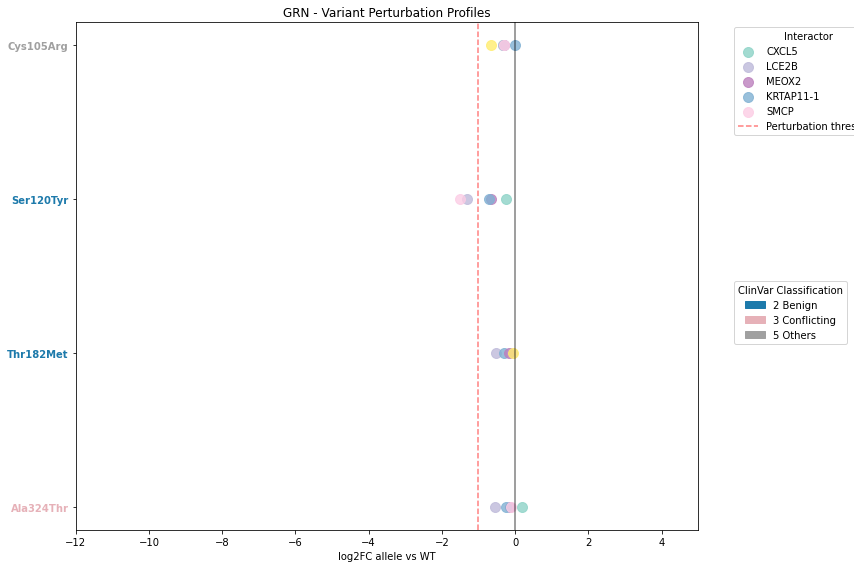


GRN summary:
  Number of variants: 4
  Number of interactors: 6
  Total interactions: 22


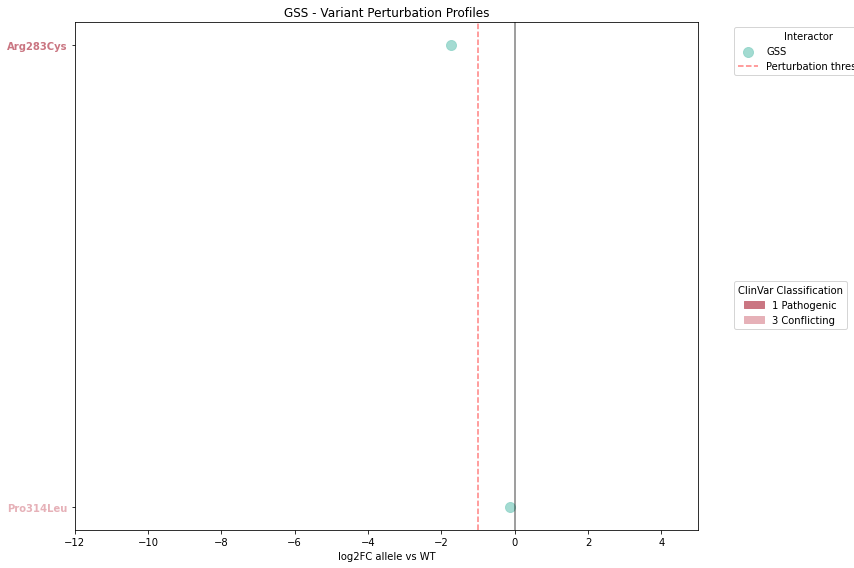


GSS summary:
  Number of variants: 2
  Number of interactors: 1
  Total interactions: 2


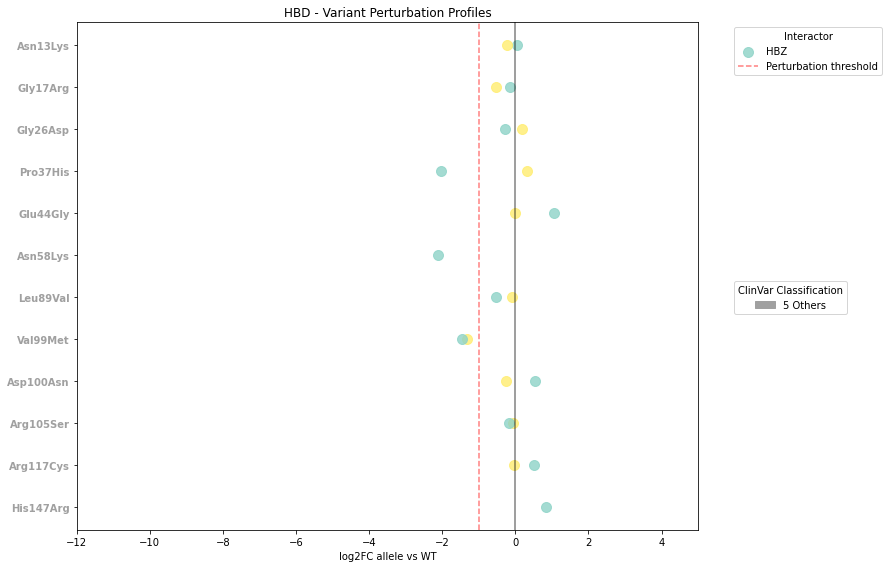


HBD summary:
  Number of variants: 12
  Number of interactors: 2
  Total interactions: 22


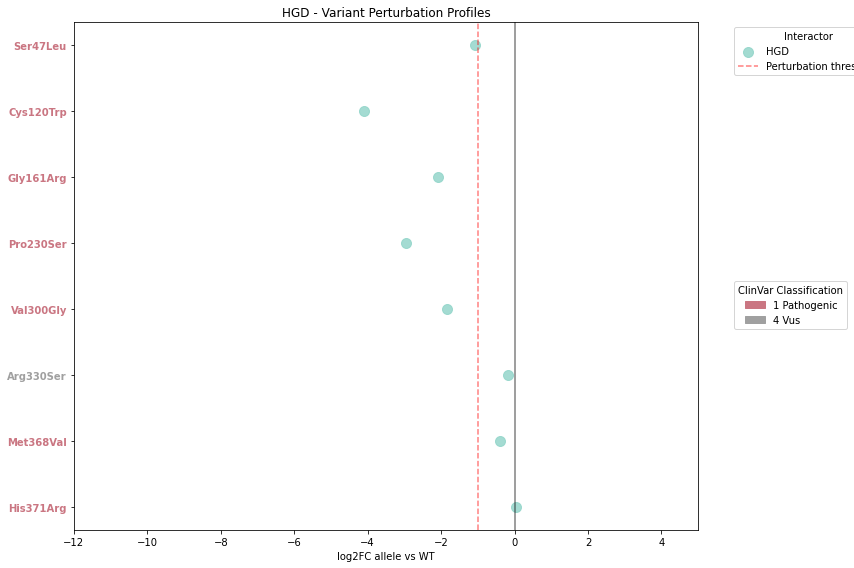


HGD summary:
  Number of variants: 8
  Number of interactors: 1
  Total interactions: 8


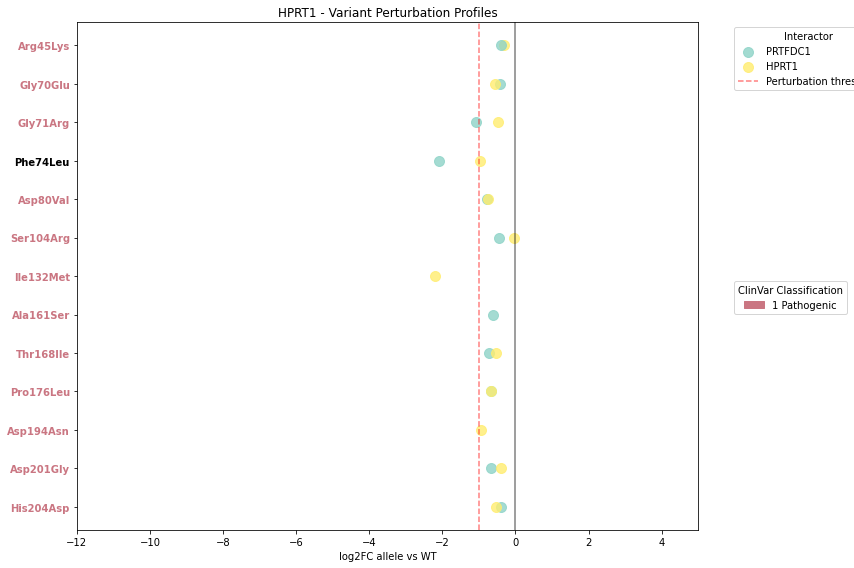


HPRT1 summary:
  Number of variants: 13
  Number of interactors: 2
  Total interactions: 24


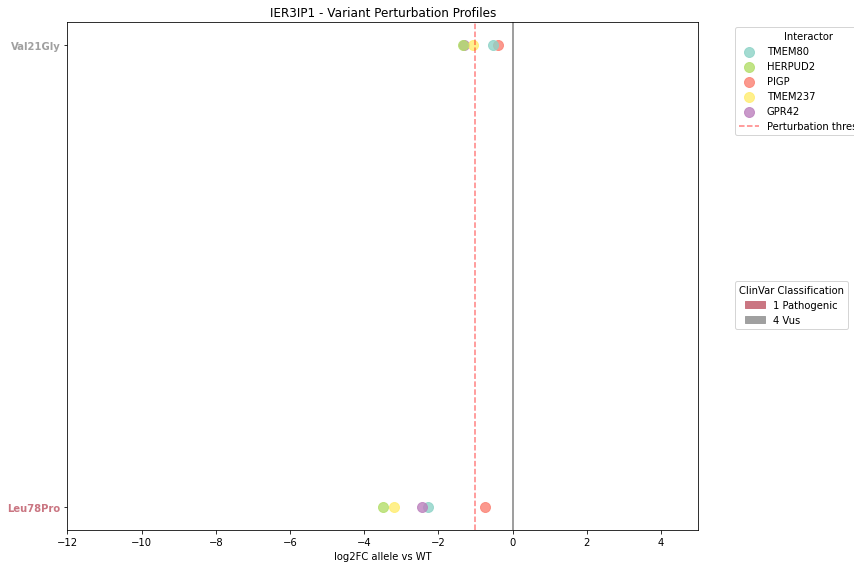


IER3IP1 summary:
  Number of variants: 2
  Number of interactors: 5
  Total interactions: 10


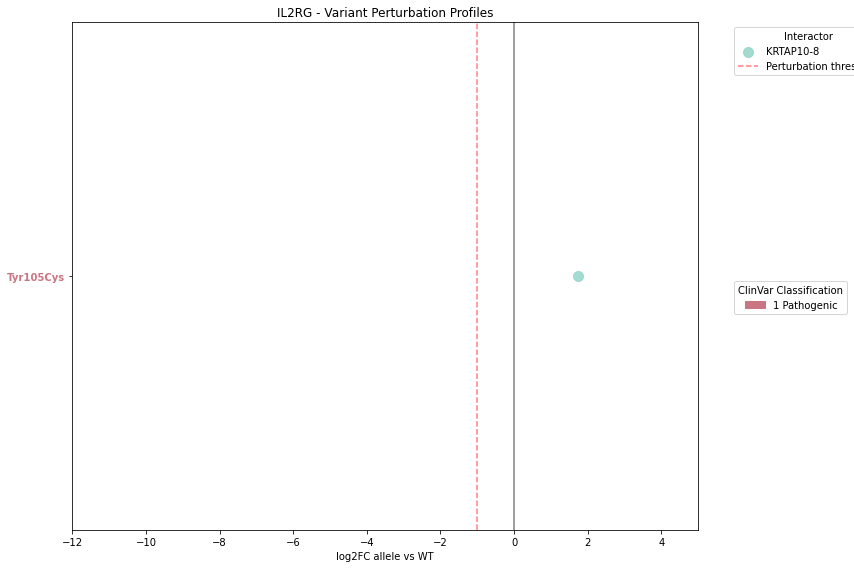


IL2RG summary:
  Number of variants: 1
  Number of interactors: 1
  Total interactions: 1


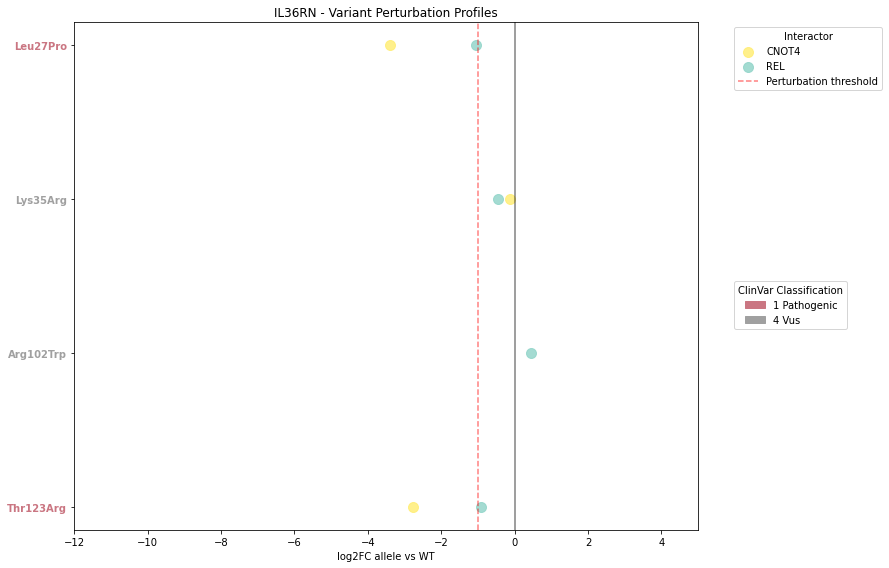


IL36RN summary:
  Number of variants: 4
  Number of interactors: 2
  Total interactions: 7


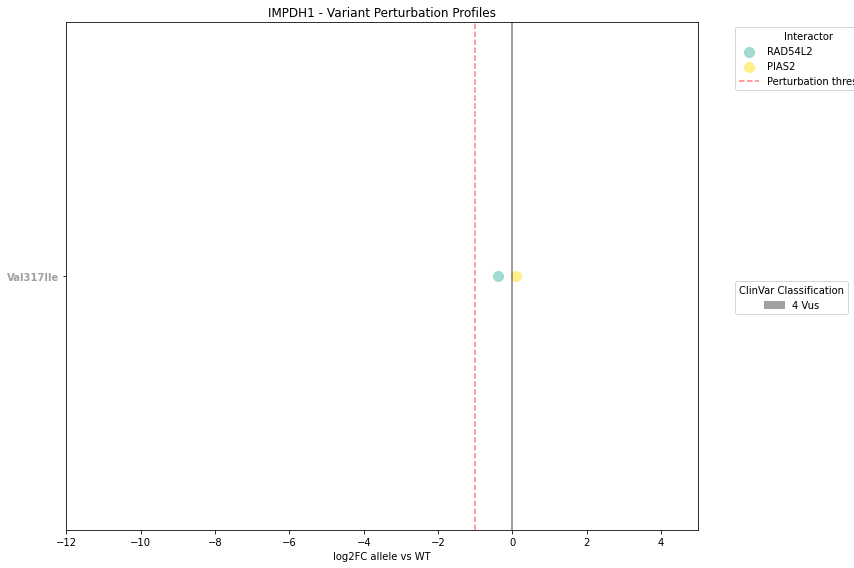


IMPDH1 summary:
  Number of variants: 1
  Number of interactors: 2
  Total interactions: 2


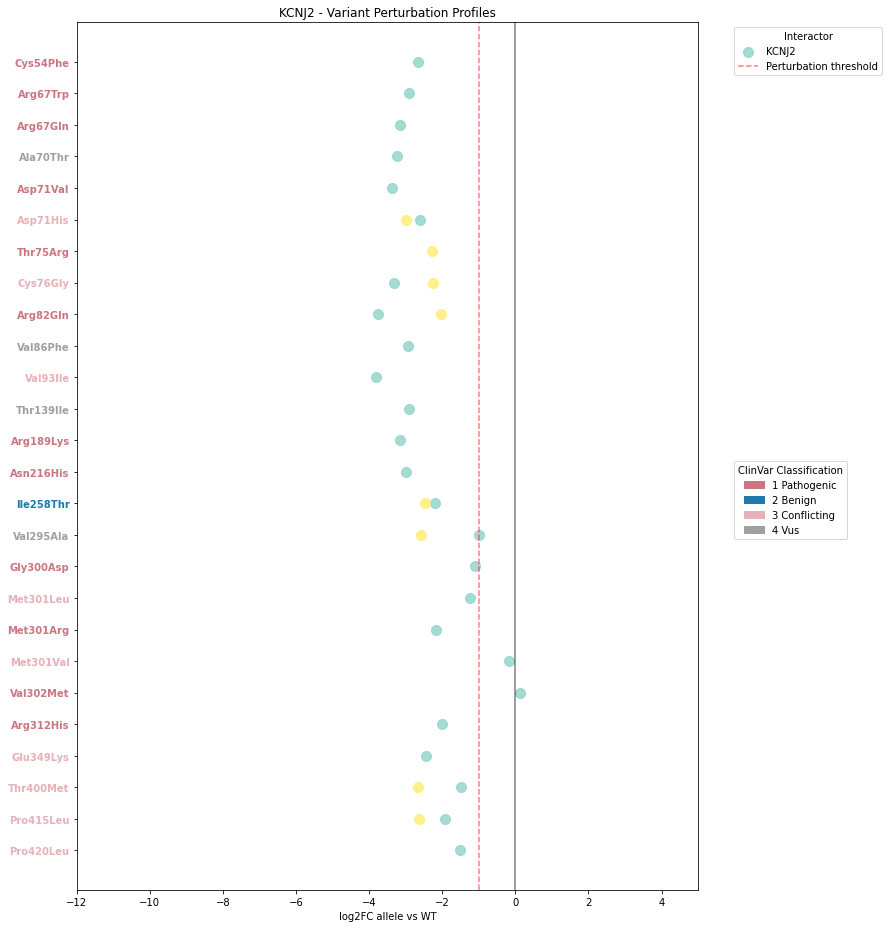


KCNJ2 summary:
  Number of variants: 26
  Number of interactors: 2
  Total interactions: 33


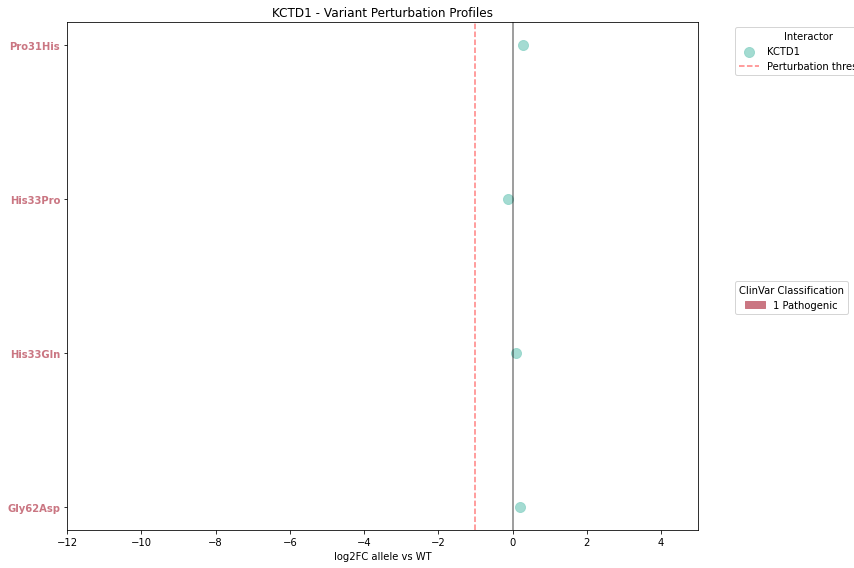


KCTD1 summary:
  Number of variants: 4
  Number of interactors: 1
  Total interactions: 4


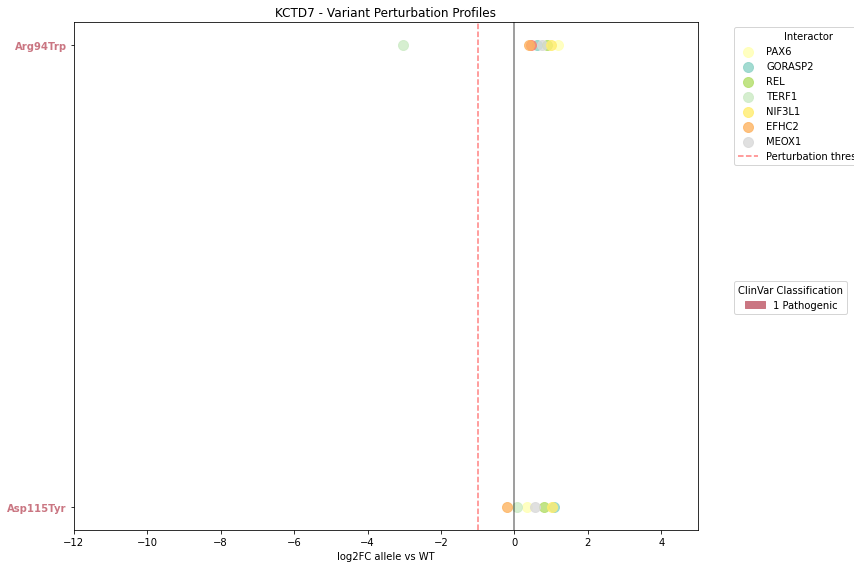


KCTD7 summary:
  Number of variants: 2
  Number of interactors: 8
  Total interactions: 15


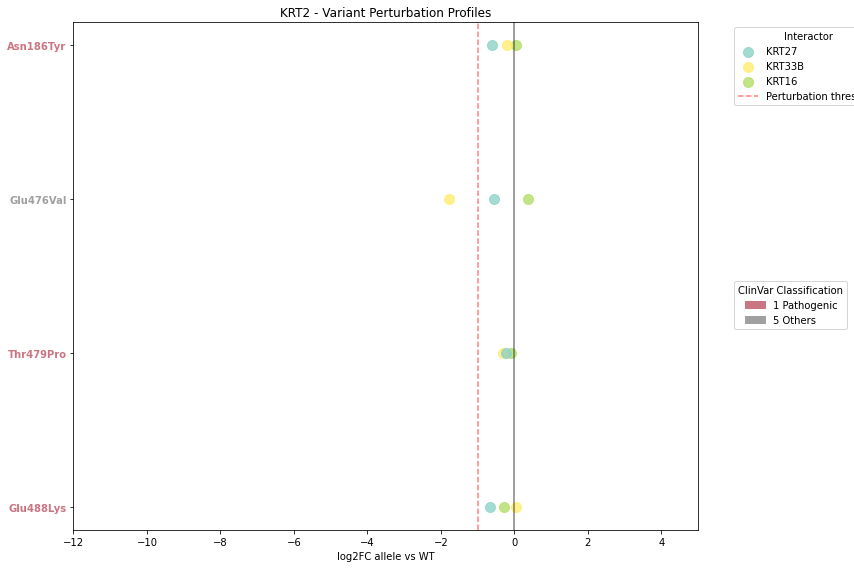


KRT2 summary:
  Number of variants: 4
  Number of interactors: 3
  Total interactions: 12


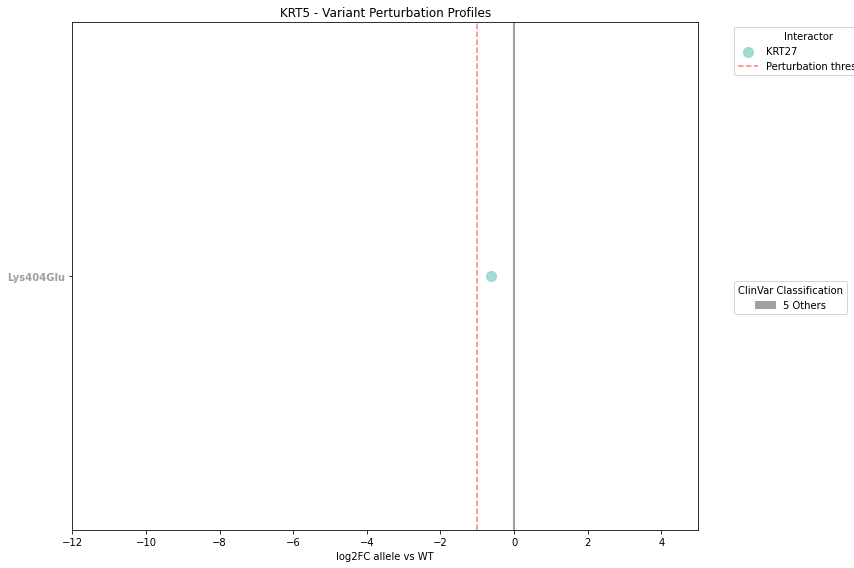


KRT5 summary:
  Number of variants: 1
  Number of interactors: 1
  Total interactions: 1


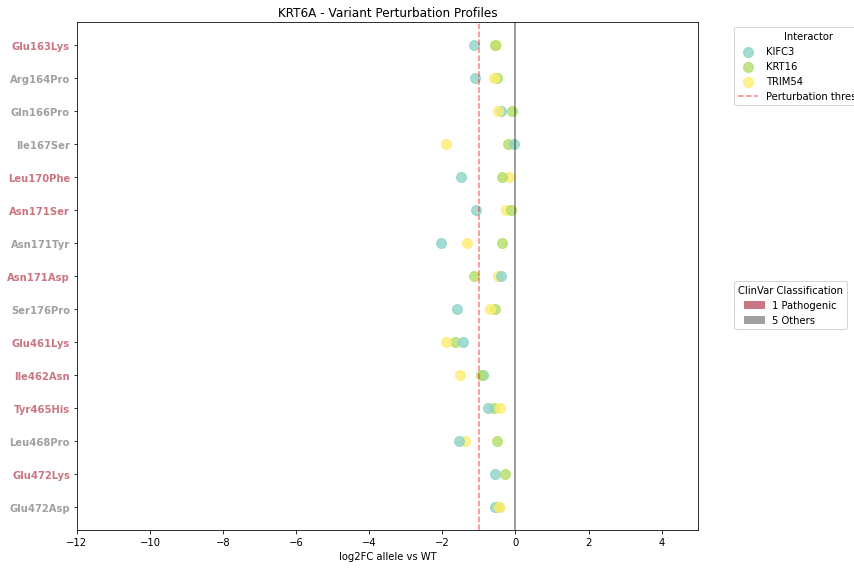


KRT6A summary:
  Number of variants: 15
  Number of interactors: 3
  Total interactions: 44


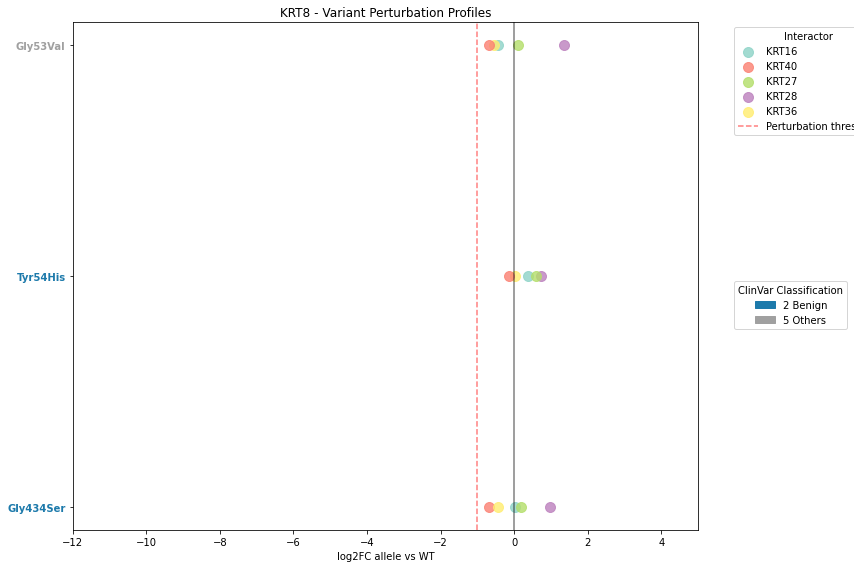


KRT8 summary:
  Number of variants: 3
  Number of interactors: 5
  Total interactions: 15


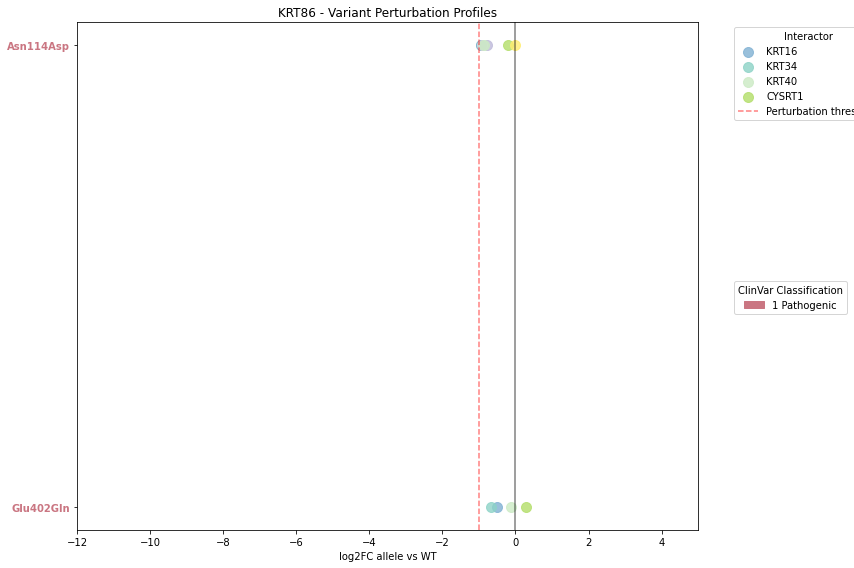


KRT86 summary:
  Number of variants: 2
  Number of interactors: 7
  Total interactions: 11


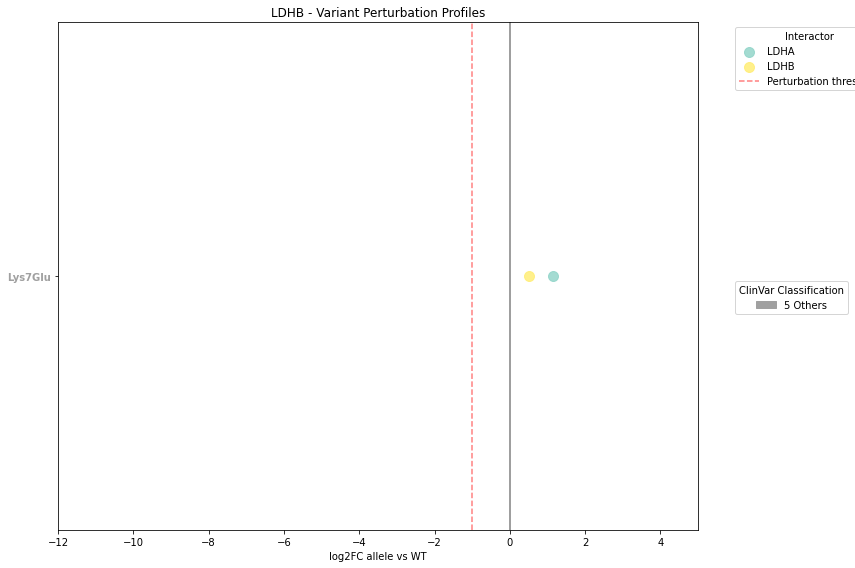


LDHB summary:
  Number of variants: 1
  Number of interactors: 2
  Total interactions: 2


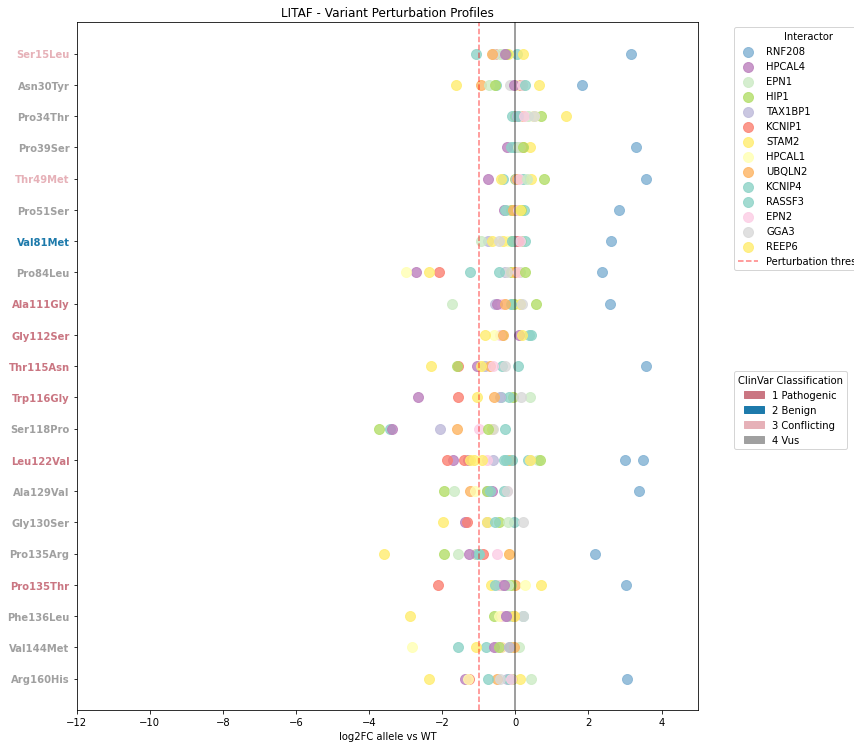


LITAF summary:
  Number of variants: 21
  Number of interactors: 15
  Total interactions: 276


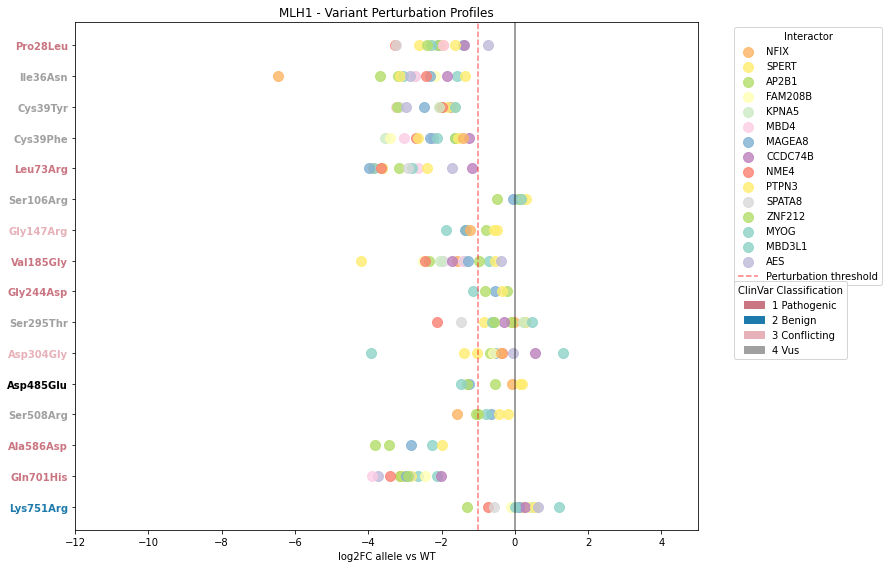


MLH1 summary:
  Number of variants: 16
  Number of interactors: 15
  Total interactions: 174


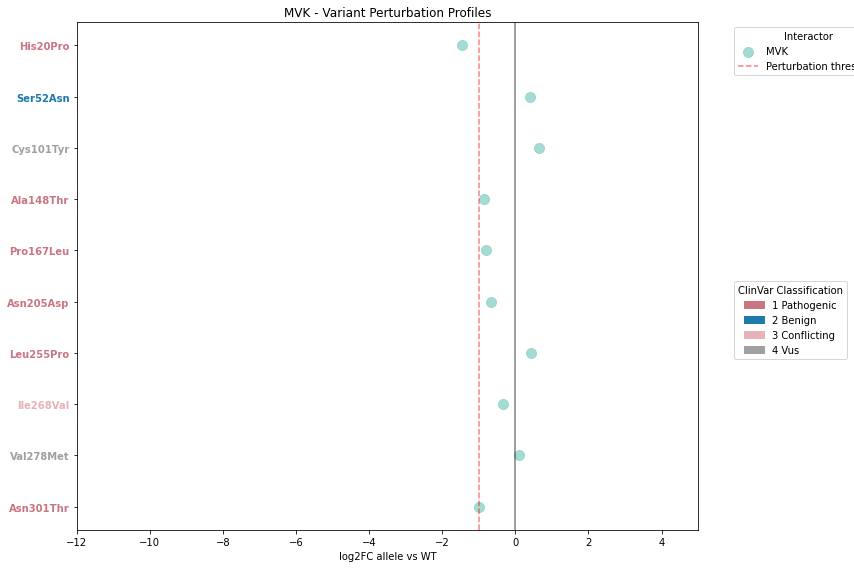


MVK summary:
  Number of variants: 10
  Number of interactors: 1
  Total interactions: 10


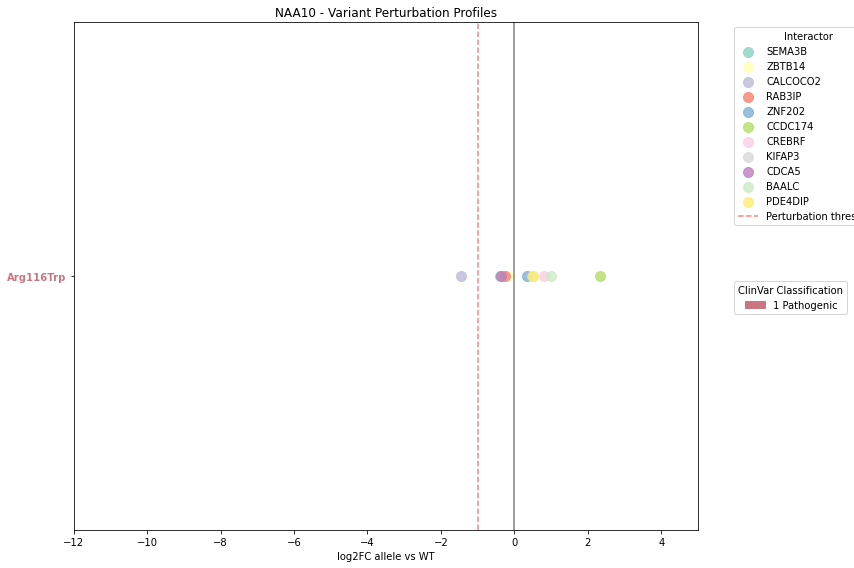


NAA10 summary:
  Number of variants: 1
  Number of interactors: 11
  Total interactions: 11


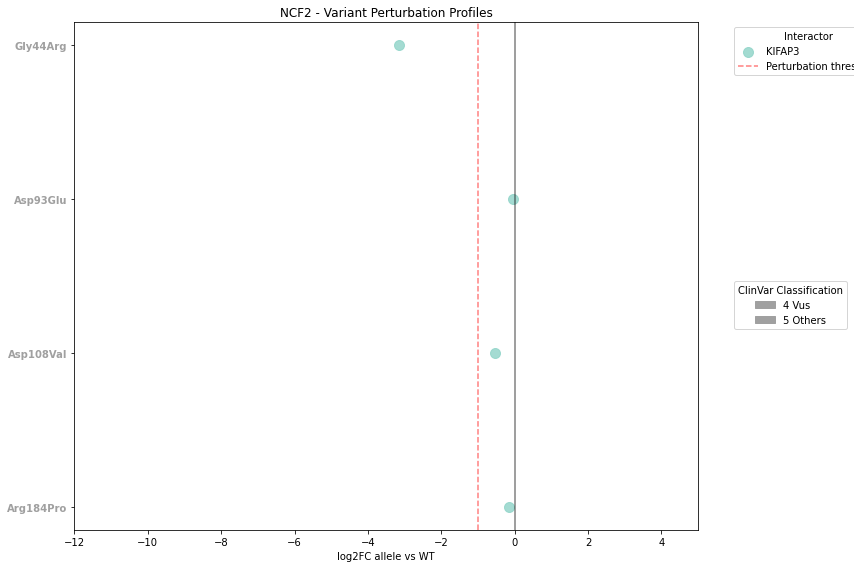


NCF2 summary:
  Number of variants: 4
  Number of interactors: 1
  Total interactions: 4


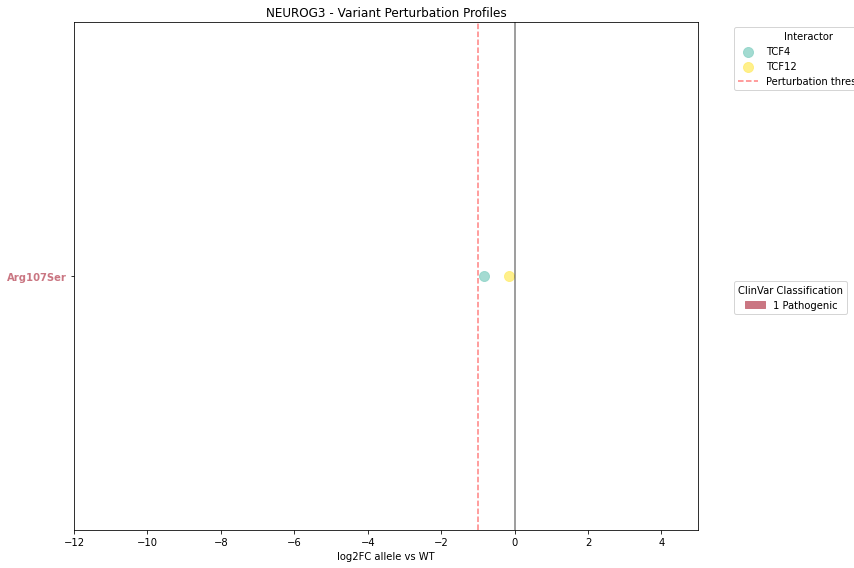


NEUROG3 summary:
  Number of variants: 1
  Number of interactors: 2
  Total interactions: 2


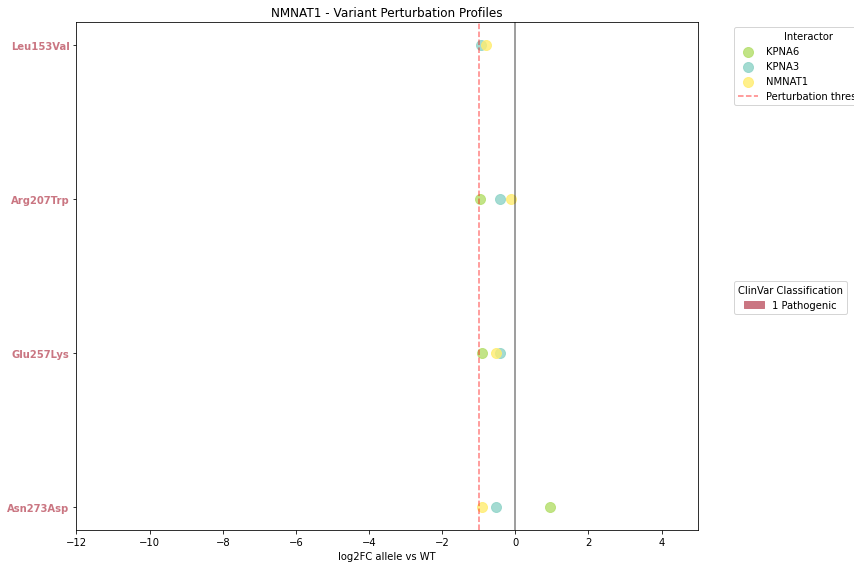


NMNAT1 summary:
  Number of variants: 4
  Number of interactors: 3
  Total interactions: 11


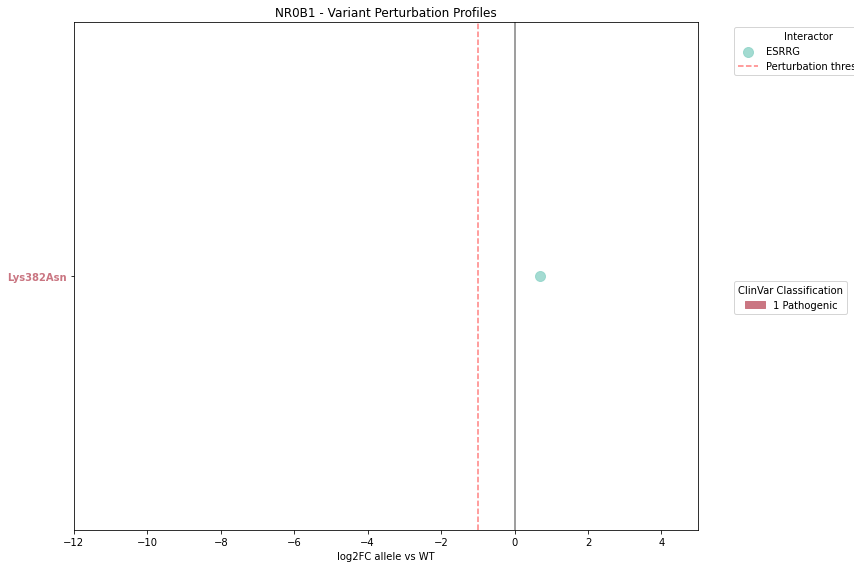


NR0B1 summary:
  Number of variants: 1
  Number of interactors: 1
  Total interactions: 1


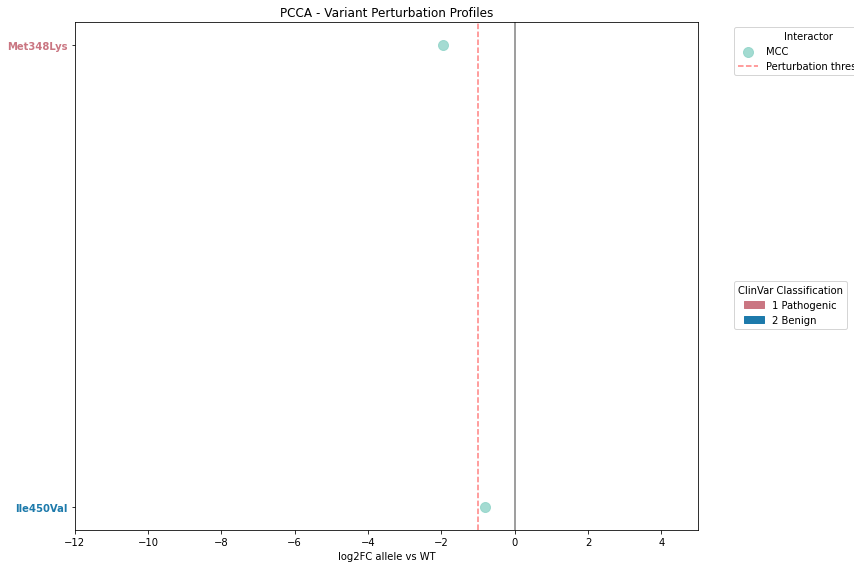


PCCA summary:
  Number of variants: 2
  Number of interactors: 1
  Total interactions: 2


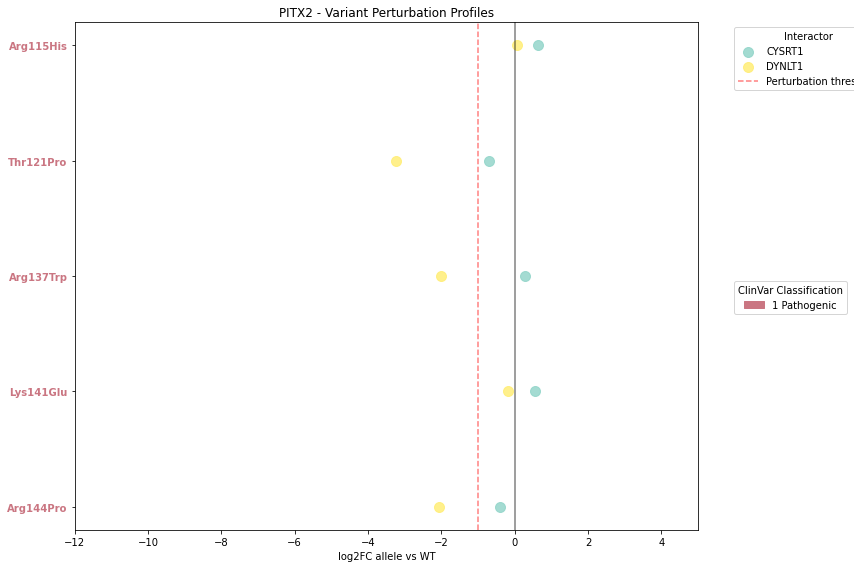


PITX2 summary:
  Number of variants: 5
  Number of interactors: 2
  Total interactions: 10


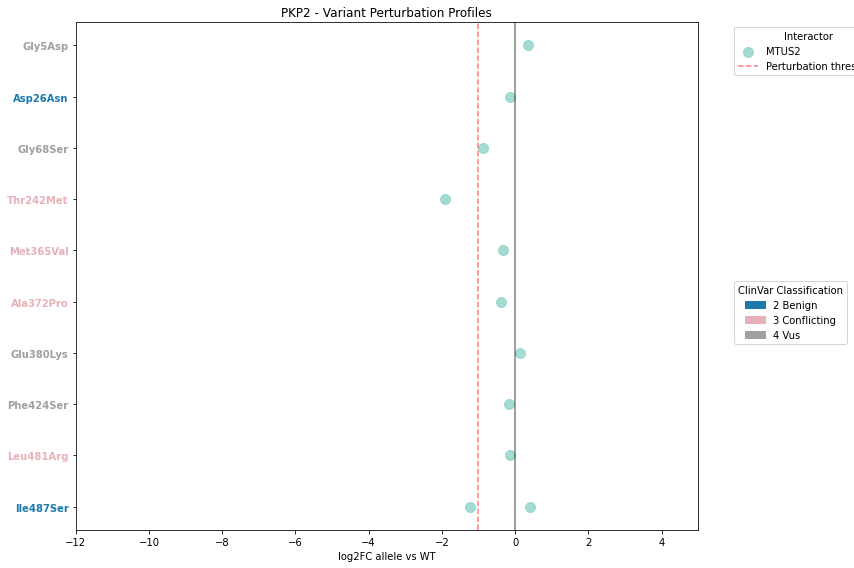


PKP2 summary:
  Number of variants: 10
  Number of interactors: 1
  Total interactions: 11


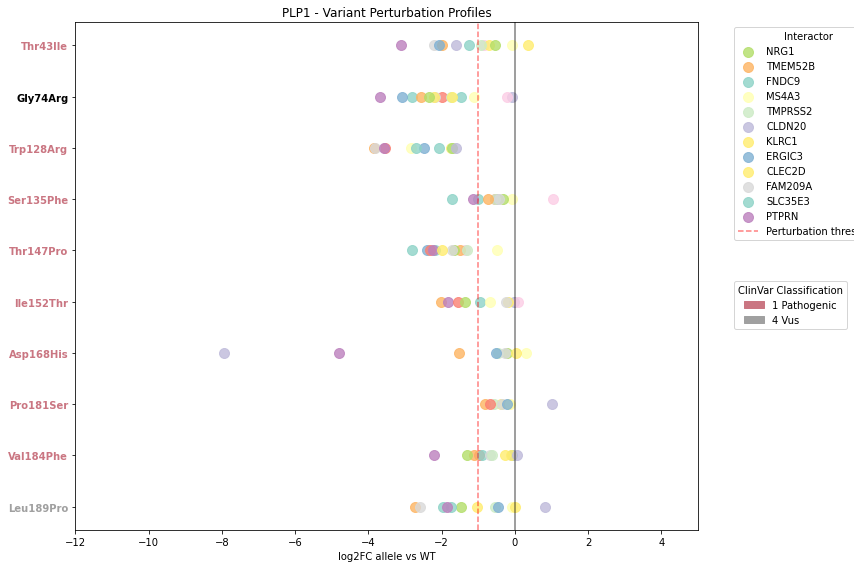


PLP1 summary:
  Number of variants: 10
  Number of interactors: 14
  Total interactions: 112


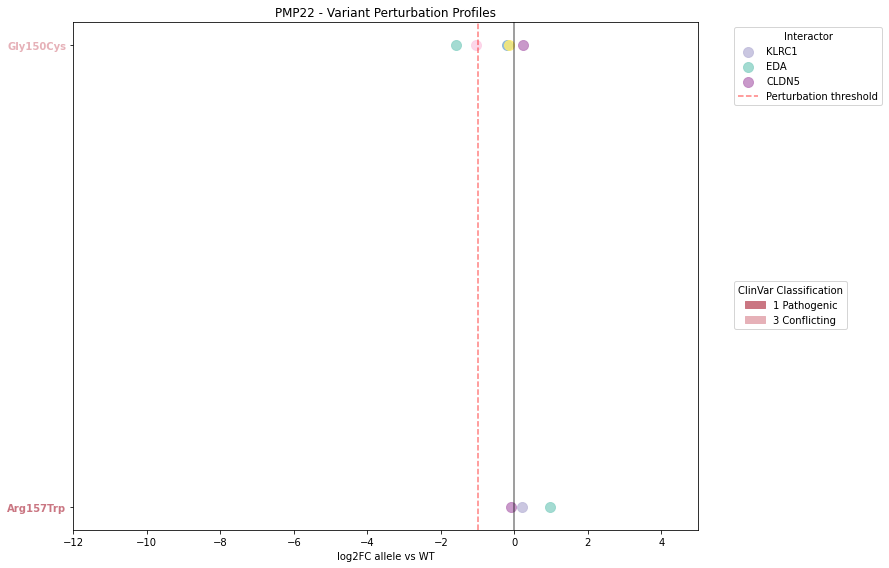


PMP22 summary:
  Number of variants: 2
  Number of interactors: 6
  Total interactions: 8


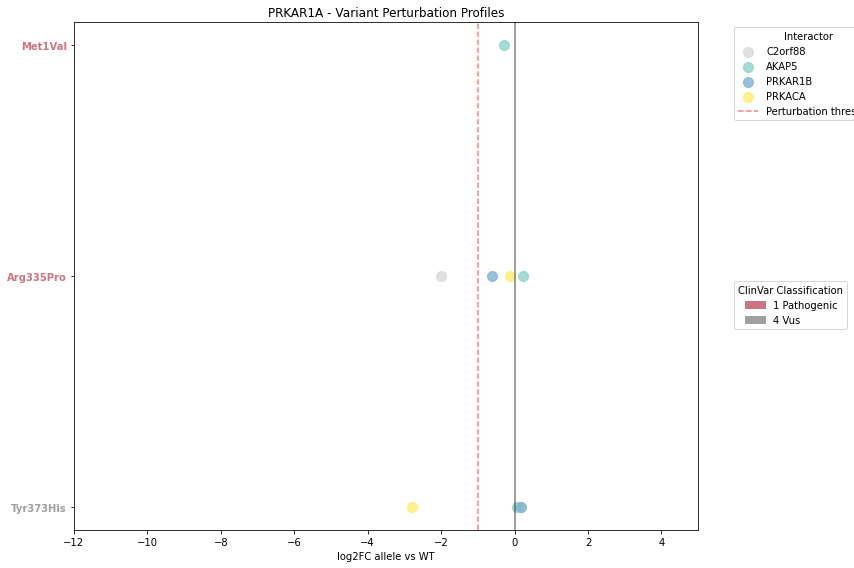


PRKAR1A summary:
  Number of variants: 3
  Number of interactors: 4
  Total interactions: 9


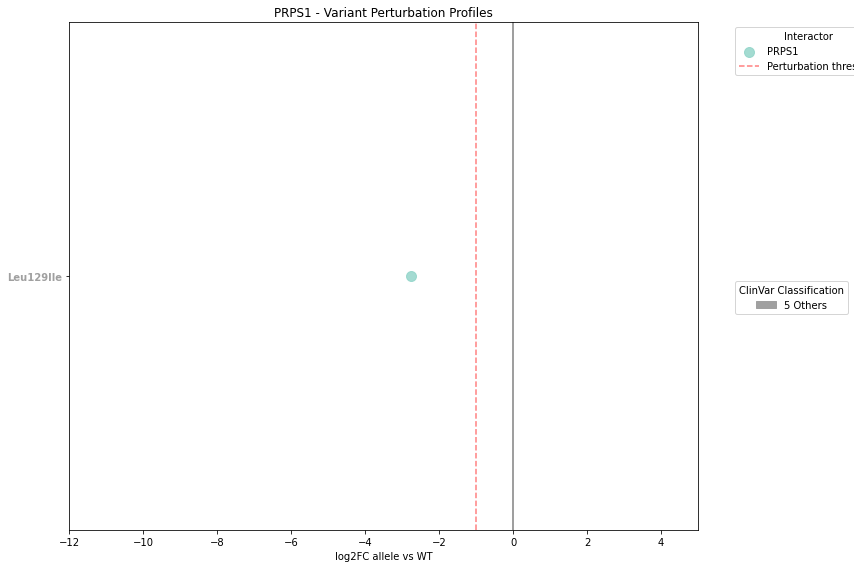


PRPS1 summary:
  Number of variants: 1
  Number of interactors: 1
  Total interactions: 1


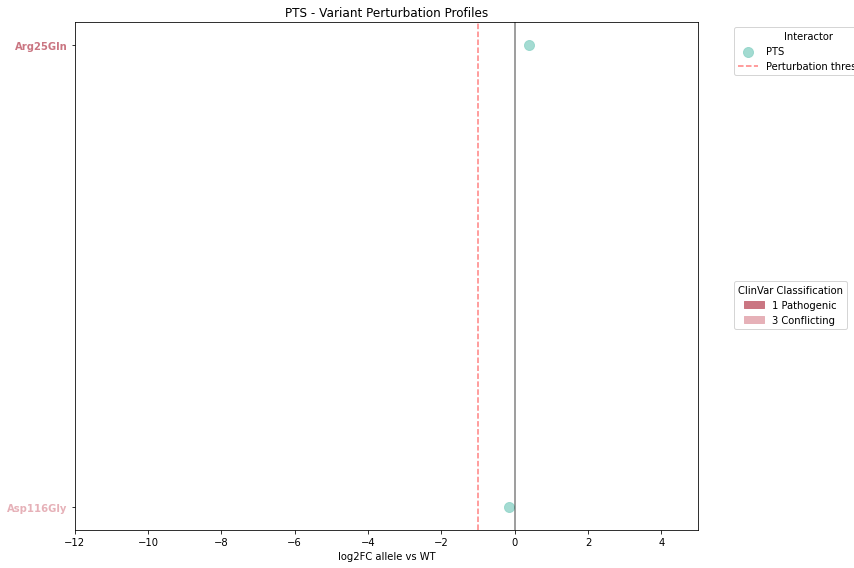


PTS summary:
  Number of variants: 2
  Number of interactors: 1
  Total interactions: 2


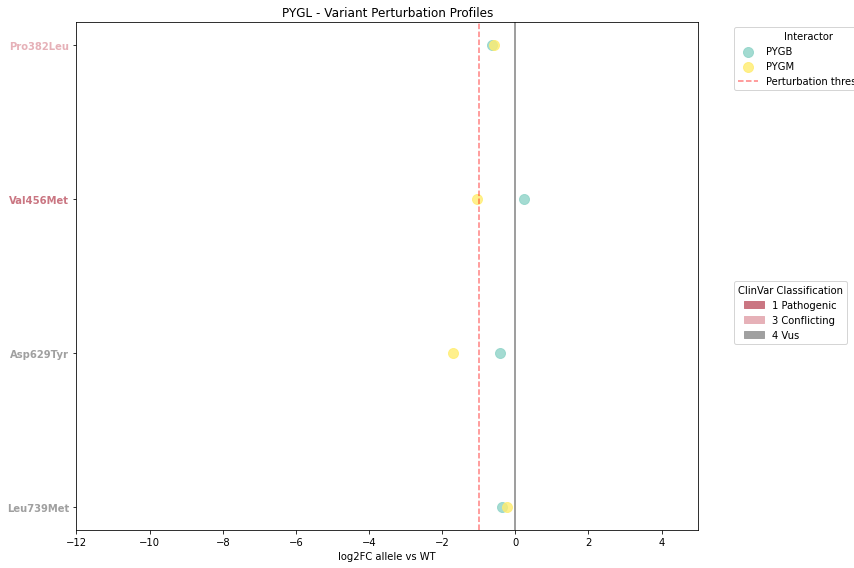


PYGL summary:
  Number of variants: 4
  Number of interactors: 2
  Total interactions: 8


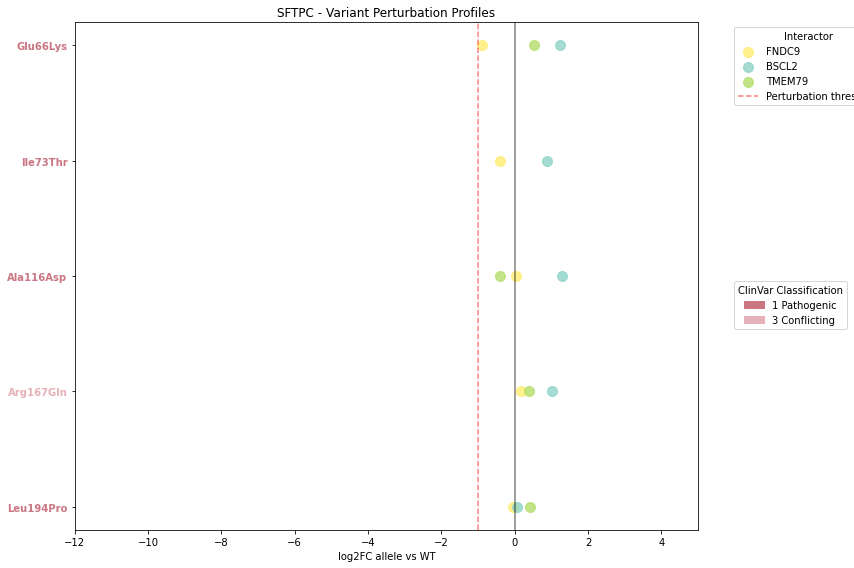


SFTPC summary:
  Number of variants: 5
  Number of interactors: 3
  Total interactions: 14


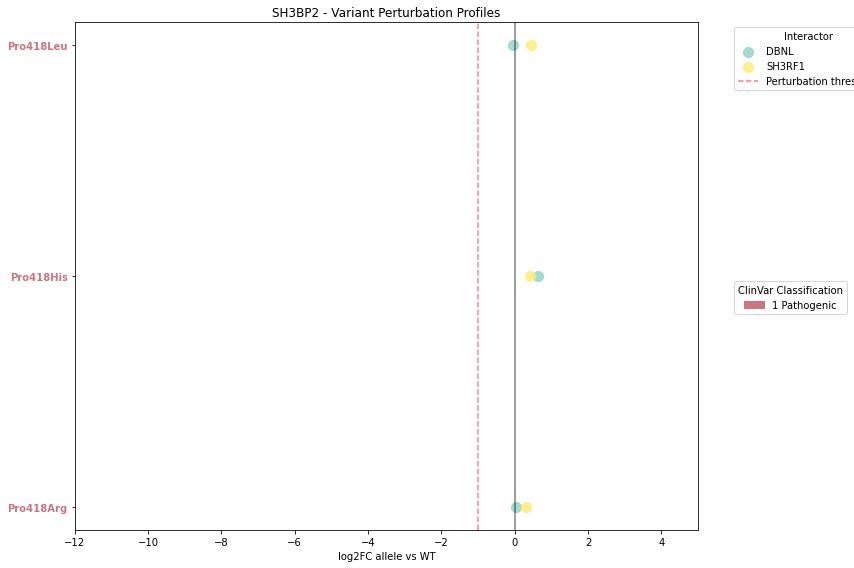


SH3BP2 summary:
  Number of variants: 3
  Number of interactors: 2
  Total interactions: 6


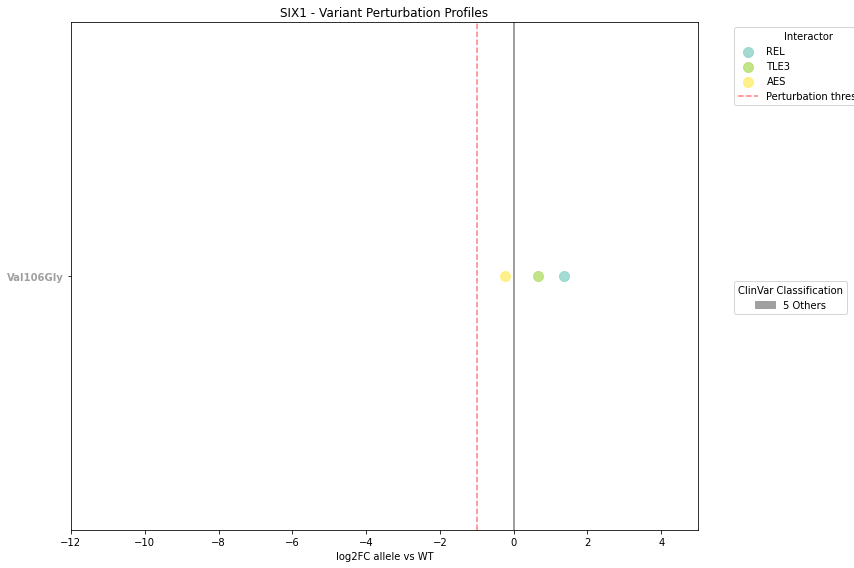


SIX1 summary:
  Number of variants: 1
  Number of interactors: 3
  Total interactions: 3


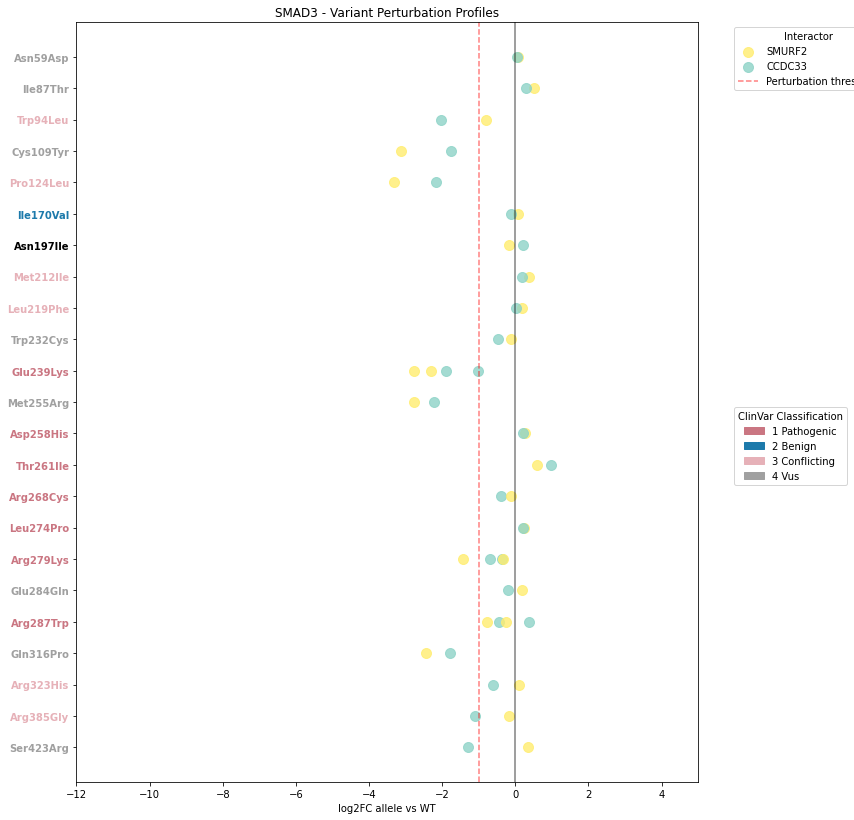


SMAD3 summary:
  Number of variants: 23
  Number of interactors: 2
  Total interactions: 52


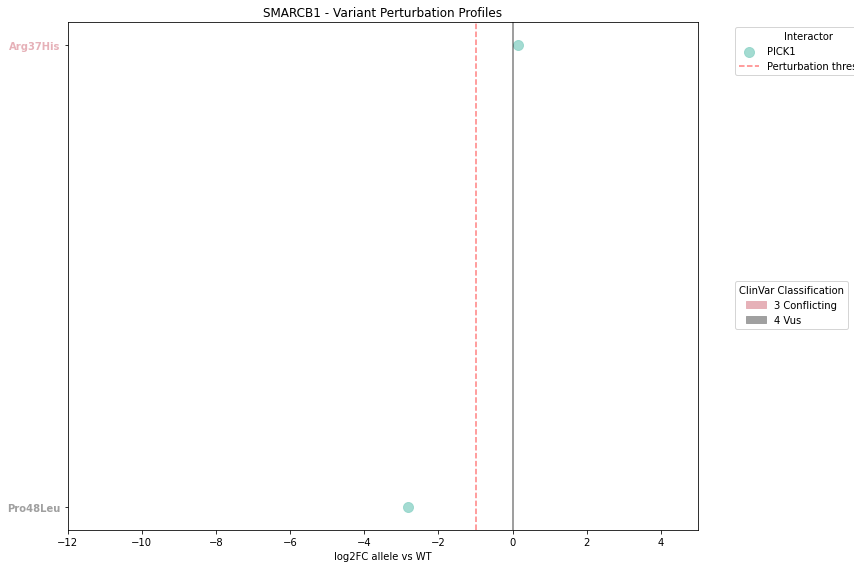


SMARCB1 summary:
  Number of variants: 2
  Number of interactors: 1
  Total interactions: 2


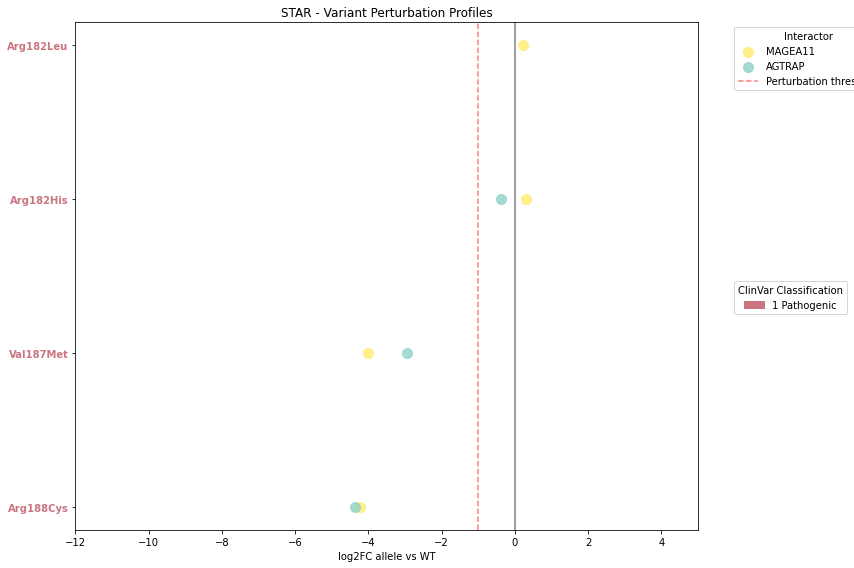


STAR summary:
  Number of variants: 4
  Number of interactors: 2
  Total interactions: 7


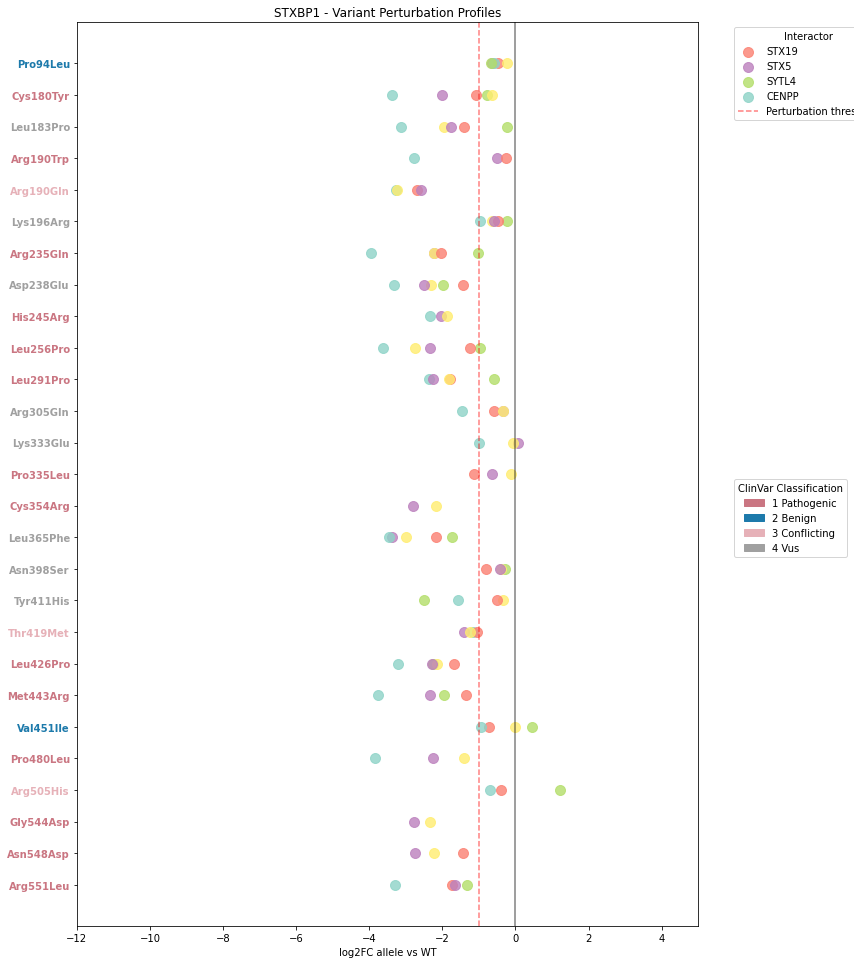


STXBP1 summary:
  Number of variants: 27
  Number of interactors: 5
  Total interactions: 107


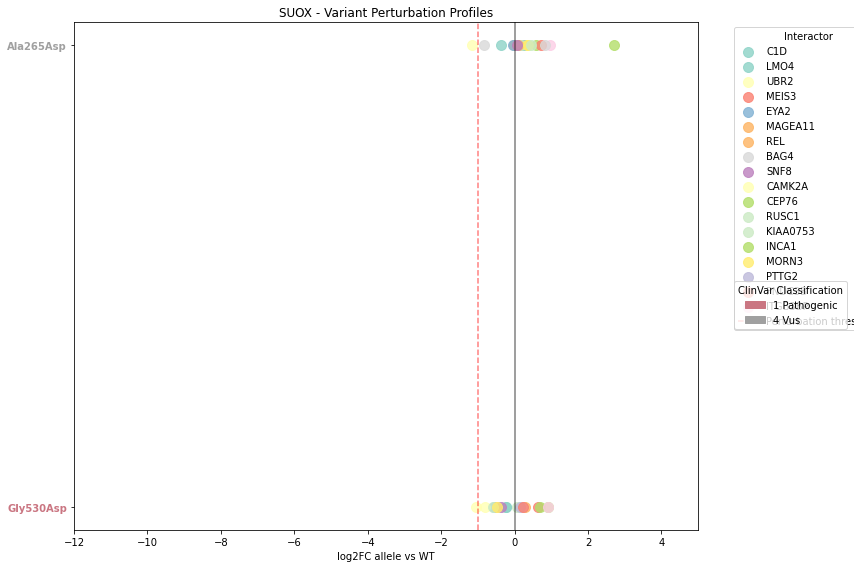


SUOX summary:
  Number of variants: 2
  Number of interactors: 20
  Total interactions: 38


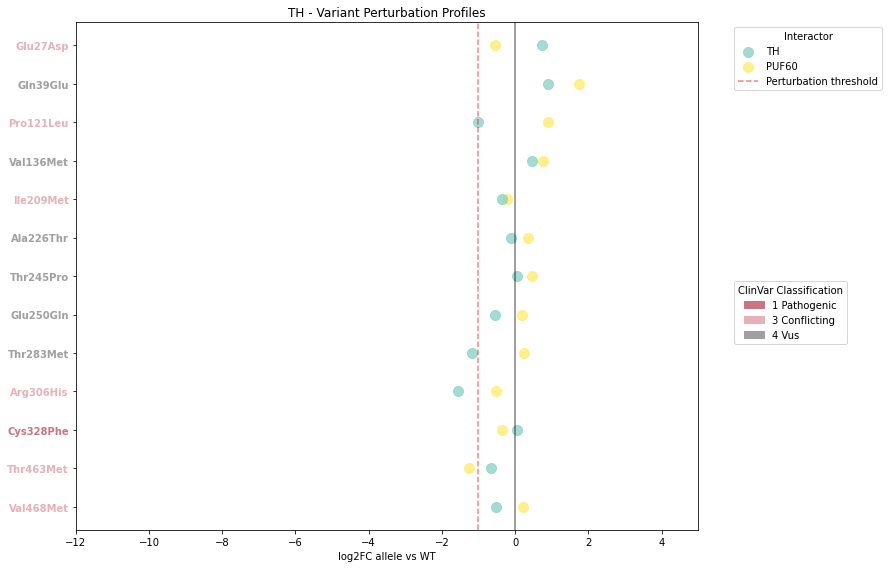


TH summary:
  Number of variants: 13
  Number of interactors: 2
  Total interactions: 26


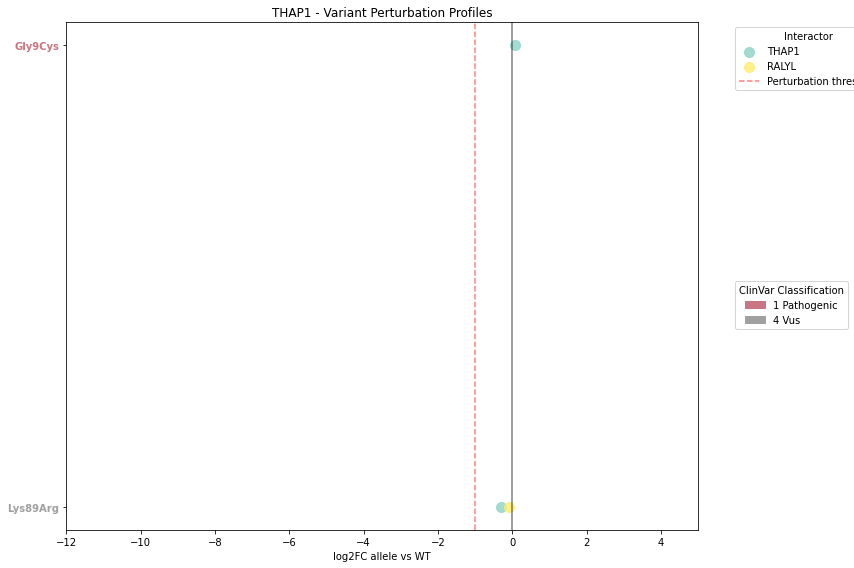


THAP1 summary:
  Number of variants: 2
  Number of interactors: 2
  Total interactions: 3


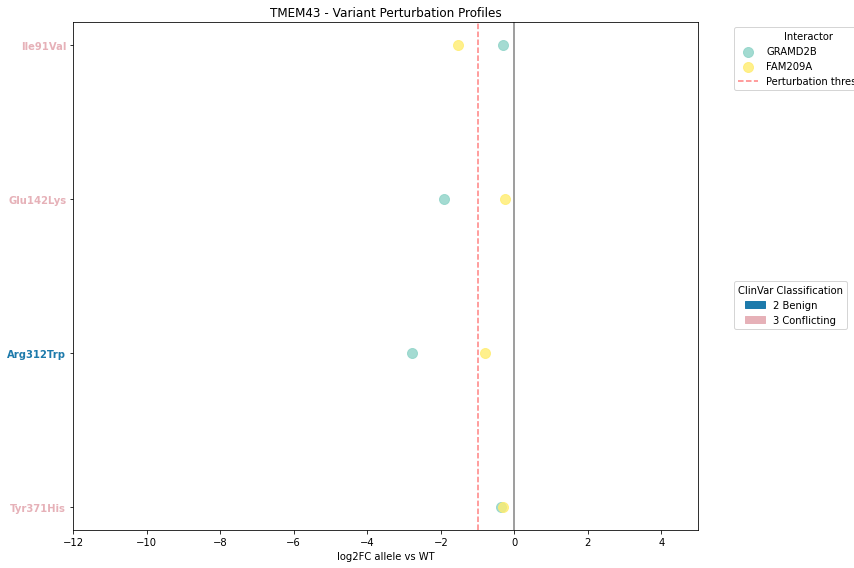


TMEM43 summary:
  Number of variants: 4
  Number of interactors: 2
  Total interactions: 8


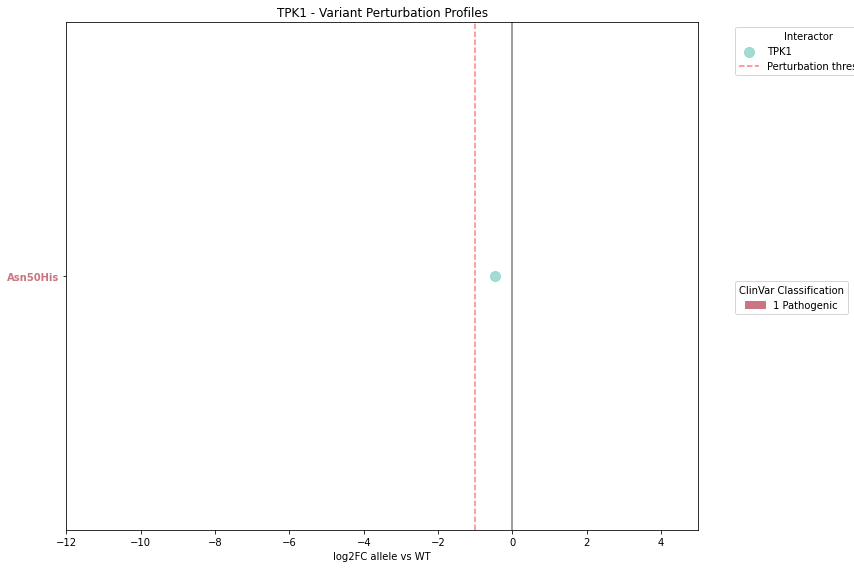


TPK1 summary:
  Number of variants: 1
  Number of interactors: 1
  Total interactions: 1


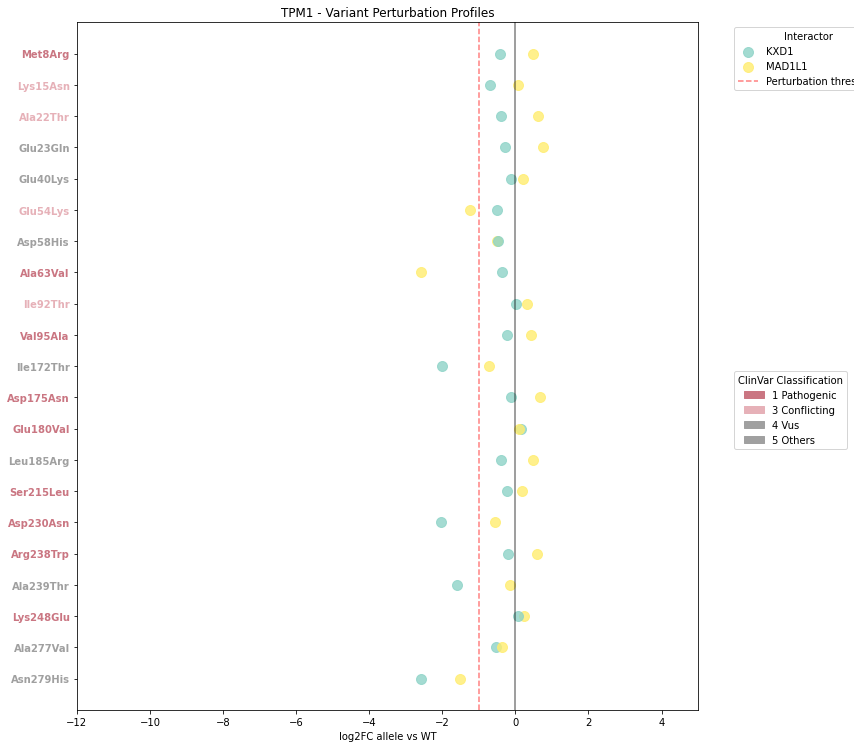


TPM1 summary:
  Number of variants: 21
  Number of interactors: 2
  Total interactions: 42


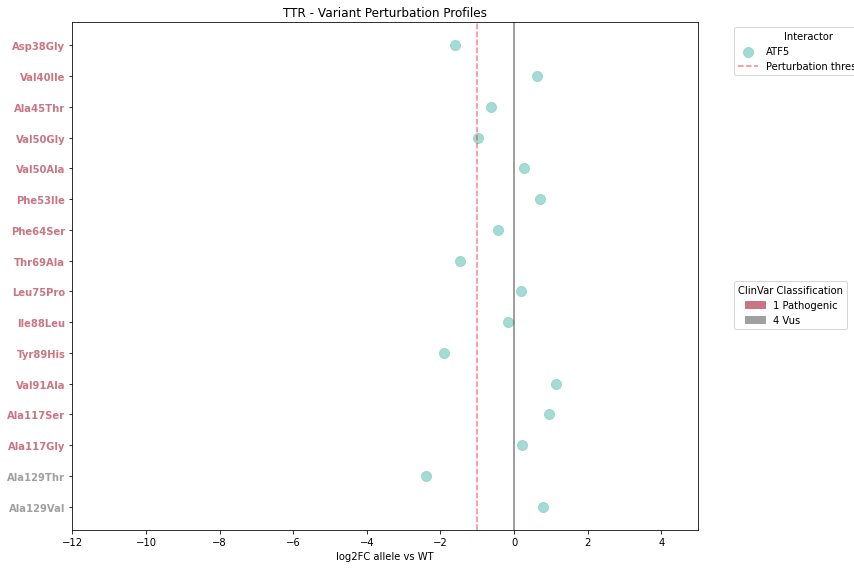


TTR summary:
  Number of variants: 16
  Number of interactors: 1
  Total interactions: 16


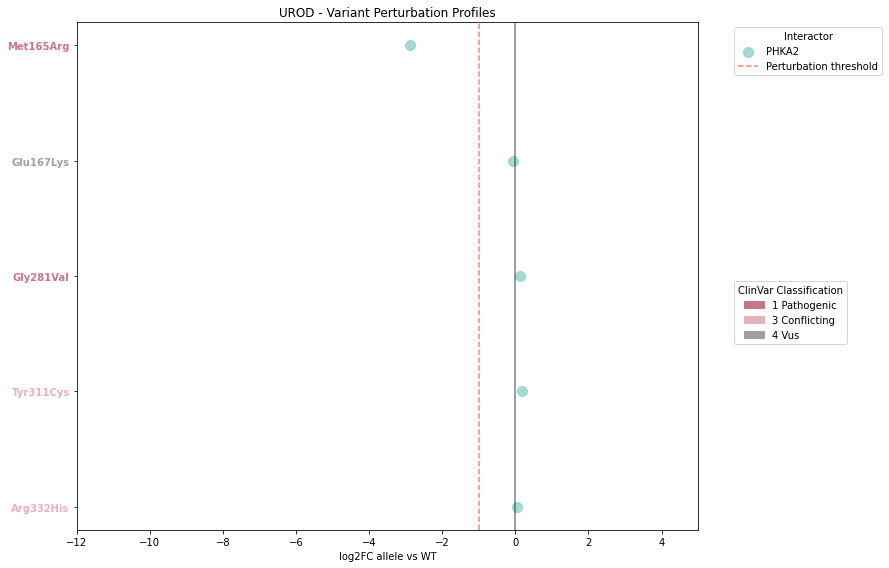


UROD summary:
  Number of variants: 5
  Number of interactors: 1
  Total interactions: 5


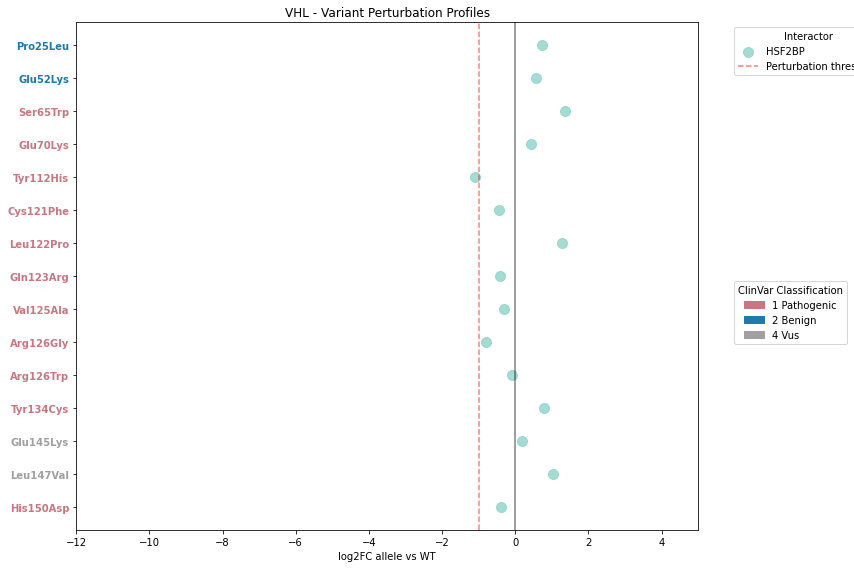


VHL summary:
  Number of variants: 15
  Number of interactors: 1
  Total interactions: 15


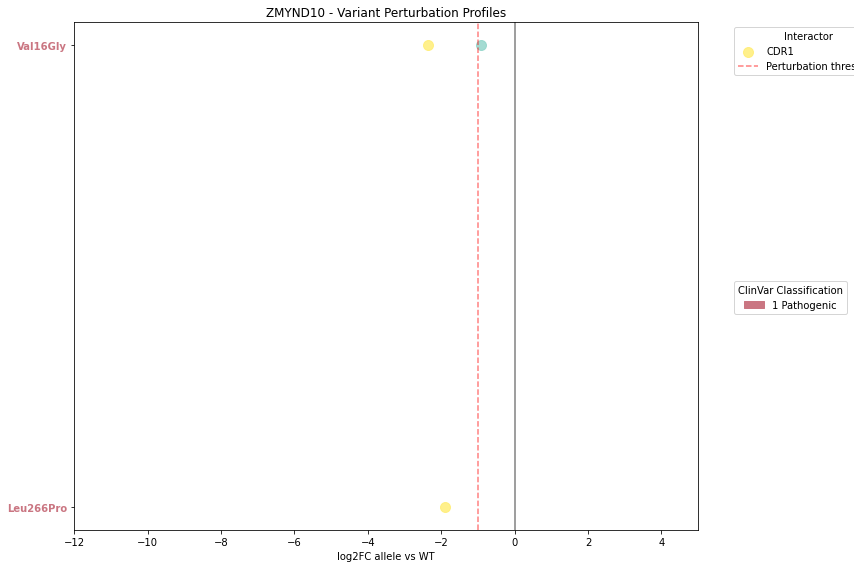


ZMYND10 summary:
  Number of variants: 2
  Number of interactors: 2
  Total interactions: 3


In [16]:

import matplotlib.pyplot as plt
import seaborn as sns
import re
# Create plots for the interesting genes
for gene in sorted(scores_pd.symbol.unique().tolist()):

    gene_data = scores.filter(pl.col("symbol") == gene)
    
    if gene_data.shape[0] == 0:
        print(f"No data found for {gene}")
        continue
    
    # Convert to pandas for easier plotting
    gene_pd = gene_data.to_pandas()
    
    # Extract position numbers and sort variants
    def extract_position(aa_change):
        match = re.search(r'(\d+)', aa_change)
        return int(match.group(1)) if match else 0
    
    variants = gene_pd['aa_change'].unique()
    variants_sorted = sorted(variants, key=extract_position, reverse=True)
    interactors = gene_pd['ad_symbol'].unique()
    
    # Create the plot
    fig, ax = plt.subplots(figsize=(12, max(8, len(variants) * 0.5)))
    
    # Color palette for interactors
    colors = plt.cm.Set3(np.linspace(0, 1, len(interactors)))
    interactor_colors = dict(zip(interactors, colors))
    
    # Plot each variant (using sorted order)
    for i, variant in enumerate(variants_sorted):
        variant_data = gene_pd[gene_pd['aa_change'] == variant]
        
        for _, row in variant_data.iterrows():
            interactor = row['ad_symbol']
            log2fc = row['log2fc']
            
            ax.scatter(log2fc, i, 
                      color=interactor_colors[interactor], 
                      s=100, 
                      alpha=0.8,
                      label=interactor if i == 0 else "")
    
    # Add vertical lines
    ax.axvline(x=0, color='black', linestyle='-', alpha=0.5)
    ax.axvline(x=-1, color='red', linestyle='--', alpha=0.5, label='Perturbation threshold')
    
    # Customize plot with colored variant labels
    ax.set_yticks(range(len(variants_sorted)))
    
    # Color y-axis labels based on ClinVar classification
    colored_labels = []
    clinvar_categories_used = set()
    for variant in variants_sorted:
        # Get ClinVar classification for this variant
        variant_row = gene_pd[gene_pd['aa_change'] == variant].iloc[0]
        clinvar_category = variant_row.get('clinvar_clnsig_clean', None)
        label_color = palette_dict["clinvar_clnsig_clean"].get(clinvar_category, "black")
        colored_labels.append((variant, label_color))
        if clinvar_category:
            clinvar_categories_used.add(clinvar_category)
    
    ax.set_yticklabels([label for label, color in colored_labels])
    
    # Apply colors to y-tick labels
    for i, (label, color) in enumerate(colored_labels):
        ax.get_yticklabels()[i].set_color(color)
        ax.get_yticklabels()[i].set_fontweight('bold')
    
    ax.set_xlabel('log2FC allele vs WT')
    ax.set_title(f'{gene} - Variant Perturbation Profiles')
    ax.set_xlim(-12, 5)
    
    # Handle interactor legend
    handles, labels = ax.get_legend_handles_labels()
    by_label = dict(zip(labels, handles))
    interactor_legend = ax.legend(by_label.values(), by_label.keys(), 
                                 bbox_to_anchor=(1.05, 1), loc='upper left', 
                                 title='Interactor')
    
    # Add ClinVar color legend
    clinvar_patches = []
    for category in sorted(clinvar_categories_used):
        color = palette_dict["clinvar_clnsig_clean"].get(category, "black")
        # Clean up category name for display
        display_name = category.replace('clinvar_clnsig_', '').replace('_', ' ').title()
        clinvar_patches.append(Patch(color=color, label=display_name))
    
    if clinvar_patches:
        clinvar_legend = ax.legend(handles=clinvar_patches, 
                                  bbox_to_anchor=(1.05, 0.5), loc='upper left',
                                  title='ClinVar Classification')
        
        # Add the interactor legend back (matplotlib removes it when adding new legend)
        ax.add_artist(interactor_legend)
    
    plt.tight_layout()
    plt.show()
    
    print(f"\n{gene} summary:")
    print(f"  Number of variants: {len(variants_sorted)}")
    print(f"  Number of interactors: {len(interactors)}")
    print(f"  Total interactions: {gene_pd.shape[0]}")

In [ ]:
# remove WT
scores = scores.filter(pl.col("db_mut_id") != 0)

# First, get edgetic variants
edgetic_variants = scores.filter(pl.col("variant_class_log2fc") == "E")

# Group by gene (symbol) and get variants with multiple edgetic alleles
genes_with_multiple_edgetic = (edgetic_variants
                              .group_by("symbol")
                              .agg(pl.col("aa_change").n_unique().alias("n_edgetic_variants"))
                              .filter(pl.col("n_edgetic_variants") > 1)
                              .select("symbol")
                              .to_series().to_list())

print(f"Found {len(genes_with_multiple_edgetic)} genes with multiple edgetic variants")

# Now analyze perturbation profiles for each gene - variant by variant approach
unique_edge_disruptions = {}

for gene in genes_with_multiple_edgetic:
    gene_edgetic_variants = edgetic_variants.filter(pl.col("symbol") == gene)
    
    # Get the edge-level data for this gene
    gene_scores = scores.filter(pl.col("symbol") == gene)
    
    # Get perturbation patterns for each variant
    variant_profiles = {}
    variant_omim = {}
    
    for row in gene_edgetic_variants.iter_rows(named=True):
        variant_id = row["aa_change"]
        allele_id = row["allele_0"]
        omim_id = row["OMIM_IDs"]
        
        # Get edges for this variant
        variant_edges = gene_scores.filter(pl.col("allele_0") == allele_id)
        
        # Get list of perturbed interactions (ad_orf_id)
        perturbed_edges = (variant_edges
                          .filter(pl.col("perturbed") == True)
                          .select("ad_orf_id")
                          .to_series().to_list())
        
        variant_profiles[variant_id] = set(perturbed_edges)
        variant_omim[variant_id] = omim_id
    
    # Find edges that are uniquely disrupted by each variant
    gene_results = []
    
    for variant, variant_edges in variant_profiles.items():
        # Get all edges disrupted by other variants
        other_variants_edges = set()
        for other_variant, other_edges in variant_profiles.items():
            if other_variant != variant:
                other_variants_edges.update(other_edges)
        
        # Find edges uniquely disrupted by this variant
        unique_edges = variant_edges - other_variants_edges
        
        if len(unique_edges) > 0:
            # Get interactor names for unique edges
            unique_interactors = (gene_scores
                                .filter(pl.col("ad_orf_id").is_in(list(unique_edges)))
                                .select("ad_symbol")
                                .unique()
                                .to_series().to_list())
            
            gene_results.append({
                'gene': gene,
                'variant': variant,
                'omim_id': variant_omim[variant],
                'unique_perturbed_edges': list(unique_edges),
                'unique_interactors': unique_interactors,
                'n_unique_edges': len(unique_edges),
                'total_perturbed_edges': len(variant_edges),
                'uniqueness_ratio': len(unique_edges) / len(variant_edges) if len(variant_edges) > 0 else 0
            })
    
    if gene_results:
        unique_edge_disruptions[gene] = gene_results

# Convert to DataFrame for easier analysis
all_unique_disruptions = []
for gene, variants in unique_edge_disruptions.items():
    all_unique_disruptions.extend(variants)

unique_disruptions_df = pl.DataFrame(all_unique_disruptions)

print(f"\nFound {len(all_unique_disruptions)} variants with uniquely disrupted edges")
print(f"Involving {unique_disruptions_df.select('gene').n_unique()} genes")

# Display results sorted by number of unique edges
print("\nVariants with uniquely disrupted edges (sorted by number of unique edges):")
for row in unique_disruptions_df.sort("n_unique_edges", descending=True).iter_rows(named=True):
    print(f"\nGene: {row['gene']}")
    print(f"  Variant: {row['variant']} (OMIM: {row['omim_id']})")
    print(f"  Unique edges: {row['n_unique_edges']} / {row['total_perturbed_edges']} total ({row['uniqueness_ratio']:.2%})")
    print(f"  Unique interactors: {', '.join(row['unique_interactors'])}")

# Summary statistics
print(f"\nSummary statistics:")
print(f"Average unique edges per variant: {unique_disruptions_df['n_unique_edges'].mean():.2f}")
print(f"Average uniqueness ratio: {unique_disruptions_df['uniqueness_ratio'].mean():.2%}")

# Show variants with high uniqueness (>50% of their edges are unique)
high_uniqueness = unique_disruptions_df.filter(pl.col("uniqueness_ratio") > 0.5)
print(f"\nVariants with >50% unique edges: {high_uniqueness.shape[0]}")

unique_disruptions_df

Found 20 genes with multiple edgetic variants

Found 18 variants with uniquely disrupted edges
Involving 13 genes

Variants with uniquely disrupted edges (sorted by number of unique edges):

Gene: EMD
  Variant: Met1Val (OMIM: None)
  Unique edges: 5 / 5 total (100.00%)
  Unique interactors: HSF2BP, SSMEM1, ZNF341, TMEM174, ZNF774

Gene: COQ8A
  Variant: Gly272Asp (OMIM: ['612016'])
  Unique edges: 3 / 5 total (60.00%)
  Unique interactors: AGTRAP, CMTM5, SH3GLB1

Gene: PLP1
  Variant: Gly74Arg (OMIM: None)
  Unique edges: 2 / 12 total (16.67%)
  Unique interactors: KLRC1, MS4A3

Gene: PRKAR1A
  Variant: Arg335Pro (OMIM: ['101800'])
  Unique edges: 1 / 1 total (100.00%)
  Unique interactors: C2orf88

Gene: PRKAR1A
  Variant: Tyr373His (OMIM: ['101800', '160980'])
  Unique edges: 1 / 1 total (100.00%)
  Unique interactors: PRKACA

Gene: EMD
  Variant: Ser54Phe (OMIM: ['310300'])
  Unique edges: 1 / 1 total (100.00%)
  Unique interactors: CCDC155

Gene: PLP1
  Variant: Thr147Pro (OMIM: [

gene,variant,omim_id,unique_perturbed_edges,unique_interactors,n_unique_edges,total_perturbed_edges,uniqueness_ratio
str,str,str,list[i64],list[str],i64,i64,f64
"""PRKAR1A""","""Arg335Pro""","""['101800']""",[5065],"[""C2orf88""]",1,1,1.0
"""PRKAR1A""","""Tyr373His""","""['101800', '160980']""",[71136],"[""PRKACA""]",1,1,1.0
"""EMD""","""Met1Val""",null,"[55045, 14269, … 100070143]","[""HSF2BP"", ""SSMEM1"", … ""ZNF774""]",5,5,1.0
"""EMD""","""Ser54Phe""","""['310300']""",[9267],"[""CCDC155""]",1,1,1.0
"""PLP1""","""Gly74Arg""",null,"[5793, 13628]","[""KLRC1"", ""MS4A3""]",2,12,0.166667
…,…,…,…,…,…,…,…
"""ACSF3""","""Met198Arg""","""['614265']""",[54668],"[""KRT40""]",1,1,1.0
"""ACSF3""","""Glu359Lys""","""['614265']""",[10441],"[""RAB28""]",1,1,1.0
"""STXBP1""","""Tyr411His""",null,[199],"[""SYTL4""]",1,2,0.5


In [ ]:
import py3Dmol

# From a PDB ID (needs internet) 
v = py3Dmol.view(query='pdb:1crn', width=700, height=500)
v.setStyle({'cartoon': {'color':'spectrum'}})     # protein cartoon
v.addStyle({'hetflag':True}, {'stick':{}})        # ligands as sticks
v.zoomTo(); v

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

# lwh1

In [ ]:
scores

ad_orf_id,db_orf_id,db_mut_id,retest_batch,n_conditions,summed_consensus_score,lwh1_consensus_score,summed_consensus_score_normalized,lwh1_consensus_score_normalized,wt_summed_score,wt_summed_score_normalized,wt_lwh1_score,wt_lwh1_score_normalized,condition_name,assay_id,ppi_group,seq_ad,seq_db,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,variant_class_log2fc,log2fc,perturbed,OMIM_IDs
i64,i64,i64,str,i64,f64,f64,f64,f64,f64,f64,f64,f64,str,i64,str,i64,i64,str,str,str,str,str,str,str,f64,f64,str,str,f64,bool,str
71892,71892,4025,"""VUSAPWT1B1""",4,1912.367056,592.911139,0.637456,0.790548,1031.692838,0.343898,478.204593,0.637606,"""LWH25""",1,"""71892_71892_4025_VUSAPWT1B1""",1,1,"""TH""","""TH""","""Gln39Glu""","""115C>G""","""ENSG00000180176""","""Edgotyping3""","""4_VUS""",null,2.0,"""TH_Gln39Glu""","""QW""",0.890153,false,"""['605407']"""
53964,2713,200868,"""VUSAPWT1B1""",4,1228.076072,523.374859,0.409359,0.697833,1288.531081,0.42951,569.921595,0.759895,"""LWA""",1,"""53964_2713_200868_VUSAPWT1B1""",1,1,"""NFIX""","""MLH1""","""Asp485Glu""","""1455T>A""","""ENSG00000076242""","""CEGS2""",null,null,null,"""MLH1_Asp485Glu""","""E""",-0.069311,false,null
1769,3535,201190,"""VUSAPWT1B1""",4,1659.255291,457.622571,0.553085,0.610163,439.581705,0.146527,null,null,"""LWH10""",1,"""1769_3535_201190_VUSAPWT1B1""",1,1,"""CATSPER1""","""EMD""","""Met1Val""","""1A>G""","""ENSG00000102119""","""CEGS2""","""1_Pathogenic""",9.5000e-7,2.0,"""EMD_Met1Val""","""E""",1.915609,false,null
100011278,4870,215278,"""VUSAPWT1B2""",4,1961.890901,556.531721,0.653964,0.742042,2091.510527,0.69717,584.688263,0.779584,"""LWH1""",1,"""100011278_4870_215278_VUSAPWT1…",1,1,"""KRT16""","""KRT6A""","""Gln166Pro""","""497A>C""","""ENSG00000205420""","""CEGS2""","""5_Others""",null,null,"""KRT6A_Gln166Pro""","""QW""",-0.092287,false,null
100064217,3535,6172,"""VUSAPWT1B1""",4,1985.396159,646.694144,0.661799,0.862259,1656.205287,0.552068,null,null,"""LWA""",1,"""100064217_3535_6172_VUSAPWT1B1""",1,1,"""GRAMD2A""","""EMD""","""Pro183His""","""548C>A""","""ENSG00000102119""","""RC4""","""1_Pathogenic""",null,1.0,"""EMD_Pro183His""","""QW""",0.261502,false,null
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
71715,52920,2684,"""VUSAPWT1B1""",4,2010.792564,577.589896,0.670264,0.77012,1927.363133,0.642454,523.837605,0.69845,"""LWH25""",1,"""71715_52920_2684_VUSAPWT1B1""",1,1,"""EPN2""","""LITAF""","""Pro51Ser""","""151C>T""","""ENSG00000189067""","""Edgotyping3""","""4_VUS""",null,1.0,"""LITAF_Pro51Ser""","""QW""",0.061127,false,"""['601098']"""
71892,71892,4008,"""VUSAPWT1B1""",4,707.294785,405.478768,0.235765,0.540638,1031.692838,0.343898,478.204593,0.637606,"""LWH1""",1,"""71892_71892_4008_VUSAPWT1B1""",1,1,"""TH""","""TH""","""Glu250Gln""","""748G>C""","""ENSG00000180176""","""Edgotyping3""","""4_VUS""",null,1.0,"""TH_Glu250Gln""","""QW""",-0.544438,false,null
56463,3535,201190,"""VUSAPWT1B1""",4,984.869308,555.351328,0.32829,0.740468,413.419613,0.137807,null,null,"""LWA""",1,"""56463_3535_201190_VUSAPWT1B1""",1,1,"""LUZP4""","""EMD""","""Met1Val""","""1A>G""","""ENSG00000102119""","""CEGS2""","""1_Pathogenic""",9.5000e-7,2.0,"""EMD_Met1Val""","""E""",1.251718,false,null


In [ ]:
scores = pl.read_csv(f"{outputs_dir}/4_automated_normalized_consensus_scores.csv")
# scores = scores.drop_nulls(subset=["summed_consensus_score_lwh1", "wt_summed_score_lwh1"])
scores

ad_orf_id,db_orf_id,db_mut_id,retest_batch,n_conditions,summed_consensus_score,lwh1_consensus_score,summed_consensus_score_normalized,lwh1_consensus_score_normalized,wt_summed_score,wt_summed_score_normalized,wt_lwh1_score,wt_lwh1_score_normalized,condition_name,assay_id,ppi_group,seq_ad,seq_db,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0
i64,i64,i64,str,i64,f64,f64,f64,f64,f64,f64,f64,f64,str,i64,str,i64,i64,str,str,str,str,str,str,str,f64,f64,str
71892,71892,4025,"""VUSAPWT1B1""",4,1912.367056,592.911139,0.637456,0.790548,1031.692838,0.343898,478.204593,0.637606,"""LWH25""",1,"""71892_71892_4025_VUSAPWT1B1""",1,1,"""TH""","""TH""","""Gln39Glu""","""115C>G""","""ENSG00000180176""","""Edgotyping3""","""4_VUS""",null,2.0,"""TH_Gln39Glu"""
11567,5431,0,"""VUSAPWT1B2""",4,1068.310806,358.164713,0.356104,0.477553,1068.310806,0.356104,358.164713,0.477553,"""LWH25""",1,"""11567_5431_0_VUSAPWT1B2""",1,1,"""TAX1BP1""","""POLR1C""",null,null,"""ENSG00000171453""",null,null,null,null,"""POLR1C"""
53964,2713,200868,"""VUSAPWT1B1""",4,1228.076072,523.374859,0.409359,0.697833,1288.531081,0.42951,569.921595,0.759895,"""LWA""",1,"""53964_2713_200868_VUSAPWT1B1""",1,1,"""NFIX""","""MLH1""","""Asp485Glu""","""1455T>A""","""ENSG00000076242""","""CEGS2""",null,null,null,"""MLH1_Asp485Glu"""
1769,3535,201190,"""VUSAPWT1B1""",4,1659.255291,457.622571,0.553085,0.610163,439.581705,0.146527,null,null,"""LWH10""",1,"""1769_3535_201190_VUSAPWT1B1""",1,1,"""CATSPER1""","""EMD""","""Met1Val""","""1A>G""","""ENSG00000102119""","""CEGS2""","""1_Pathogenic""",9.5000e-7,2.0,"""EMD_Met1Val"""
100011278,4870,215278,"""VUSAPWT1B2""",4,1961.890901,556.531721,0.653964,0.742042,2091.510527,0.69717,584.688263,0.779584,"""LWH1""",1,"""100011278_4870_215278_VUSAPWT1…",1,1,"""KRT16""","""KRT6A""","""Gln166Pro""","""497A>C""","""ENSG00000205420""","""CEGS2""","""5_Others""",null,null,"""KRT6A_Gln166Pro"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
71892,71892,4008,"""VUSAPWT1B1""",4,707.294785,405.478768,0.235765,0.540638,1031.692838,0.343898,478.204593,0.637606,"""LWH1""",1,"""71892_71892_4008_VUSAPWT1B1""",1,1,"""TH""","""TH""","""Glu250Gln""","""748G>C""","""ENSG00000180176""","""Edgotyping3""","""4_VUS""",null,1.0,"""TH_Glu250Gln"""
56463,3535,201190,"""VUSAPWT1B1""",4,984.869308,555.351328,0.32829,0.740468,413.419613,0.137807,null,null,"""LWA""",1,"""56463_3535_201190_VUSAPWT1B1""",1,1,"""LUZP4""","""EMD""","""Met1Val""","""1A>G""","""ENSG00000102119""","""CEGS2""","""1_Pathogenic""",9.5000e-7,2.0,"""EMD_Met1Val"""
4351,2713,200850,"""VUSAPWT6B1""",3,403.768313,null,0.134589,null,1745.430348,0.58181,470.184985,0.626913,"""LWH10""",6,"""4351_2713_200850_VUSAPWT6B1""",1,1,"""NME4""","""MLH1""","""Ser295Thr""","""884G>C""","""ENSG00000076242""","""CEGS2""","""4_VUS""",null,3.0,"""MLH1_Ser295Thr"""


In [ ]:
scores = pl.read_csv(f"{outputs_dir}/4_automated_normalized_consensus_scores.csv")
scores = scores.drop_nulls(subset=["lwh1_consensus_score_normalized", "wt_lwh1_score_normalized"])

# keep only scores where there is at least one matched reference-variant set
orfs_with_alleles = scores.filter(pl.col("db_mut_id") != 0).select("db_orf_id").unique().to_series().to_list()
orfs = scores.filter(pl.col("db_mut_id") == 0).select("db_orf_id").unique().to_series().to_list()

complete_orf_pairs = [i for i in orfs if i in orfs_with_alleles]
scores = scores.filter(pl.col("db_orf_id").is_in(complete_orf_pairs))
genes = scores.select("db_orf_id").to_series().unique().to_list()

# map variant classes

classes_df = pl.read_csv(f"{outputs_dir}/6_variants_perturbation_scores_automated_annotated.csv")

# Join scores with variant classes on allele_0
scores = scores.join(
    classes_df.select(["allele_0", "variant_class_log2fc_lwh1"]), 
    on="allele_0", 
    how="left"
)

# Remove WT and calculate log2fc and perturbed status
scores = scores.filter(pl.col("db_mut_id") != 0).with_columns([
    ((pl.col("lwh1_consensus_score_normalized") + 0.0001) / 
     (pl.col("wt_lwh1_score_normalized") + 0.0001)).log(2).alias("log2fc_lwh1")
]).with_columns([
    (pl.col("log2fc_lwh1") <= -1).alias("perturbed")
])

# Map OMIM IDs to scores using allele_0 column
scores = scores.with_columns([
    pl.col("allele_0").map_elements(
        lambda x: omim_dict.get(x, None) if pd.notna(omim_dict.get(x, None)) else None,
        return_dtype=pl.Utf8
    ).alias("OMIM_IDs")
])

scores

ColumnNotFoundError: variant_class_log2fc_lwh1

Resolved plan until failure:

	---> FAILED HERE RESOLVING 'select' <---
DF ["euclid_distance", "max_perturbation", "max_relative_perturbation", "max_perturbation_abs", ...]; PROJECT */43 COLUMNS

In [ ]:
# remove WT
scores = scores.filter(pl.col("db_mut_id") != 0)

# First, get edgetic variants
edgetic_variants = scores.filter(pl.col("variant_class_log2fc_lwh1") == "E")

# Group by gene (symbol) and get variants with multiple edgetic alleles
genes_with_multiple_edgetic = (edgetic_variants
                              .group_by("symbol")
                              .agg(pl.col("aa_change").n_unique().alias("n_edgetic_variants"))
                              .filter(pl.col("n_edgetic_variants") > 1)
                              .select("symbol")
                              .to_series().to_list())

print(f"Found {len(genes_with_multiple_edgetic)} genes with multiple edgetic variants")

# Now analyze perturbation profiles for each gene
perturbation_profiles = {}
variant_omim_mapping = {}

for gene in genes_with_multiple_edgetic:
    gene_edgetic_variants = edgetic_variants.filter(pl.col("symbol") == gene)
    
    # Get the edge-level data for this gene
    gene_scores = scores.filter(pl.col("symbol") == gene)
    
    # Get perturbation patterns for each variant
    variant_profiles = {}
    variant_omim = {}
    
    for row in gene_edgetic_variants.iter_rows(named=True):
        variant_id = row["aa_change"]
        allele_id = row["allele_0"]
        omim_id = row["OMIM_IDs"]
        
        # Get edges for this variant
        variant_edges = gene_scores.filter(pl.col("allele_0") == allele_id)
        
        # Get list of perturbed interactions (ad_orf_id)
        perturbed_edges = (variant_edges
                          .filter(pl.col("perturbed") == True)
                          .select("ad_orf_id")
                          .to_series().to_list())
        
        variant_profiles[variant_id] = set(perturbed_edges)
        variant_omim[variant_id] = omim_id
    
    perturbation_profiles[gene] = variant_profiles
    variant_omim_mapping[gene] = variant_omim

# Compare profiles between variants within each gene
differential_edgetic_variants = {}

for gene, profiles in perturbation_profiles.items():
    variants = list(profiles.keys())
    gene_results = []
    
    for i in range(len(variants)):
        for j in range(i+1, len(variants)):
            var1, var2 = variants[i], variants[j]
            profile1, profile2 = profiles[var1], profiles[var2]
            
            # Get OMIM IDs for comparison
            omim1 = variant_omim_mapping[gene][var1]
            omim2 = variant_omim_mapping[gene][var2]

            # Helper function to check if OMIM is valid (not None, not ['None'], not empty)
            def is_valid_omim(omim_val):
                if omim_val is None:
                    return False
                if isinstance(omim_val, str):
                    # Handle string representation of lists like "['312920', '312080']"
                    if omim_val.startswith('[') and omim_val.endswith(']'):
                        try:
                            import ast
                            omim_list = ast.literal_eval(omim_val)
                            return len(omim_list) > 0 and not (len(omim_list) == 1 and str(omim_list[0]).lower() == 'none')
                        except:
                            return omim_val.lower() != 'none' and omim_val.strip() != ''
                    else:
                        return omim_val.lower() != 'none' and omim_val.strip() != ''
                if isinstance(omim_val, list):
                    return len(omim_val) > 0 and not (len(omim_val) == 1 and str(omim_val[0]).lower() == 'none')
                return False

            # Helper function to convert OMIM to set for comparison
            def omim_to_set(omim_val):
                if omim_val is None:
                    return set()
                if isinstance(omim_val, str):
                    # Handle string representation of lists like "['312920', '312080']"
                    if omim_val.startswith('[') and omim_val.endswith(']'):
                        try:
                            import ast
                            omim_list = ast.literal_eval(omim_val)
                            return set(str(x) for x in omim_list if str(x).lower() != 'none')
                        except:
                            return {omim_val} if omim_val.lower() != 'none' else set()
                    else:
                        return {omim_val} if omim_val.lower() != 'none' else set()
                if isinstance(omim_val, list):
                    return set(str(x) for x in omim_val if str(x).lower() != 'none')
                return set()

            # Check if OMIM IDs are completely different (no overlap)
            valid_omim1 = is_valid_omim(omim1)
            valid_omim2 = is_valid_omim(omim2)

            if valid_omim1 and valid_omim2:
                omim_set1 = omim_to_set(omim1)
                omim_set2 = omim_to_set(omim2)
                # Check if they have NO overlap (intersection is empty)
                different_omim = len(omim_set1.intersection(omim_set2)) == 0
            else:
                different_omim = False

            # Calculate overlap and differences
            intersection = profile1.intersection(profile2)
            var1_only = profile1 - profile2
            var2_only = profile2 - profile1
            
            # Calculate similarity metrics
            union = profile1.union(profile2)
            jaccard = len(intersection) / len(union) if len(union) > 0 else 0
            
            gene_results.append({
                'gene': gene,
                'variant1': var1,
                'variant2': var2,
                'omim1': omim1,
                'omim2': omim2,
                'different_omim': different_omim,
                'shared_perturbed': list(intersection),
                'variant1_only_perturbed': list(var1_only),
                'variant2_only_perturbed': list(var2_only),
                'n_shared': len(intersection),
                'n_var1_only': len(var1_only),
                'n_var2_only': len(var2_only),
                'jaccard_similarity': jaccard,
                'total_var1_perturbed': len(profile1),
                'total_var2_perturbed': len(profile2)
            })
    
    differential_edgetic_variants[gene] = gene_results

# Convert to DataFrame for easier analysis
all_comparisons = []
for gene, comparisons in differential_edgetic_variants.items():
    all_comparisons.extend(comparisons)

comparison_df = pl.DataFrame(all_comparisons)

# Filter for variants with different profiles (low Jaccard similarity and some unique perturbations) AND different OMIM IDs
differential_variants = comparison_df.filter(
    # (pl.col("jaccard_similarity") < 0.7) &  # Less than 70% similarity
    (pl.col("n_var1_only") > 0) &           # Variant 1 has unique perturbations
    (pl.col("n_var2_only") > 0) &           # Variant 2 has unique perturbations
    (pl.col("different_omim") == True) #&
    # (pl.col("n_shared") > 0) 
)

print(f"\nFound {differential_variants.shape[0]} variant pairs with differential edgetic profiles AND different OMIM IDs")
print(f"Involving {differential_variants.select('gene').n_unique()} genes")

# Display results with interactor names
print("\nDifferential edgetic variant pairs with different OMIM IDs:")
for row in differential_variants.iter_rows(named=True):
    print(f"\nGene: {row['gene']}")
    print(f"  {row['variant1']} (OMIM: {row['omim1']}) vs {row['variant2']} (OMIM: {row['omim2']})")
    print(f"  Shared perturbed edges: {row['n_shared']}")
    print(f"  {row['variant1']} unique: {row['n_var1_only']}")
    print(f"  {row['variant2']} unique: {row['n_var2_only']}")
    print(f"  Jaccard similarity: {row['jaccard_similarity']:.3f}")
    
    # Get interactor names for shared and unique perturbations
    gene_data = scores.filter(pl.col("symbol") == row['gene'])
    
    # Shared perturbed interactors
    if row['shared_perturbed']:
        shared_interactors = (gene_data
                             .filter(pl.col("ad_orf_id").is_in(row['shared_perturbed']))
                             .select("ad_symbol")
                             .unique()
                             .to_series().to_list())
        print(f"  Shared perturbed interactors: {', '.join(shared_interactors)}")
    
    # Variant 1 unique perturbed interactors
    if row['variant1_only_perturbed']:
        var1_unique_interactors = (gene_data
                                  .filter(pl.col("ad_orf_id").is_in(row['variant1_only_perturbed']))
                                  .select("ad_symbol")
                                  .unique()
                                  .to_series().to_list())
        print(f"  {row['variant1']} unique perturbed interactors: {', '.join(var1_unique_interactors)}")
    
    # Variant 2 unique perturbed interactors
    if row['variant2_only_perturbed']:
        var2_unique_interactors = (gene_data
                                  .filter(pl.col("ad_orf_id").is_in(row['variant2_only_perturbed']))
                                  .select("ad_symbol")
                                  .unique()
                                  .to_series().to_list())
        print(f"  {row['variant2']} unique perturbed interactors: {', '.join(var2_unique_interactors)}")

differential_variants

ColumnNotFoundError: unable to find column "variant_class_log2fc_lwh1"; valid columns: ["ad_orf_id", "db_orf_id", "db_mut_id", "retest_batch", "n_conditions", "summed_consensus_score", "lwh1_consensus_score", "summed_consensus_score_normalized", "lwh1_consensus_score_normalized", "wt_summed_score", "wt_summed_score_normalized", "wt_lwh1_score", "wt_lwh1_score_normalized", "condition_name", "assay_id", "ppi_group", "seq_ad", "seq_db", "ad_symbol", "symbol", "aa_change", "nt_change", "ensembl_gene_id", "collection", "clinvar_clnsig_clean", "gnomad_af", "StarStatus", "allele_0", "variant_class_log2fc", "log2fc", "perturbed", "OMIM_IDs"]

Resolved plan until failure:

	---> FAILED HERE RESOLVING 'filter' <---
DF ["ad_orf_id", "db_orf_id", "db_mut_id", "retest_batch", ...]; PROJECT */32 COLUMNS

<Axes: >

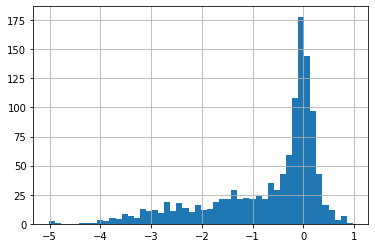

In [ ]:
scores.to_pandas().log2fc_lwh1.hist(bins=50)

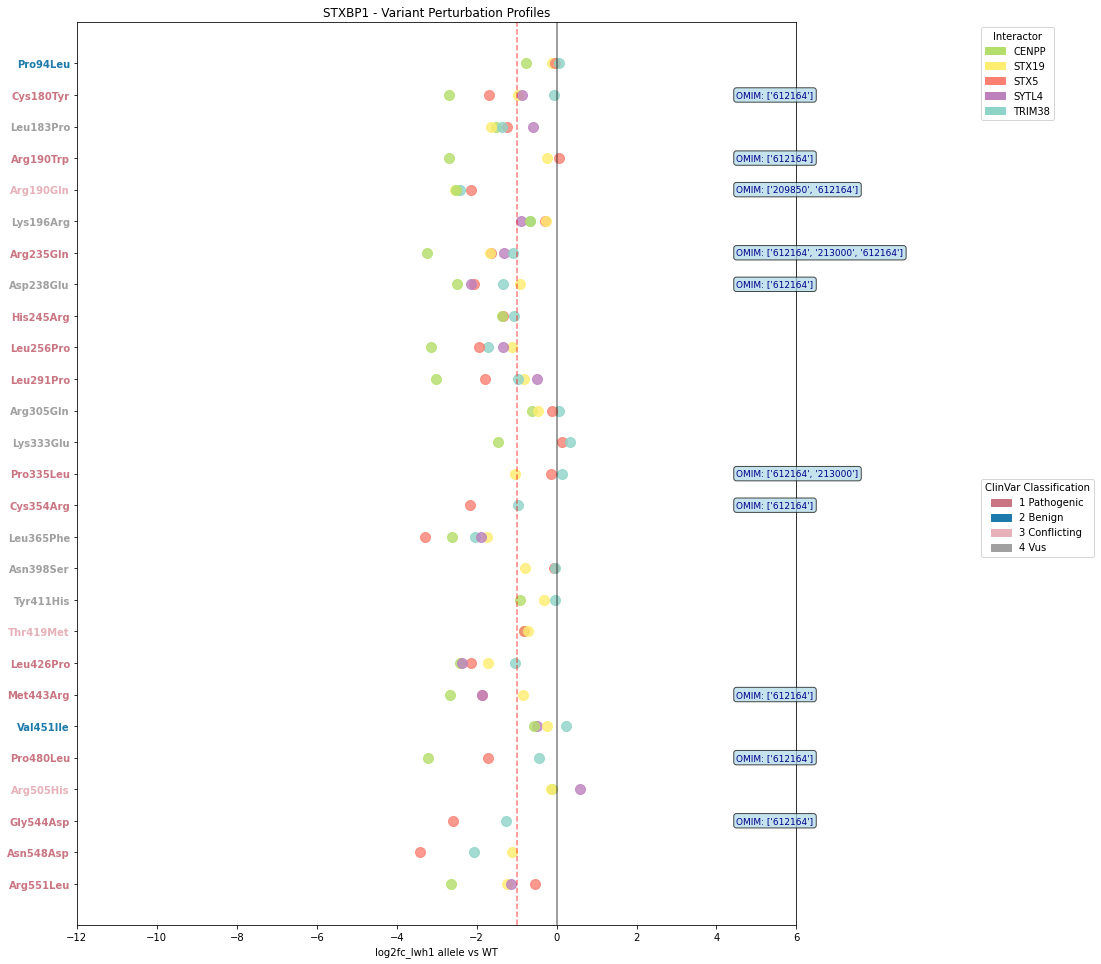

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import re
from matplotlib.patches import Patch

# Create plots for the interesting genes
for gene in interesting_genes:
    gene_data = scores.filter(pl.col("symbol") == gene)
    
    if gene_data.shape[0] == 0:
        print(f"No data found for {gene}")
        continue
    
    # Convert to pandas for easier plotting
    gene_pd = gene_data.to_pandas()
    
    # Extract position numbers and sort variants
    def extract_position(aa_change):
        match = re.search(r'(\d+)', aa_change)
        return int(match.group(1)) if match else 0
    
    variants = gene_pd['aa_change'].unique()
    variants_sorted = sorted(variants, key=extract_position, reverse=True)
    interactors = gene_pd['ad_symbol'].unique()
    
    # Create the plot with extra space for OMIM annotations
    fig, ax = plt.subplots(figsize=(16, max(8, len(variants) * 0.5)))
    
    # Color palette for interactors
    colors = plt.cm.Set3(np.linspace(0, 1, len(interactors)))
    interactor_colors = dict(zip(interactors, colors))
    
    # Plot each variant (using sorted order)
    for i, variant in enumerate(variants_sorted):
        variant_data = gene_pd[gene_pd['aa_change'] == variant]
        
        for _, row in variant_data.iterrows():
            interactor = row['ad_symbol']
            log2fc_lwh1 = row['log2fc_lwh1']
            
            ax.scatter(log2fc_lwh1, i, 
                      color=interactor_colors[interactor], 
                      s=100, 
                      alpha=0.8,
                      label=interactor if i == 0 else "")
    
    # Add vertical lines
    ax.axvline(x=0, color='black', linestyle='-', alpha=0.5)
    ax.axvline(x=-1, color='red', linestyle='--', alpha=0.5, label='Perturbation threshold')
    
    # Customize plot with colored variant labels and OMIM annotations
    ax.set_yticks(range(len(variants_sorted)))
    
    # Color y-axis labels based on ClinVar classification and add OMIM IDs
    colored_labels = []
    clinvar_categories_used = set()
    for i, variant in enumerate(variants_sorted):
        # Get ClinVar classification for this variant
        variant_row = gene_pd[gene_pd['aa_change'] == variant].iloc[0]
        clinvar_category = variant_row.get('clinvar_clnsig_clean', None)
        label_color = palette_dict["clinvar_clnsig_clean"].get(clinvar_category, "black")
        colored_labels.append((variant, label_color))
        if clinvar_category:
            clinvar_categories_used.add(clinvar_category)
        
        # Add OMIM ID annotation to the right of the plot
        omim_id = variant_row.get('OMIM_IDs', None)
        if omim_id and pd.notna(omim_id):
            # Position the OMIM text to the right of the plot area
            ax.text(4.5, i, f"OMIM: {omim_id}", 
                   verticalalignment='center', 
                   fontsize=9, 
                   color='darkblue',
                   bbox=dict(boxstyle="round,pad=0.3", facecolor="lightblue", alpha=0.7))
    
    ax.set_yticklabels([label for label, color in colored_labels])
    
    # Apply colors to y-tick labels
    for i, (label, color) in enumerate(colored_labels):
        ax.get_yticklabels()[i].set_color(color)
        ax.get_yticklabels()[i].set_fontweight('bold')
    
    ax.set_xlabel('log2fc_lwh1 allele vs WT')
    ax.set_title(f'{gene} - Variant Perturbation Profiles')
    ax.set_xlim(-12, 6)  # Extended to make room for OMIM annotations
    

    # Create legend patches for all interactors
    interactor_patches = []
    for interactor in sorted(interactors):
        color = interactor_colors[interactor]
        interactor_patches.append(Patch(color=color, label=interactor))

    interactor_legend = ax.legend(handles=interactor_patches, 
                                bbox_to_anchor=(1.25, 1), loc='upper left', 
                                title='Interactor')
    # Add ClinVar color legend
    clinvar_patches = []
    for category in sorted(clinvar_categories_used):
        color = palette_dict["clinvar_clnsig_clean"].get(category, "black")
        # Clean up category name for display
        display_name = category.replace('clinvar_clnsig_', '').replace('_', ' ').title()
        clinvar_patches.append(Patch(color=color, label=display_name))
    
    if clinvar_patches:
        clinvar_legend = ax.legend(handles=clinvar_patches, 
                                  bbox_to_anchor=(1.25, 0.5), loc='upper left',
                                  title='ClinVar Classification')
        
        # Add the interactor legend back (matplotlib removes it when adding new legend)
        ax.add_artist(interactor_legend)
    
    plt.tight_layout()
    
    plt.savefig(f"{outputs_dir}/log2fc_plots/{gene}.pdf", dpi=300)
    plt.show()
    
    # if gene == 'STXBP1':
    #     break
    
    print(f"\n{gene} summary:")
    print(f"  Number of variants: {len(variants_sorted)}")
    print(f"  Number of interactors: {len(interactors)}")
    print(f"  Total interactions: {gene_pd.shape[0]}")